<div style="text-align: center; color:rgb(0, 0, 0); font-family: Arial, sans-serif; background-color:rgb(137, 200, 129); padding: 10px; border-radius: 10px; box-shadow: 0 4px 8px rgba(0, 0, 0, 1.2); line-height: 0.1;">

### **Series de Tiempo**
#### **Universidad Central**
#### Maestría en Analítica de Datos
#### Docente: Wilson Sandoval Rodriguez
##### wsandovalr@ucentral.edu.co

</div>

# Modelos VAR aplicados a vigilancia en salud
## Casos diarios de asma, PM2.5, temperatura y precipitación — Bogotá, 2023–2024

> **Nota para el docente.** Todas las cifras que aparecen en las interpretaciones se calculan dentro del notebook.
> Si los datos cambian, las tablas y los mensajes interpretativos se actualizan al ejecutar *Run All*.
> Las celdas Markdown contienen únicamente teoría y criterios de decisión, nunca resultados numéricos escritos a mano.

## 1. Objetivos de aprendizaje

Al finalizar esta sesión, el estudiante estará en capacidad de:

1. **Justificar** cuándo un modelo VAR es una herramienta razonable para un problema de vigilancia en salud y cuándo no lo es.
2. **Realizar** un control de calidad temporal y un análisis exploratorio orientado a la dinámica (calendario, ACF/PACF, correlación cruzada).
3. **Integrar** pruebas de estacionariedad con hipótesis nulas opuestas (ADF y KPSS) junto con evidencia gráfica.
4. **Seleccionar** el orden $p$ del VAR combinando criterios de información, adecuación residual, lógica temporal y desempeño predictivo fuera de muestra.
5. **Diagnosticar** estabilidad, autocorrelación residual, normalidad y heterocedasticidad.
6. **Interpretar correctamente** causalidad de Granger, funciones impulso-respuesta (IRF) y descomposición de varianza (FEVD), reconociendo su dependencia de la identificación.
7. **Evaluar** si el VAR aporta capacidad predictiva frente a modelos de referencia ingenuos (*naïve*).
8. **Distinguir** entre asociación temporal, capacidad predictiva y causalidad epidemiológica.

## 2. Problema de vigilancia en salud

Un sistema de **vigilancia centinela** registra diariamente los casos de asma atendidos en Bogotá. Al mismo tiempo, la red de monitoreo ambiental reporta concentraciones de material particulado fino (PM2.5), temperatura y precipitación.

Las preguntas de vigilancia que motivan esta clase son:

- ¿Los casos de asma de hoy dependen de lo que ocurrió en días anteriores?
- ¿La información ambiental reciente **mejora la predicción** de los casos de asma?
- Si se presenta un aumento inesperado de PM2.5, ¿cómo **evoluciona** (en promedio, según el modelo) el número esperado de casos en los días siguientes?
- ¿Un modelo multivariado pronostica mejor que reglas simples como "mañana será igual que hoy"?

| Variable | Descripción | Unidad |
|---|---|---|
| `asma` | Número diario de casos de asma | casos/día |
| `pm25` | Concentración diaria de PM2.5 | µg/m³ |
| `temperatura` | Temperatura diaria | °C |
| `precipitacion` | Precipitación diaria | mm |

> **Regla fundamental de esta clase.** No buscamos "demostrar" que PM2.5 se relaciona con el asma. Buscamos analizar correctamente un sistema multivariado. Si los datos no muestran una asociación predictiva detectable, **esa** es la conclusión.

## 3. ¿Por qué estudiar rezagos?

### ¿Por qué un VAR podría ser útil en vigilancia en salud?

Los casos de asma de hoy pueden estar relacionados con:

- **sus propios valores en días anteriores** (persistencia de brotes, dinámica de la demanda, patrón semanal de atención);
- **PM2.5 actual y rezagado**;
- **temperatura actual y rezagada**;
- **precipitación actual y rezagada** (la lluvia "lava" partículas del aire, modifica la humedad y el comportamiento de la población).

### Exposición retardada

En epidemiología ambiental es frecuente que el efecto de una exposición **no sea inmediato**. Se habla de **exposición retardada** cuando el valor de la exposición $k$ días antes se asocia con el desenlace de hoy:

$$
X_{t-k}\;\longrightarrow\;Y_t, \qquad k = 0, 1, 2, \dots
$$

Ejemplos:

| Hipótesis | Notación |
|---|---|
| El PM2.5 de **ayer** se asocia con los casos de asma de **hoy** | $PM2.5_{t-1} \rightarrow Asma_t$ |
| El PM2.5 de **hace tres días** se asocia con los casos de hoy | $PM2.5_{t-3} \rightarrow Asma_t$ |
| La temperatura de días anteriores se asocia con las consultas actuales | $Temp_{t-k} \rightarrow Asma_t$ |

Un VAR incorpora automáticamente **todos** los rezagos $1,\dots,p$ de **todas** las variables en **todas** las ecuaciones, lo que lo convierte en una herramienta natural para explorar este tipo de dinámica.

### Tres conceptos que NO son lo mismo

| Concepto | Pregunta que responde | Herramienta típica |
|---|---|---|
| **Asociación temporal** | ¿$X_{t-k}$ y $Y_t$ tienden a moverse juntos? | Correlación cruzada |
| **Capacidad predictiva** | ¿Conocer el pasado de $X$ mejora el pronóstico de $Y$? | Causalidad de Granger, validación fuera de muestra |
| **Causalidad epidemiológica** | Si intervenimos $X$, ¿cambia $Y$? | Diseño del estudio, control de confusión, plausibilidad biológica, criterios de Bradford Hill, identificación causal |

> ⚠️ **Desde el comienzo:** un VAR estimado con datos observacionales **por sí solo no demuestra causalidad**. Puede revelar precedencia temporal y capacidad predictiva, pero la causalidad epidemiológica requiere diseño, control de confusores (por ejemplo, estacionalidad, epidemias virales respiratorias, festivos, cambios en el sistema de notificación) y conocimiento del mecanismo.

## 4. ¿Qué es un VAR?

### 4.1 Intuición

Un modelo **vector autorregresivo** (VAR), propuesto por Christopher Sims (1980), es la extensión multivariada de un AR univariado. En lugar de una ecuación, se estima un **sistema**: cada variable se explica por sus propios rezagos **y** por los rezagos de todas las demás variables del sistema.

Piense en el VAR como "cuatro regresiones autorregresivas que comparten la misma lista de regresores":

- la ecuación de **asma** usa los rezagos de asma, PM2.5, temperatura y precipitación;
- la ecuación de **PM2.5** usa exactamente los mismos rezagos;
- y así sucesivamente.

Características clave:

- **Simetría:** todas las variables se tratan como **endógenas**; no se impone a priori cuál es causa y cuál efecto.
- **Flexibilidad:** captura dinámicas cruzadas y retroalimentaciones.
- **Herramientas asociadas:** pruebas de Granger, funciones impulso-respuesta, descomposición de varianza y pronóstico conjunto.

> **Corrección conceptual.** A veces se afirma que el VAR "corrige la endogeneidad". Es más preciso decir que el VAR **evita imponer supuestos de exogeneidad** al modelar el sistema en forma reducida. No resuelve por sí mismo la identificación de efectos estructurales.

### 4.2 Formulación matemática

La serie multivariada $\mathbf{y}_t$ (de dimensión $k$) sigue un VAR de orden $p$, VAR($p$), si

$$
\mathbf{y}_t = \mathbf{c} + A_1\mathbf{y}_{t-1} + A_2\mathbf{y}_{t-2} + \cdots + A_p\mathbf{y}_{t-p} + \boldsymbol{\varepsilon}_t
$$

donde:

- $\mathbf{c}$ es un vector de constantes de dimensión $k$;
- $A_i$ son matrices $k \times k$ de coeficientes, con $A_p \neq \mathbf{0}$;
- $\boldsymbol{\varepsilon}_t$ es un **ruido blanco vectorial**: $E[\boldsymbol{\varepsilon}_t]=\mathbf{0}$, $E[\boldsymbol{\varepsilon}_t\boldsymbol{\varepsilon}_t'] = \Sigma_\varepsilon$ (definida positiva) y $E[\boldsymbol{\varepsilon}_t\boldsymbol{\varepsilon}_s'] = \mathbf{0}$ para $t \ne s$.

La normalidad de $\boldsymbol{\varepsilon}_t$ **no** es necesaria para estimar por MCO, pero sí simplifica la inferencia exacta y la construcción de intervalos de predicción.

En nuestro caso, $k = 4$:

$$
\mathbf{y}_t=
\begin{bmatrix}
Asma_t\\
PM2.5_t\\
Temperatura_t\\
Precipitacion_t
\end{bmatrix}
$$

### 4.3 Ejemplo: VAR(1) bivariado

$$
\begin{pmatrix} y_{1t} \\ y_{2t} \end{pmatrix}
=
\begin{pmatrix} c_{1} \\ c_{2} \end{pmatrix}
+
\begin{pmatrix} a_{11} & a_{12} \\ a_{21} & a_{22} \end{pmatrix}
\begin{pmatrix} y_{1,t-1} \\ y_{2,t-1} \end{pmatrix}
+
\begin{pmatrix} \varepsilon_{1t} \\ \varepsilon_{2t} \end{pmatrix}
$$

$$
\begin{aligned}
y_{1t} &= c_{1} + a_{11}\, y_{1,t-1} + a_{12}\, y_{2,t-1} + \varepsilon_{1t} \\
y_{2t} &= c_{2} + a_{21}\, y_{1,t-1} + a_{22}\, y_{2,t-1} + \varepsilon_{2t}
\end{aligned}
$$

- $a_{12}$ mide cómo el pasado de $y_2$ se relaciona con el presente de $y_1$, **manteniendo constante** el pasado de $y_1$.
- Si $a_{12}=0$, el pasado de $y_2$ no ayuda a predecir $y_1$: **$y_2$ no causa a $y_1$ en el sentido de Granger**.

### 4.4 Número de parámetros

Cada ecuación tiene $1 + k\,p$ coeficientes, y el sistema tiene $k(1+k\,p)$. Con $k=4$:

| $p$ | Coeficientes por ecuación | Coeficientes totales |
|---|---|---|
| 1 | 5 | 20 |
| 2 | 9 | 36 |
| 7 | 29 | 116 |

El crecimiento es rápido: **cada rezago adicional cuesta $k^2 = 16$ parámetros**.

### 4.5 Cuatro conceptos que suelen confundirse

| Concepto | Qué es | Qué **no** es |
|---|---|---|
| **Causalidad de Granger** | Los rezagos de $X$ mejoran la predicción de $Y$ dentro del sistema | Una prueba de mecanismo causal |
| **Correlación contemporánea de innovaciones** | $\Sigma_\varepsilon$ no diagonal: las "sorpresas" de dos variables ocurren el mismo día | Evidencia de que una variable causa a la otra en el mismo día |
| **Identificación estructural** | Supuestos adicionales (orden de Cholesky, restricciones de signo, de largo plazo, instrumentos externos) para separar shocks "primitivos" | Algo que los datos determinan por sí solos |
| **Causalidad científica / epidemiológica** | Efecto de una intervención sobre el desenlace | Algo que se obtiene únicamente de un modelo estadístico observacional |

> **Corrección importante sobre la "causalidad instantánea".** Si $\Sigma_\varepsilon$ no es diagonal, las innovaciones de $y_1$ y $y_2$ están **correlacionadas contemporáneamente**. En la literatura (y en `statsmodels`, con `test_inst_causality`) esto se denomina "causalidad instantánea", pero el término es engañoso: la correlación es **simétrica**, no indica dirección, y puede deberse a un factor común no observado (por ejemplo, una condición meteorológica que afecta simultáneamente la dispersión de contaminantes y el comportamiento de la población). La correlación residual **no** es evidencia suficiente de causalidad estructural.

### 4.6 Flujo de trabajo (inspirado en Box–Jenkins)

1. **Especificación:** variables, transformaciones, orden $p$, términos deterministas.
2. **Estimación:** MCO ecuación por ecuación (equivalente a MCG porque todas las ecuaciones comparten regresores).
3. **Diagnóstico:** estabilidad, autocorrelación residual, normalidad, heterocedasticidad.
4. **Uso del modelo:** Granger, IRF, FEVD y pronóstico, **solo si** el diagnóstico es aceptable.
5. **Validación:** comparación fuera de muestra contra modelos de referencia.

### 4.7 Criterios de información

$$
\begin{aligned}
\operatorname{AIC}(p) &= \ln\left|\hat{\Sigma}_{\varepsilon}(p)\right|+\frac{2}{T}\, p k^{2} \\
\operatorname{BIC}(p) &= \ln\left|\hat{\Sigma}_{\varepsilon}(p)\right|+\frac{\ln T}{T}\, p k^{2} \\
\operatorname{HQ}(p) &= \ln\left|\hat{\Sigma}_{\varepsilon}(p)\right|+\frac{2 \ln(\ln T)}{T}\, p k^{2}
\end{aligned}
$$

El primer término premia el ajuste; el segundo penaliza la complejidad. **BIC** penaliza más (tiende a elegir modelos pequeños), **AIC** penaliza menos (tiende a elegir modelos grandes) y **HQ** está en un punto intermedio.

### 4.8 Causalidad de Granger

Granger (1969) propuso que $X$ **causa en el sentido de Granger** a $Y$ si el pasado de $X$ contiene información útil para predecir $Y$, más allá de la que ya aporta el pasado de $Y$ (y de las demás variables del sistema):

$$
H_0:\; \text{los coeficientes de todos los rezagos de } X \text{ en la ecuación de } Y \text{ son cero.}
$$

Rechazar $H_0$ significa **precedencia predictiva**, no causalidad epidemiológica.

## 5. ¿Cuándo es apropiado un VAR? ¿Es VAR apropiado para estos datos?

Un VAR estándar es razonable cuando:

- el interés está en la **interdependencia dinámica** de varias series;
- las series son (aproximadamente) **estacionarias** o pueden modelarse en niveles con un sistema estable;
- las relaciones son aproximadamente **lineales**;
- el número de observaciones es suficiente para el número de parámetros ($T \gg k\,p$);
- no hay razones fuertes para imponer que alguna variable es estrictamente exógena.

### Revisión crítica para nuestro problema

**`asma` es una variable de conteo:**

- toma solo valores enteros no negativos;
- puede contener ceros;
- su media es baja (unos pocos casos por día; ver la sección 8 para el valor exacto);
- en conteos, la varianza suele crecer con la media (heterocedasticidad estructural) y puede existir **sobredispersión** (varianza > media).

El VAR de `statsmodels` es un **modelo lineal con innovaciones continuas** (y, para los intervalos, aproximadamente gaussianas). Para un conteo con media baja esto es una **aproximación**:

- los pronósticos pueden ser no enteros e incluso los intervalos pueden incluir valores negativos;
- la varianza del error se supone constante, aunque en un conteo depende del nivel;
- los efectos se suponen aditivos (casos adicionales) en vez de multiplicativos (riesgo relativo), que es la escala habitual en epidemiología ambiental.

**Las variables ambientales no son claramente endógenas respecto al asma.** Es difícil imaginar que el número de casos de asma determine la precipitación de mañana. El VAR, sin embargo, estima esa ecuación. Discutiremos esta tensión en la sección 15.

> **Decisión pedagógica.** Usaremos VAR como herramienta para estudiar interdependencia dinámica, pero evaluaremos críticamente sus supuestos y limitaciones en este contexto.

## 6. Limitaciones de VAR en epidemiología

| Limitación | Consecuencia en este problema |
|---|---|
| Linealidad y errores continuos | Aproximación para conteos bajos; intervalos posiblemente negativos |
| Simetría (todo es endógeno) | Se estiman ecuaciones sin sentido sustantivo (asma → precipitación) que consumen parámetros |
| Muchos parámetros | Con $p$ grande, pérdida de precisión y riesgo de sobreajuste |
| Identificación de shocks | IRF y FEVD ortogonalizadas dependen del orden de Cholesky |
| Confusión no medida | Estacionalidad, virus respiratorios, festivos o cambios en la notificación pueden generar asociaciones espurias |
| Efectos no lineales | Por ejemplo, umbrales de PM2.5 o relación en "U" con la temperatura no se capturan |

### Comparación conceptual con otros enfoques

| Enfoque | Idea central | Ventaja frente al VAR | Desventaja frente al VAR |
|---|---|---|---|
| **Regresión de Poisson** | $\log E[Y_t] = \beta_0 + \sum_k \beta_k X_{t-k} + \dots$ | Respeta la naturaleza de conteo; efectos en escala de riesgo relativo | Supone varianza = media; trata $X$ como exógena |
| **Binomial negativa** | Como Poisson, con parámetro de sobredispersión | Maneja varianza > media | No modela retroalimentación entre series |
| **Modelos de rezagos distribuidos (DLM / DLNM)** | Restringe la forma de $\beta_0,\dots,\beta_L$ (polinomios, *splines*) | Estima curvas de efecto retardado con pocos parámetros; estándar en epidemiología ambiental | Requiere especificar la estructura de rezagos |
| **GAM** | Funciones suaves $f(\text{tendencia}), f(\text{temperatura}), \dots$ | Captura no linealidades y controla estacionalidad | Menos orientado a dinámica multivariada |
| **Modelos dinámicos de conteo** (INGARCH, Poisson autorregresivo, espacio-estado) | La media condicional depende de conteos y medias pasadas | Dinámica + conteo | Implementación e interpretación más especializadas |

El objetivo no es desarrollar todos esos modelos aquí, sino entender que **la técnica debe elegirse según la pregunta y la naturaleza de los datos**.

## 7. Carga y control de calidad de datos

### 7.1 Librerías y configuración

Todas las importaciones se concentran en una única celda. **No** se silencian las advertencias de forma global: si `statsmodels` o `pandas` advierten algo relevante (por ejemplo, que un valor *p* de KPSS está fuera de la tabla de interpolación), queremos verlo. Donde una advertencia es esperada y se gestiona explícitamente, se captura de forma local y se reporta en la tabla correspondiente.

Este notebook **no utiliza simulación ni remuestreo aleatorio**, por lo que no requiere fijar una semilla: todos los resultados son deterministas.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display, Markdown

from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning

# ---------------- Configuración general ----------------
ALPHA = 0.05                      # nivel de significancia para todas las pruebas
VARIABLES = ['asma', 'pm25', 'temperatura', 'precipitacion']
ETIQUETAS = {'asma': 'Asma', 'pm25': 'PM2.5',
             'temperatura': 'Temperatura', 'precipitacion': 'Precipitación'}
UNIDADES = {'asma': 'casos/día', 'pm25': 'µg/m³',
            'temperatura': '°C', 'precipitacion': 'mm'}
# Un color fijo por variable en todo el notebook (identidad, no rango)
COLORES = {'asma': '#2a78d6', 'pm25': '#eb6834',
           'temperatura': '#1baf7a', 'precipitacion': '#eda100'}
GRIS = '#52514e'
GRIS_CLARO = '#a8a7a2'

N_TEST = 30          # últimos 30 días: prueba final (no se usan para seleccionar el modelo)
N_VAL = 30           # 30 días previos al test: validación para elegir p
HORIZONTES_IRF = [1, 3, 7, 14, 21]
HORIZONTES_FEVD = [1, 3, 7, 14, 20]

plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
    'grid.color': '#d6d5d0', 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': GRIS_CLARO, 'axes.titleweight': 'bold',
    'lines.linewidth': 1.4,
})
pd.set_option('display.width', 140)


# ---------------- Funciones auxiliares de presentación ----------------
def mostrar_md(texto):
    # Muestra texto Markdown generado desde Python (interpretaciones dinámicas).
    display(Markdown(texto))


def fmt_p(p):
    # Formatea un valor p para tablas e interpretaciones.
    if pd.isna(p):
        return '—'
    return '< 0.001' if p < 0.001 else f'{p:.3f}'


def informe(resultado, decision, epidemiologia, precaucion):
    # Estructura homogénea de interpretación: Resultado / Decisión / Epidemiología / Precaución.
    mostrar_md(
        f"#### Resultado\n{resultado}\n\n"
        f"#### Decisión estadística\n{decision}\n\n"
        f"#### Interpretación epidemiológica\n{epidemiologia}\n\n"
        f"#### Precaución\n{precaucion}"
    )


RES = {}   # aquí se guardan los resultados clave para construir la conclusión final

### 7.2 Carga de datos

Se intenta primero la copia local del repositorio y, si no existe (por ejemplo, en Google Colab), se descarga desde GitHub. Los nombres de columnas del archivo original tienen espacios finales (`'asma '`, `'precipitacion '`), por lo que se normalizan con `str.strip()`.

In [2]:
RUTA_LOCAL = Path('../03_datos/14_var/vigilancia_centinela.xlsx')
URL_DATOS = ('https://github.com/Wilsonsr/Series-de-Tiempo/raw/main/'
             '03_datos/14_var/vigilancia_centinela.xlsx')

fuente = RUTA_LOCAL if RUTA_LOCAL.exists() else URL_DATOS
raw = pd.read_excel(fuente)
raw.columns = raw.columns.str.strip()
print(f'Fuente de datos: {fuente}')
print(f'Columnas disponibles: {list(raw.columns)}')

datos = (raw[['fecha', 'asma', 'pm2.5', 'temperatura', 'precipitacion']]
         .rename(columns={'pm2.5': 'pm25'})
         .assign(fecha=lambda d: pd.to_datetime(d['fecha']))
         .sort_values('fecha')
         .reset_index(drop=True))
datos.head()

Fuente de datos: ..\03_datos\14_var\vigilancia_centinela.xlsx
Columnas disponibles: ['fecha', 'dia_sem', 'resp', 'asma', 'EPOC', 'infe', 'otrasresp', 'ECV', 'EIC', 'otrascardio', 'cardio', 'total', 'pm10', 'pm2.5', 'temperatura', 'precipitacion']


,fecha,asma,pm25,temperatura,precipitacion
0,2023-01-01,1,27.345993,14.657143,6.417647
1,2023-01-02,4,13.175385,14.264286,4.329412
2,2023-01-03,2,11.508536,14.157143,5.323529
3,2023-01-04,4,14.005474,14.557143,0.294118
4,2023-01-05,5,16.159166,14.635714,0.388235


### 7.3 Control de calidad temporal

Antes de cualquier modelo de series de tiempo hay que verificar que la **línea de tiempo** está completa. Un VAR asume observaciones **equiespaciadas**: el rezago 1 debe significar "un día antes". Si faltara un día, el modelo trataría como consecutivos dos días que no lo son.

**Sobre `.asfreq('D')`:** este método fija la frecuencia diaria del índice. Si existieran fechas faltantes, `asfreq` **insertaría filas con `NaN`** en esas fechas (no imputa nada). Por eso primero diagnosticamos, y luego verificamos que tras `asfreq` no aparezcan valores faltantes nuevos. Si aparecieran, habría que decidir explícitamente cómo tratarlos (imputación, interpolación o recorte del periodo) antes de ajustar el VAR, que no admite `NaN`.

In [3]:
def control_calidad_temporal(data, col_fecha='fecha'):
    # Tabla de control: frecuencia, duplicados, días faltantes, NA, saltos y periodo.
    fechas = data[col_fecha]
    rango_completo = pd.date_range(fechas.min(), fechas.max(), freq='D')
    faltantes = rango_completo.difference(fechas)
    saltos = fechas.drop_duplicates().diff().dt.days.dropna()
    frecuencia = pd.infer_freq(fechas.drop_duplicates())
    tabla = pd.DataFrame({
        'Control': ['Frecuencia inferida', 'Fechas duplicadas', 'Días faltantes',
                    'Valores NA (todas las variables)', 'Saltos temporales (> 1 día)',
                    'Periodo', 'Número de observaciones'],
        'Resultado': [
            'Diaria' if frecuencia == 'D' else str(frecuencia),
            int(fechas.duplicated().sum()),
            int(len(faltantes)),
            int(data.drop(columns=col_fecha).isna().sum().sum()),
            int((saltos > 1).sum()),
            f'{fechas.min().date()} a {fechas.max().date()}',
            len(data),
        ]})
    return tabla, faltantes


tabla_control, fechas_faltantes = control_calidad_temporal(datos)
display(tabla_control)

na_por_variable = datos[VARIABLES].isna().sum()
print('NA por variable:', na_por_variable.to_dict())
if len(fechas_faltantes) > 0:
    print('Fechas faltantes:', list(fechas_faltantes.date))

,Control,Resultado
0,Frecuencia inferida,Diaria
1,Fechas duplicadas,0
2,Días faltantes,0
3,Valores NA (todas las variables),0
4,Saltos temporales (> 1 día),0
5,Periodo,2023-01-01 a 2024-04-06
6,Número de observaciones,462


NA por variable: {'asma': 0, 'pm25': 0, 'temperatura': 0, 'precipitacion': 0}


In [4]:
# Construcción del DataFrame con DatetimeIndex diario
df = datos.set_index('fecha')[VARIABLES]

n_duplicadas = int(df.index.duplicated().sum())
if n_duplicadas > 0:
    # Decisión documentada: conservar el primer registro de cada fecha
    print(f'Se eliminan {n_duplicadas} fechas duplicadas (se conserva el primer registro).')
    df = df[~df.index.duplicated(keep='first')]

n_antes = len(df)
df = df.asfreq('D')          # inserta NaN si faltara algún día
n_insertadas = len(df) - n_antes
n_na = int(df.isna().sum().sum())

print(f'Filas insertadas por asfreq("D"): {n_insertadas}')
print(f'Valores NA tras fijar frecuencia diaria: {n_na}')
print(f'Frecuencia del índice: {df.index.freqstr}')

if n_na > 0:
    raise ValueError('Existen valores faltantes. Decida un tratamiento explícito '
                     '(imputación o recorte) antes de continuar con el VAR.')
print('Control superado: serie diaria completa, sin duplicados ni NA.')

Filas insertadas por asfreq("D"): 0
Valores NA tras fijar frecuencia diaria: 0
Frecuencia del índice: D
Control superado: serie diaria completa, sin duplicados ni NA.


## 8. Análisis descriptivo: conociendo las series

### 🔎 Observe
> Compare la media y la mediana de cada variable. ¿Qué variables parecen asimétricas? ¿Cuál tiene muchos valores en cero o cercanos a cero?

**Nota sobre el coeficiente de variación (CV = DE / media).** Solo es interpretable para variables en **escala de razón** (con cero absoluto) y valores positivos. Para la temperatura en °C (escala de intervalo: 0 °C no significa "ausencia de temperatura") el CV no tiene interpretación y se reporta como no aplicable.

In [5]:
def resumen_descriptivo(data, variables=VARIABLES):
    # Tabla descriptiva por variable, incluyendo ceros, faltantes y CV cuando es interpretable.
    escala_razon = {'asma': True, 'pm25': True, 'temperatura': False, 'precipitacion': True}
    filas = []
    for col in variables:
        s = data[col]
        filas.append({
            'Variable': ETIQUETAS[col], 'Unidad': UNIDADES[col],
            'n': int(s.count()), 'Media': s.mean(), 'Mediana': s.median(),
            'DE': s.std(), 'Mín': s.min(), 'Q1': s.quantile(0.25),
            'Q3': s.quantile(0.75), 'Máx': s.max(),
            'N.º ceros': int((s == 0).sum()), 'Faltantes': int(s.isna().sum()),
            'CV': s.std() / s.mean() if escala_razon[col] else np.nan,
        })
    return pd.DataFrame(filas).set_index('Variable')


tabla_desc = resumen_descriptivo(df)
display(tabla_desc.round(2).fillna({'CV': 'no aplica'}))

,Unidad,n,Media,Mediana,DE,Mín,Q1,Q3,Máx,N.º ceros,Faltantes,CV
Variable,,,,,,,,,,,,
Asma,casos/día,462,5.53,5.00,3.44,0.00,3.00,7.75,19.00,12,0,0.62
PM2.5,µg/m³,462,17.00,15.53,7.84,3.90,10.99,22.26,47.81,0,0,0.46
Temperatura,°C,462,15.48,15.53,0.85,12.62,14.94,16.06,17.57,0,0,no aplica
Precipitación,mm,462,2.32,0.36,4.43,0.00,0.01,2.68,30.98,90,0,1.91


### 8.1 La variable de conteo: casos de asma

Para un conteo, además de la media interesa:

- la **proporción de días con cero casos**;
- el **índice de dispersión** $D = \text{Var}(Y)/\bar{Y}$. En un proceso de Poisson, $D \approx 1$. Si $D > 1$ hay **sobredispersión**, lo que en un modelo de conteo motivaría la binomial negativa. (Parte de esa sobredispersión puede deberse a la dinámica temporal y al patrón semanal, no solo a heterogeneidad.)

,Indicador,Valor
0,Media (casos/día),5.53
1,Varianza,11.85
2,Índice de dispersión Var/Media,2.14
3,Días con cero casos,12
4,Proporción de días con cero casos,2.6%
5,¿Valores enteros?,Sí


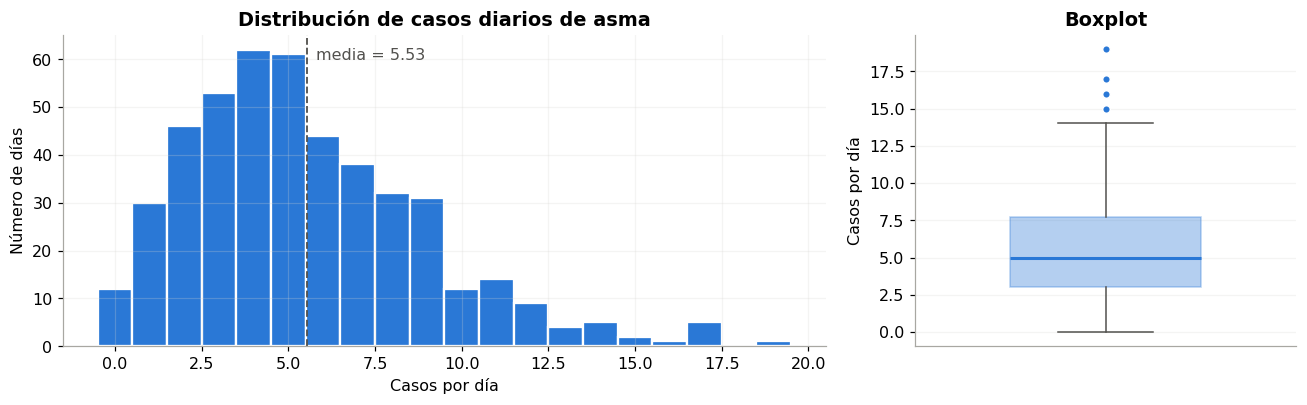

El índice de dispersión es **2.14**. Al ser mayor que 1, los conteos muestran **sobredispersión** respecto a un Poisson; un modelo de conteo debería considerar la binomial negativa. Un 2.6% de los días registra cero casos.

In [6]:
asma = df['asma']
prop_ceros = (asma == 0).mean()
indice_dispersion = asma.var() / asma.mean()
es_entera = bool(np.allclose(asma, asma.round()))

tabla_asma = pd.DataFrame({
    'Indicador': ['Media (casos/día)', 'Varianza', 'Índice de dispersión Var/Media',
                  'Días con cero casos', 'Proporción de días con cero casos',
                  '¿Valores enteros?'],
    'Valor': [f'{asma.mean():.2f}', f'{asma.var():.2f}', f'{indice_dispersion:.2f}',
              int((asma == 0).sum()), f'{prop_ceros:.1%}', 'Sí' if es_entera else 'No']})
display(tabla_asma)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1]})
bins = np.arange(asma.min() - 0.5, asma.max() + 1.5, 1)
axes[0].hist(asma, bins=bins, color=COLORES['asma'], edgecolor='white', linewidth=1.5)
axes[0].axvline(asma.mean(), color=GRIS, linestyle='--', linewidth=1.2)
axes[0].annotate(f'media = {asma.mean():.2f}', xy=(asma.mean(), axes[0].get_ylim()[1] * 0.92),
                 xytext=(6, 0), textcoords='offset points', color=GRIS)
axes[0].set(title='Distribución de casos diarios de asma', xlabel='Casos por día',
            ylabel='Número de días')
axes[1].boxplot(asma, vert=True, widths=0.5, patch_artist=True,
                boxprops=dict(facecolor=COLORES['asma'], alpha=0.35, edgecolor=COLORES['asma']),
                medianprops=dict(color=COLORES['asma'], linewidth=2),
                whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS),
                flierprops=dict(marker='o', markersize=5, markerfacecolor=COLORES['asma'],
                                markeredgecolor='white'))
axes[1].set(title='Boxplot', ylabel='Casos por día', xticks=[])
plt.tight_layout()
plt.show()

mostrar_md(
    f"El índice de dispersión es **{indice_dispersion:.2f}**. "
    + ("Al ser mayor que 1, los conteos muestran **sobredispersión** respecto a un Poisson; "
       "un modelo de conteo debería considerar la binomial negativa."
       if indice_dispersion > 1 else
       "No hay indicios de sobredispersión respecto a un Poisson.")
    + f" Un {prop_ceros:.1%} de los días registra cero casos.")

### 8.2 Variables ambientales y valores extremos

Se utiliza la regla descriptiva de Tukey (valores por fuera de $[Q_1 - 1.5\,RIC,\; Q_3 + 1.5\,RIC]$) **solo para describir**, no para eliminar.

> ⚠️ **No eliminamos outliers automáticamente.** Un pico de PM2.5 puede corresponder a un incendio forestal, un episodio de inversión térmica o una contingencia ambiental real; un día de lluvia intensa es un evento meteorológico, no un error. Precisamente esos eventos son los más relevantes para la vigilancia. Un valor extremo solo debe tratarse como error si existe evidencia (por ejemplo, una falla documentada del sensor).

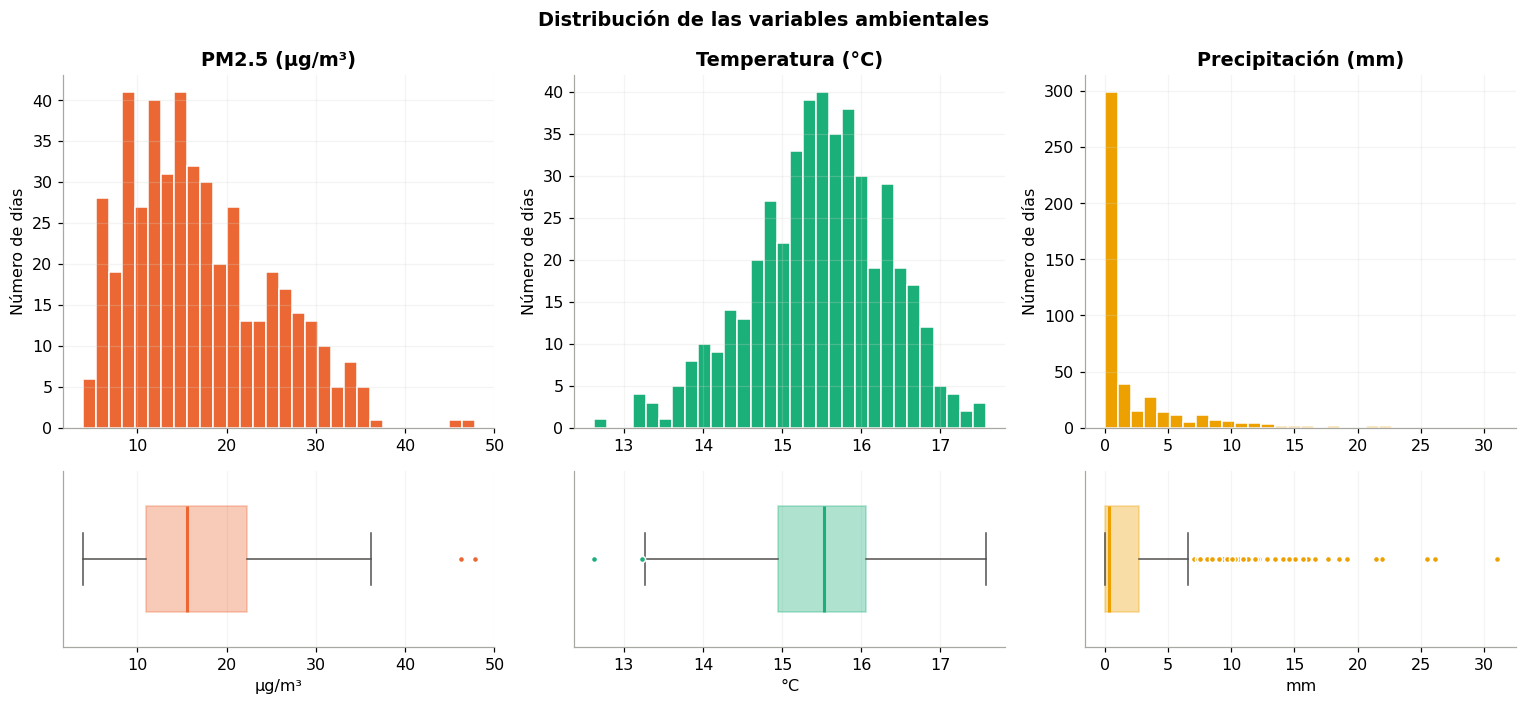

,Valla inferior,Valla superior,N.º bajo valla,N.º sobre valla,% días extremos,Tres valores máximos (fecha: valor)
Variable,,,,,,
Asma,-4.12,14.88,0,9,1.9%,2024-03-25: 19.0; 2023-03-21: 17.0; 2023-04-24...
PM2.5,-5.90,39.15,0,2,0.4%,2024-03-23: 47.8; 2024-03-22: 46.3; 2023-03-23...
Temperatura,13.27,17.74,2,0,0.4%,2024-03-13: 17.6; 2024-01-29: 17.5; 2024-03-24...
Precipitación,-4.00,6.68,0,53,11.5%,2024-03-20: 31.0; 2023-03-11: 26.1; 2023-09-22...


In [7]:
AMBIENTALES = ['pm25', 'temperatura', 'precipitacion']

fig, axes = plt.subplots(2, 3, figsize=(14, 6.5), gridspec_kw={'height_ratios': [2, 1]})
for j, col in enumerate(AMBIENTALES):
    s = df[col]
    axes[0, j].hist(s, bins=30, color=COLORES[col], edgecolor='white', linewidth=1)
    axes[0, j].set(title=f'{ETIQUETAS[col]} ({UNIDADES[col]})', ylabel='Número de días')
    axes[1, j].boxplot(s, vert=False, widths=0.6, patch_artist=True,
                       boxprops=dict(facecolor=COLORES[col], alpha=0.35, edgecolor=COLORES[col]),
                       medianprops=dict(color=COLORES[col], linewidth=2),
                       whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS),
                       flierprops=dict(marker='o', markersize=4, markerfacecolor=COLORES[col],
                                       markeredgecolor='white'))
    axes[1, j].set(yticks=[], xlabel=UNIDADES[col])
plt.suptitle('Distribución de las variables ambientales', fontweight='bold')
plt.tight_layout()
plt.show()


def extremos_tukey(data, variables):
    # Resumen descriptivo de valores fuera de las vallas de Tukey (no se eliminan).
    filas = []
    for col in variables:
        s = data[col]
        q1, q3 = s.quantile([0.25, 0.75])
        ric = q3 - q1
        inf, sup = q1 - 1.5 * ric, q3 + 1.5 * ric
        top = s.nlargest(3)
        filas.append({
            'Variable': ETIQUETAS[col], 'Valla inferior': round(inf, 2),
            'Valla superior': round(sup, 2), 'N.º bajo valla': int((s < inf).sum()),
            'N.º sobre valla': int((s > sup).sum()),
            '% días extremos': f'{((s < inf) | (s > sup)).mean():.1%}',
            'Tres valores máximos (fecha: valor)': '; '.join(
                f'{d.date()}: {v:.1f}' for d, v in top.items()),
        })
    return pd.DataFrame(filas).set_index('Variable')


display(extremos_tukey(df, VARIABLES))

**Lectura.** En variables muy asimétricas como la precipitación (muchos días secos y pocos días muy lluviosos) la regla de Tukey marca como "extremos" una fracción considerable de días: eso describe una **cola larga**, no errores de medición. Para PM2.5, los valores máximos deben contrastarse con los episodios de calidad del aire reportados por la autoridad ambiental antes de cualquier decisión.

## 9. Evolución temporal

Se muestra la **serie original** (trazo claro) junto con la **media móvil centrada de 7 días** (trazo oscuro).

La media móvil sirve para **visualizar** la dinámica de fondo filtrando la variación día a día y el patrón semanal. **No** se usa para ajustar el VAR: suavizar antes de modelar introduce autocorrelación artificial y mezcla información futura (una media centrada usa días posteriores).

### 🔎 Observe
> ¿La serie de asma muestra un posible patrón que se repite cada siete días? ¿Hay periodos con nivel claramente distinto (por ejemplo, temporada seca vs. lluviosa)?

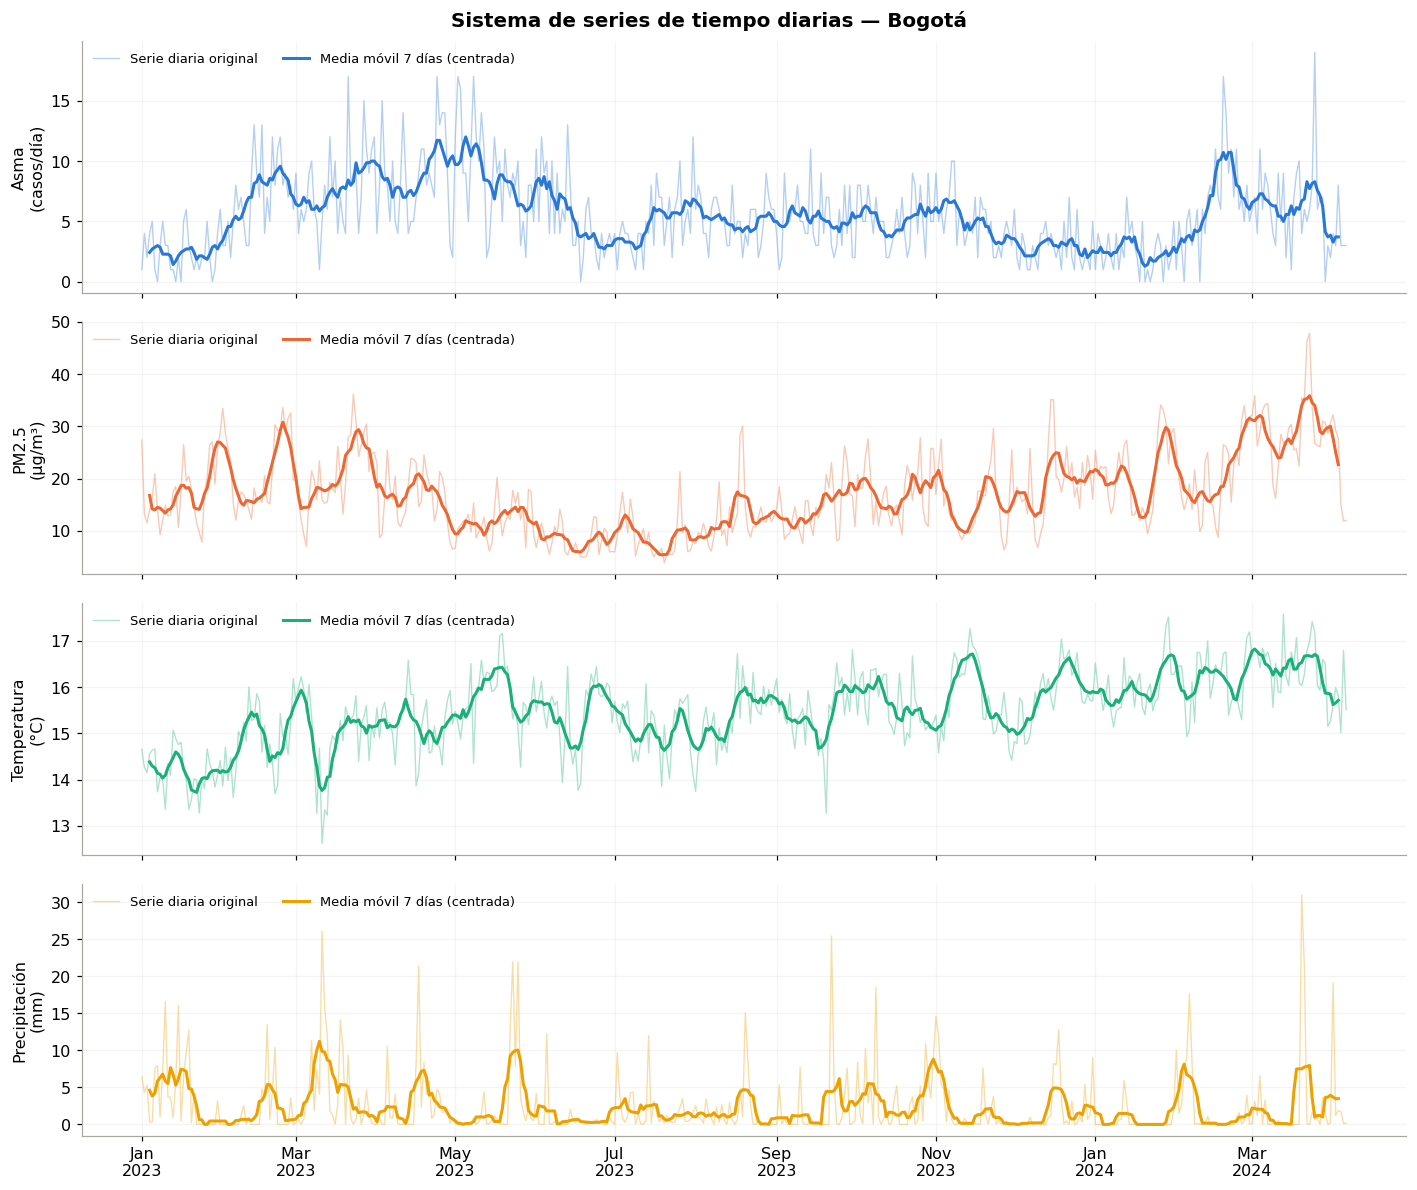

In [8]:
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True)
for ax, col in zip(axes, VARIABLES):
    ax.plot(df.index, df[col], color=COLORES[col], alpha=0.35, linewidth=0.9,
            label='Serie diaria original')
    ax.plot(df.index, df[col].rolling(7, center=True).mean(), color=COLORES[col],
            linewidth=2, label='Media móvil 7 días (centrada)')
    ax.set_ylabel(f'{ETIQUETAS[col]}\n({UNIDADES[col]})')
    ax.legend(loc='upper left', fontsize=8.5, frameon=False, ncol=2)
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.suptitle('Sistema de series de tiempo diarias — Bogotá', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Patrón semanal: ¿existe un patrón por día de semana?

Con datos diarios de servicios de salud es esperable una regularidad semanal. Si existe, debe tenerse en cuenta al elegir el número de rezagos (el rezago 7 conecta cada día con el mismo día de la semana anterior).

La variable `dia_semana` se agrega a una **copia** del DataFrame para no contaminar la matriz que entra al VAR.

,n,media_asma,mediana_asma,de_asma,media_pm25
dia_semana,,,,,
Lunes,66,6.95,6.0,4.32,15.46
Martes,66,6.70,6.0,3.74,16.97
Miércoles,66,6.33,6.5,3.08,18.05
Jueves,66,5.67,5.0,3.34,18.34
Viernes,66,4.92,5.0,2.69,18.87
Sábado,66,4.06,4.0,2.81,17.31
Domingo,66,4.05,3.0,2.60,13.99


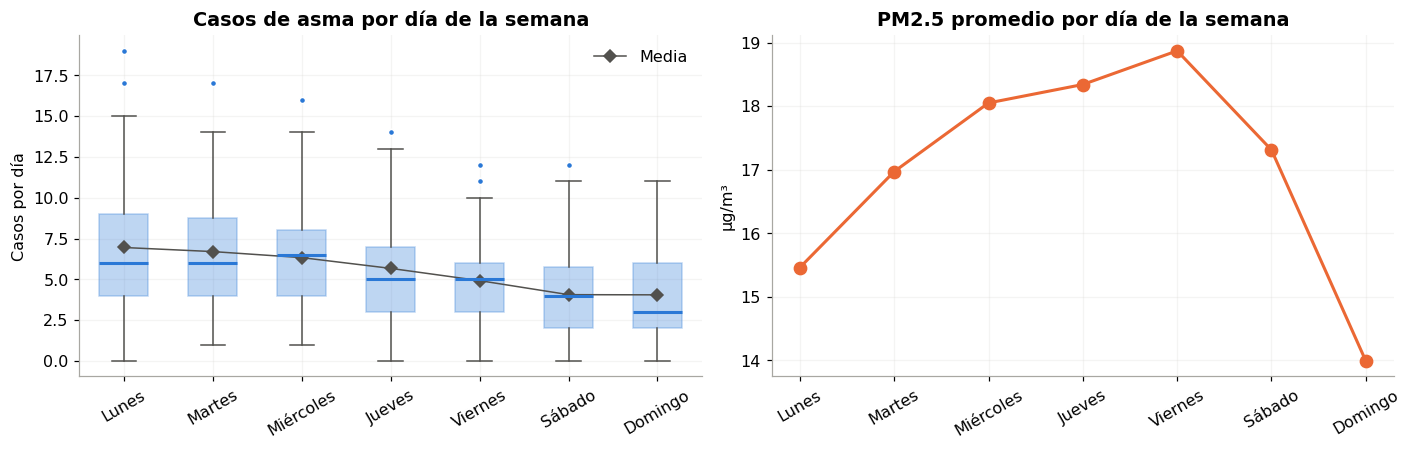

#### Resultado
El día con más casos promedio es **Lunes** (6.95) y el de menos es **Domingo** (4.05); razón máx/mín = 1.72. Prueba exploratoria de Kruskal–Wallis: H = 46.99, p = < 0.001.

#### Decisión estadística
Se rechaza la igualdad de distribuciones entre días de la semana (α = 0.05).

#### Interpretación epidemiológica
Un patrón semanal puede deberse a la epidemiología (exposición diferencial), al comportamiento de la población, al acceso y funcionamiento de los servicios (menos consultas en fin de semana), o a la notificación del sistema de vigilancia. Con estos datos **no podemos distinguir** entre esas explicaciones.

#### Precaución
Kruskal–Wallis supone observaciones independientes; con autocorrelación su valor p es solo orientativo. Lo relevante para el modelado es que un patrón semanal sugiere considerar al menos 7 rezagos o variables de calendario.

In [9]:
DIAS_ES = {'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles',
           'Thursday': 'Jueves', 'Friday': 'Viernes', 'Saturday': 'Sábado',
           'Sunday': 'Domingo'}
ORDEN_DIAS = list(DIAS_ES.values())

df_cal = df.copy()
df_cal['dia_semana'] = df_cal.index.day_name()
df_cal['dia_semana'] = pd.Categorical(df_cal['dia_semana'].map(DIAS_ES),
                                      categories=ORDEN_DIAS, ordered=True)

tabla_semana = (df_cal.groupby('dia_semana', observed=True)
                .agg(n=('asma', 'size'), media_asma=('asma', 'mean'),
                     mediana_asma=('asma', 'median'), de_asma=('asma', 'std'),
                     media_pm25=('pm25', 'mean'))
                .round(2))
display(tabla_semana)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
grupos = [df_cal.loc[df_cal['dia_semana'] == d, 'asma'] for d in ORDEN_DIAS]
axes[0].boxplot(grupos, patch_artist=True, widths=0.55,
                boxprops=dict(facecolor=COLORES['asma'], alpha=0.3, edgecolor=COLORES['asma']),
                medianprops=dict(color=COLORES['asma'], linewidth=2),
                whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS),
                flierprops=dict(marker='o', markersize=4, markerfacecolor=COLORES['asma'],
                                markeredgecolor='white'))
axes[0].plot(range(1, 8), tabla_semana['media_asma'], marker='D', color=GRIS,
             linewidth=1, markersize=6, label='Media')
axes[0].set_xticks(range(1, 8), ORDEN_DIAS)
axes[0].set(title='Casos de asma por día de la semana', ylabel='Casos por día')
axes[0].legend(frameon=False)
axes[0].tick_params(axis='x', rotation=30)

axes[1].plot(ORDEN_DIAS, tabla_semana['media_pm25'], marker='o', markersize=8,
             color=COLORES['pm25'], linewidth=2)
axes[1].set(title='PM2.5 promedio por día de la semana', ylabel='µg/m³')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

kw = stats.kruskal(*grupos)
dia_max = tabla_semana['media_asma'].idxmax()
dia_min = tabla_semana['media_asma'].idxmin()
razon = tabla_semana['media_asma'].max() / tabla_semana['media_asma'].min()
RES['patron_semanal_p'] = kw.pvalue
informe(
    resultado=(f"El día con más casos promedio es **{dia_max}** "
               f"({tabla_semana.loc[dia_max, 'media_asma']:.2f}) y el de menos es **{dia_min}** "
               f"({tabla_semana.loc[dia_min, 'media_asma']:.2f}); razón máx/mín = {razon:.2f}. "
               f"Prueba exploratoria de Kruskal–Wallis: H = {kw.statistic:.2f}, p = {fmt_p(kw.pvalue)}."),
    decision=("Se rechaza la igualdad de distribuciones entre días de la semana (α = 0.05)."
              if kw.pvalue < ALPHA else
              "No se rechaza la igualdad de distribuciones entre días de la semana (α = 0.05)."),
    epidemiologia=("Un patrón semanal puede deberse a la epidemiología (exposición diferencial), "
                   "al comportamiento de la población, al acceso y funcionamiento de los servicios "
                   "(menos consultas en fin de semana), o a la notificación del sistema de vigilancia. "
                   "Con estos datos **no podemos distinguir** entre esas explicaciones."),
    precaucion=("Kruskal–Wallis supone observaciones independientes; con autocorrelación su valor p "
                "es solo orientativo. Lo relevante para el modelado es que un patrón semanal sugiere "
                "considerar al menos 7 rezagos o variables de calendario."))

## 11. ACF y PACF: dependencia temporal de cada serie

- La **ACF** en el rezago $k$ mide la correlación entre $y_t$ y $y_{t-k}$ (incluyendo efectos indirectos a través de los rezagos intermedios).
- La **PACF** en el rezago $k$ mide la correlación entre $y_t$ y $y_{t-k}$ **descontando** los rezagos $1,\dots,k-1$.

Rezagos de especial interés en datos diarios de salud: **1 día** (persistencia inmediata), **2–3 días** (efectos de corto plazo), **7 días** (posible regularidad semanal) y **14 días** (repetición de la regularidad semanal o dinámica más lenta).

### 💡 Antes de ejecutar
> Si el número de consultas depende del día de la semana, ¿en qué rezagos esperaría picos en la ACF de asma?

> ⚠️ Un pico en el rezago 7 es un **indicio** de regularidad semanal, no una prueba. Debe contrastarse con el análisis por día de la semana y con el conocimiento del sistema de atención.

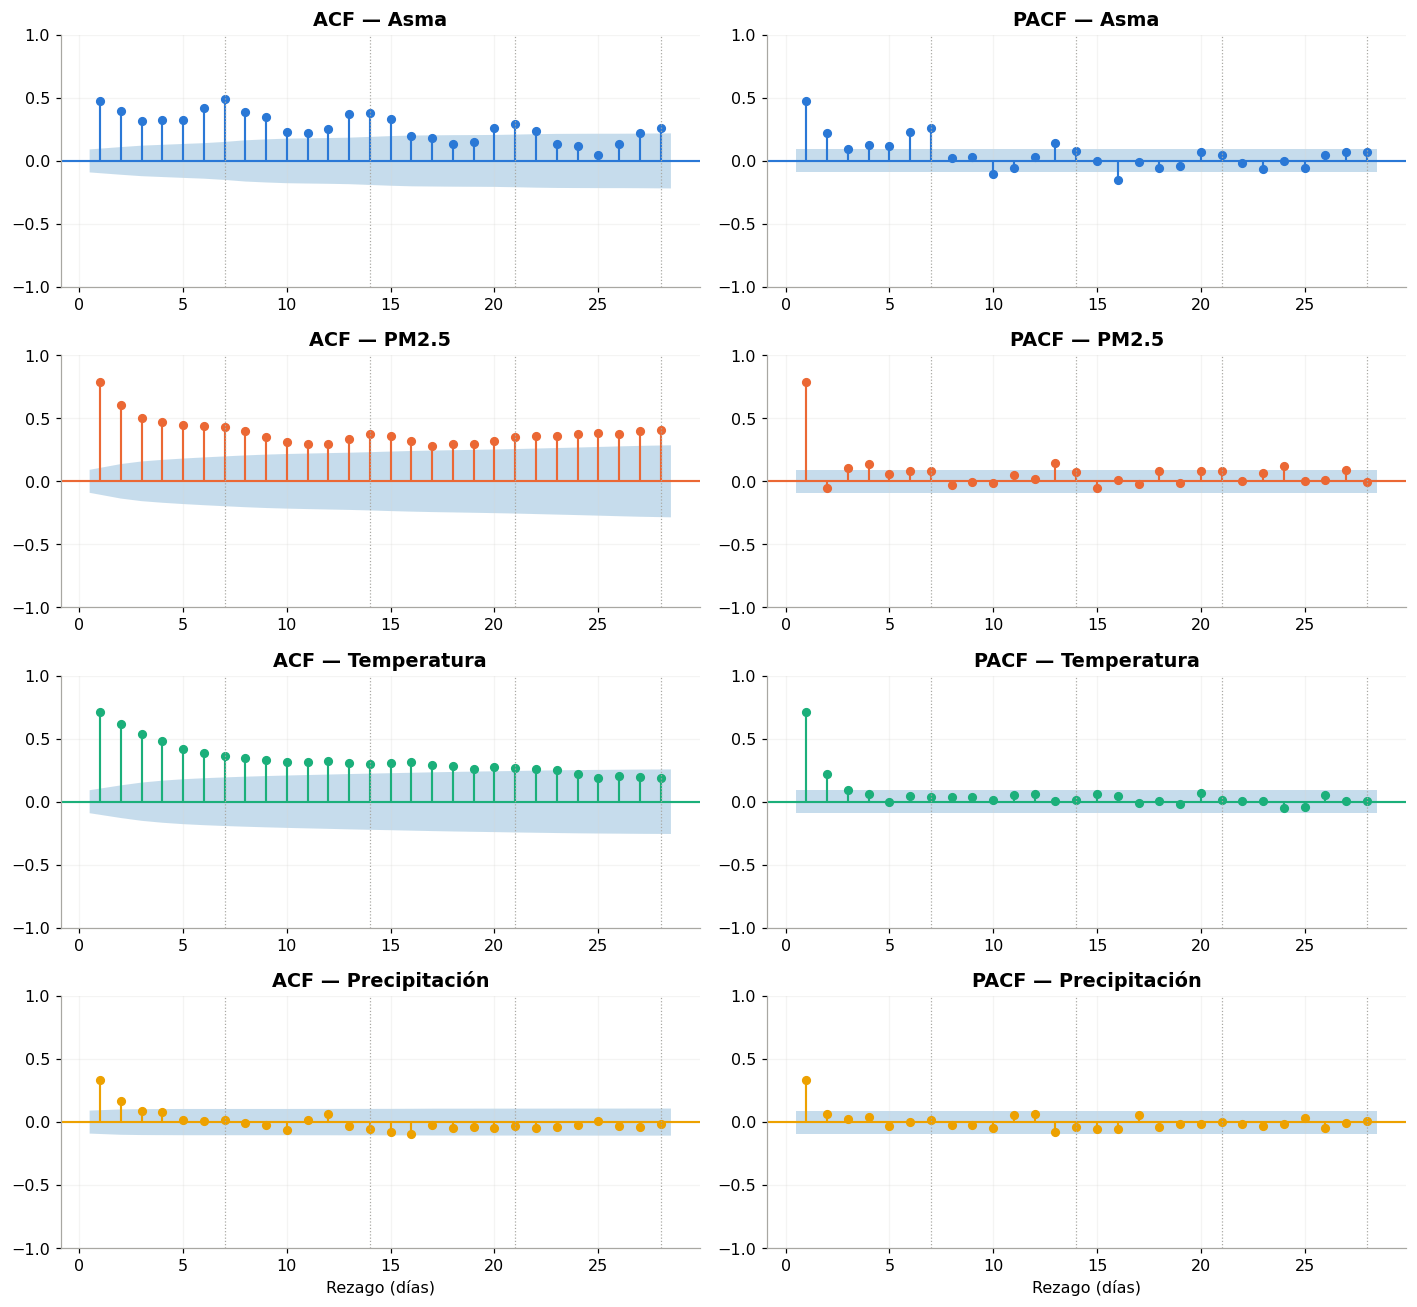

In [10]:
LAGS_ACF = 28
fig, axes = plt.subplots(4, 2, figsize=(13, 12))
for i, col in enumerate(VARIABLES):
    plot_acf(df[col], lags=LAGS_ACF, ax=axes[i, 0], color=COLORES[col],
             vlines_kwargs={'colors': COLORES[col]}, zero=False)
    plot_pacf(df[col], lags=LAGS_ACF, ax=axes[i, 1], color=COLORES[col],
              vlines_kwargs={'colors': COLORES[col]}, zero=False, method='ywm')
    axes[i, 0].set_title(f'ACF — {ETIQUETAS[col]}')
    axes[i, 1].set_title(f'PACF — {ETIQUETAS[col]}')
    for ax in axes[i]:
        for k in (7, 14, 21, 28):
            ax.axvline(k, color=GRIS_CLARO, linestyle=':', linewidth=0.8)
axes[-1, 0].set_xlabel('Rezago (días)')
axes[-1, 1].set_xlabel('Rezago (días)')
plt.tight_layout()
plt.show()

In [11]:
LAGS_CLAVE = [1, 2, 3, 7, 14]
banda = 1.96 / np.sqrt(len(df))
filas = []
for col in VARIABLES:
    a = acf(df[col], nlags=15)
    pa = pacf(df[col], nlags=15, method='ywm')
    fila = {'Variable': ETIQUETAS[col]}
    for k in LAGS_CLAVE:
        fila[f'ACF {k}'] = round(a[k], 3)
    for k in (1, 7):
        fila[f'PACF {k}'] = round(pa[k], 3)
    # ¿El rezago 7 es un máximo local de la ACF?
    fila['Pico local en rezago 7'] = 'Sí' if a[7] > a[6] and a[7] > a[8] and abs(a[7]) > banda else 'No'
    filas.append(fila)
tabla_acf = pd.DataFrame(filas).set_index('Variable')
display(tabla_acf)
print(f'Banda aproximada de significancia (±1.96/√n): ±{banda:.3f}')

pico_asma = tabla_acf.loc['Asma', 'Pico local en rezago 7'] == 'Sí'
RES['pico_acf7_asma'] = pico_asma
mostrar_md(
    f"**Asma:** ACF(1) = {tabla_acf.loc['Asma', 'ACF 1']:.3f}, ACF(7) = {tabla_acf.loc['Asma', 'ACF 7']:.3f}, "
    f"ACF(14) = {tabla_acf.loc['Asma', 'ACF 14']:.3f}. "
    + ("La ACF presenta un **máximo local en el rezago 7** que supera la banda: es un indicio "
       "de regularidad semanal coherente con el análisis por día de la semana."
       if pico_asma else
       "No se observa un máximo local en el rezago 7 que supere la banda.")
    + " La persistencia de la ACF en muchos rezagos indica que la serie tiene memoria: "
      "un modelo con pocos rezagos podría dejar dependencia sin capturar.")

,ACF 1,ACF 2,ACF 3,ACF 7,ACF 14,PACF 1,PACF 7,Pico local en rezago 7
Variable,,,,,,,,
Asma,0.472,0.396,0.321,0.491,0.383,0.472,0.261,Sí
PM2.5,0.790,0.604,0.500,0.434,0.377,0.790,0.083,No
Temperatura,0.711,0.613,0.540,0.363,0.296,0.711,0.037,No
Precipitación,0.331,0.164,0.090,0.018,-0.054,0.331,0.014,No


Banda aproximada de significancia (±1.96/√n): ±0.091


**Asma:** ACF(1) = 0.472, ACF(7) = 0.491, ACF(14) = 0.383. La ACF presenta un **máximo local en el rezago 7** que supera la banda: es un indicio de regularidad semanal coherente con el análisis por día de la semana. La persistencia de la ACF en muchos rezagos indica que la serie tiene memoria: un modelo con pocos rezagos podría dejar dependencia sin capturar.

## 12. Correlaciones contemporáneas

La matriz de correlación de Pearson mide

$$
\text{Corr}(X_t, Y_t),
$$

es decir, la asociación **el mismo día**. Es útil como primera mirada, pero **no responde** si $X_{t-k}$ **precede** a $Y_t$. Dos series pueden tener correlación contemporánea casi nula y, sin embargo, una puede anticipar a la otra con algunos días de rezago (o viceversa). Además, correlaciones entre series con tendencia o estacionalidad común pueden ser espurias.

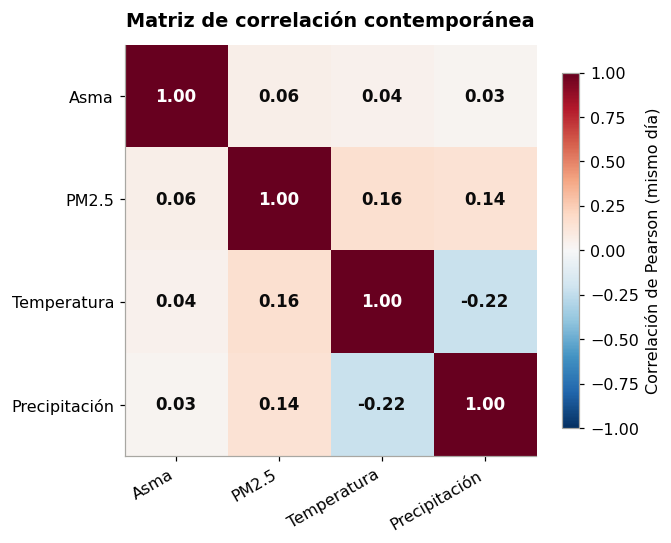

In [12]:
corr = df.corr()
etiquetas = [ETIQUETAS[c] for c in VARIABLES]

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)   # divergente, centro neutro en 0
cbar = plt.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label('Correlación de Pearson (mismo día)')
ax.set_xticks(range(4), etiquetas, rotation=30, ha='right')
ax.set_yticks(range(4), etiquetas)
ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=11,
                color='white' if abs(corr.iloc[i, j]) > 0.6 else '#0b0b0b', fontweight='bold')
ax.set_title('Matriz de correlación contemporánea', pad=12)
plt.tight_layout()
plt.show()

## 13. Correlaciones cruzadas: ¿la exposición precede al desenlace?

Calculamos, para $k = 0, 1, \dots, 14$:

$$
r_k = \text{Corr}(X_{t-k},\; Asma_t)
$$

**La dirección del rezago importa.** Con esta definición, un valor $r_k$ positivo y grande indica que valores altos de $X$ **hace $k$ días** tienden a acompañarse de más casos de asma **hoy**.

```
   PM2.5(t-3)  ──────────────►  Asma(t)
      │                            │
   día t-3      t-2      t-1     día t
```

`PM2.5(t-3) → asma(t)` significa explorar si el PM2.5 de **tres días antes** se asocia con el asma de **hoy**. En código: `df['asma'].corr(df['pm25'].shift(3))` (desplazar PM2.5 tres días hacia adelante en el calendario lo alinea con el asma de tres días después).

### Preblanqueo

Cuando ambas series están autocorrelacionadas, la correlación cruzada muestral tiene una varianza mucho mayor que $1/n$ y pueden aparecer picos espurios. Una solución clásica (Box–Jenkins) es **preblanquear**: ajustar un AR a $X$, filtrar **ambas** series con ese mismo filtro y calcular la correlación cruzada de las series filtradas. Mostramos ambas versiones.

### 💡 Antes de ejecutar
> Si PM2.5 afectara las exacerbaciones de asma con dos días de retraso, ¿qué esperaría observar en el gráfico? (Pista: un valor positivo que sobresalga de la banda en $k=2$, idealmente también tras el preblanqueo.)

> ⚠️ La correlación cruzada es **exploratoria**: no controla por las otras variables, ni por la autocorrelación del asma (en la versión cruda), ni por confusores. No demuestra causalidad.

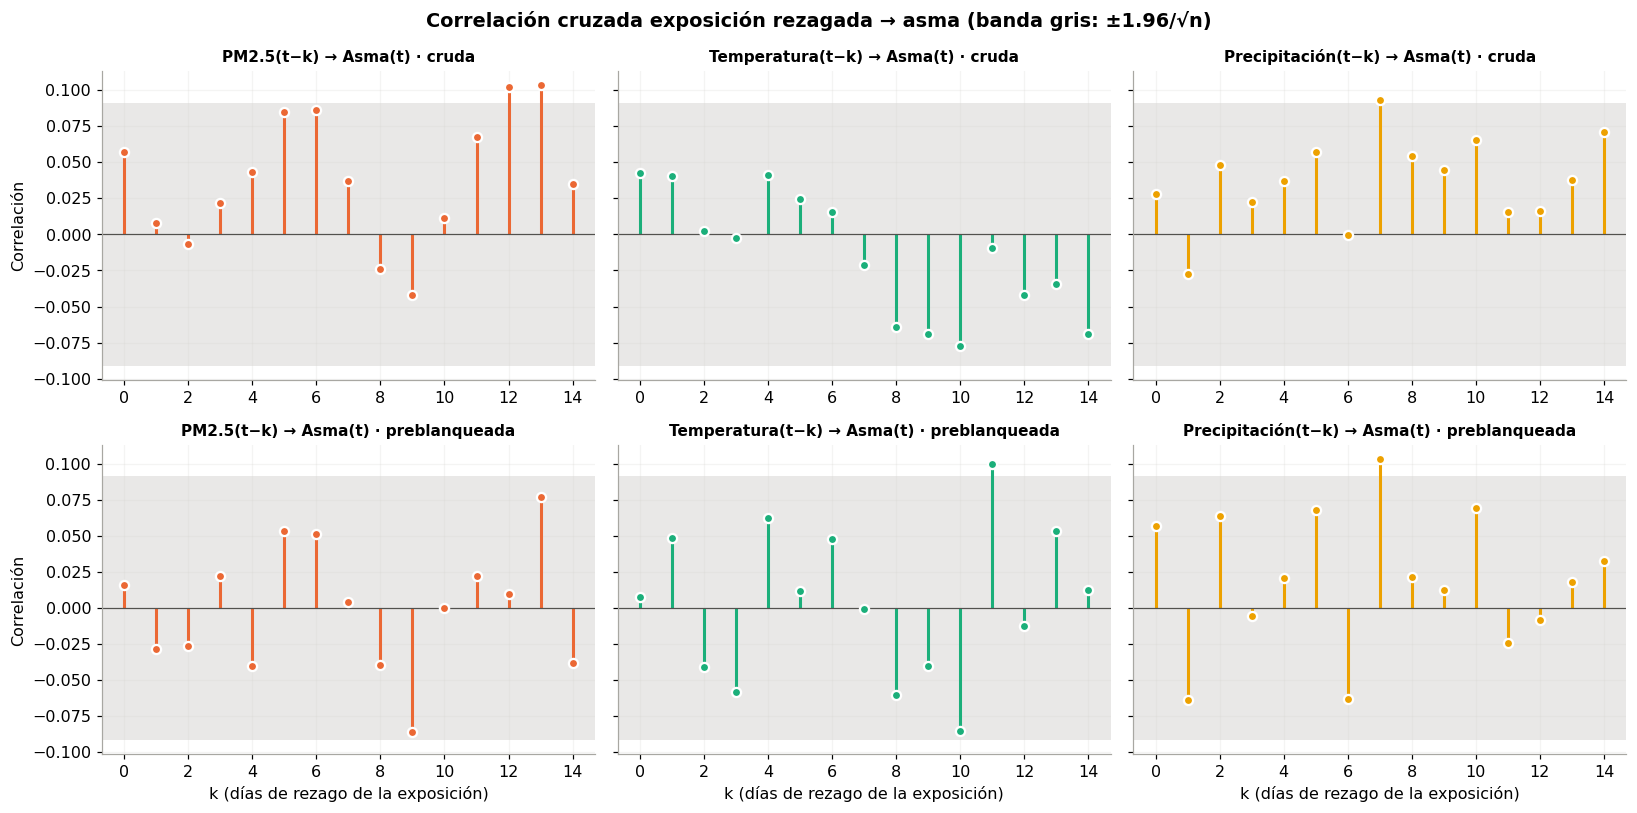

,PM2.5,PM2.5 (preblanq.),Temperatura,Temperatura (preblanq.),Precipitación,Precipitación (preblanq.)
k,,,,,,
0,0.057,0.016,0.043,0.008,0.028,0.057
1,0.008,-0.029,0.041,0.049,-0.027,-0.064
2,-0.007,-0.026,0.002,-0.041,0.048,0.064
3,0.022,0.022,-0.003,-0.058,0.023,-0.005
4,0.044,-0.040,0.041,0.063,0.037,0.021
5,0.085,0.054,0.024,0.011,0.057,0.068
6,0.086,0.051,0.015,0.048,-0.000,-0.063
7,0.037,0.004,-0.021,-0.001,0.093,0.103
8,-0.024,-0.040,-0.064,-0.060,0.055,0.022


In [13]:
MAX_LAG_CCF = 14
EXPOSICIONES = ['pm25', 'temperatura', 'precipitacion']


def correlacion_rezagada(x, y, max_lag=MAX_LAG_CCF):
    # r_k = Corr(x_{t-k}, y_t) para k = 0..max_lag.
    return pd.Series({k: y.corr(x.shift(k)) for k in range(max_lag + 1)}, name='r_k')


def preblanquear(x, y, orden=7):
    # Ajusta AR(orden) a x y aplica el MISMO filtro a x e y.
    phi = AutoReg(x, lags=orden, trend='c').fit().params.iloc[1:].values
    def filtro(s):
        out = s.copy()
        for i, ph in enumerate(phi, start=1):
            out = out - ph * s.shift(i)
        return out.iloc[orden:]
    return filtro(x), filtro(y)


fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey='row')
tabla_ccf = {}
for j, col in enumerate(EXPOSICIONES):
    cruda = correlacion_rezagada(df[col], df['asma'])
    xf, yf = preblanquear(df[col], df['asma'])
    preb = correlacion_rezagada(xf, yf)
    tabla_ccf[ETIQUETAS[col]] = cruda
    tabla_ccf[ETIQUETAS[col] + ' (preblanq.)'] = preb
    for fila, (serie, n_eff, titulo) in enumerate([(cruda, len(df), 'cruda'),
                                                  (preb, len(xf), 'preblanqueada')]):
        ax = axes[fila, j]
        b = 1.96 / np.sqrt(n_eff)
        ax.vlines(serie.index, 0, serie.values, color=COLORES[col], linewidth=2)
        ax.scatter(serie.index, serie.values, color=COLORES[col], s=36, zorder=3,
                   edgecolor='white', linewidth=1.5)
        ax.axhspan(-b, b, color=GRIS_CLARO, alpha=0.25, linewidth=0)
        ax.axhline(0, color=GRIS, linewidth=0.8)
        ax.set_title(f'{ETIQUETAS[col]}(t−k) → Asma(t) · {titulo}', fontsize=10)
        ax.set_xticks(range(0, MAX_LAG_CCF + 1, 2))
    axes[1, j].set_xlabel('k (días de rezago de la exposición)')
axes[0, 0].set_ylabel('Correlación')
axes[1, 0].set_ylabel('Correlación')
plt.suptitle('Correlación cruzada exposición rezagada → asma (banda gris: ±1.96/√n)',
             fontweight='bold')
plt.tight_layout()
plt.show()

tabla_ccf = pd.DataFrame(tabla_ccf).round(3)
tabla_ccf.index.name = 'k'
display(tabla_ccf)

In [14]:
filas = []
for col in EXPOSICIONES:
    xf, yf = preblanquear(df[col], df['asma'])
    preb = correlacion_rezagada(xf, yf)
    b = 1.96 / np.sqrt(len(xf))
    sig = preb[preb.abs() > b]
    filas.append({'Exposición → Asma': ETIQUETAS[col],
                  'Rezagos fuera de banda (preblanqueada)': ', '.join(map(str, sig.index)) or 'ninguno',
                  'k con |r| máximo': int(preb.abs().idxmax()),
                  'r en ese k': round(preb[preb.abs().idxmax()], 3)})
tabla_ccf_resumen = pd.DataFrame(filas).set_index('Exposición → Asma')
display(tabla_ccf_resumen)
esperados = 0.05 * (MAX_LAG_CCF + 1)
mostrar_md(
    f"Con {MAX_LAG_CCF + 1} rezagos evaluados por exposición y bandas al 95 %, se esperan "
    f"en promedio **{esperados:.2f} rezagos fuera de banda por azar** aun sin ninguna relación. "
    "Un rezago aislado fuera de banda, sin patrón coherente en rezagos vecinos, debe interpretarse con mucha cautela.")

,Rezagos fuera de banda (preblanqueada),k con |r| máximo,r en ese k
Exposición → Asma,,,
PM2.5,ninguno,9,-0.087
Temperatura,11,11,0.100
Precipitación,7,7,0.103


Con 15 rezagos evaluados por exposición y bandas al 95 %, se esperan en promedio **0.75 rezagos fuera de banda por azar** aun sin ninguna relación. Un rezago aislado fuera de banda, sin patrón coherente en rezagos vecinos, debe interpretarse con mucha cautela.

## 14. Estacionariedad

### 14.1 Dos pruebas con hipótesis nulas opuestas

| Prueba | $H_0$ | $H_1$ | Rechazar $H_0$ sugiere |
|---|---|---|---|
| **ADF** (Dickey–Fuller aumentada) | La serie tiene **raíz unitaria** (no estacionaria) | Estacionaria | Estacionariedad |
| **KPSS** | La serie es **estacionaria** (en nivel o alrededor de tendencia) | Raíz unitaria | No estacionariedad |

Combinaciones posibles:

| ADF | KPSS | Lectura |
|---|---|---|
| Rechaza | No rechaza | Ambas coinciden: compatible con estacionariedad |
| No rechaza | Rechaza | Ambas coinciden: evidencia de raíz unitaria |
| Rechaza | Rechaza | **Conflicto**: no hay raíz unitaria, pero tampoco estacionariedad "limpia" en nivel. Típico de tendencias, ciclos lentos, cambios de nivel o memoria larga |
| No rechaza | No rechaza | **Inconcluso**: baja potencia; los datos no discriminan |

> **Un conflicto no se resuelve diferenciando automáticamente.** Diferenciar una serie que no tiene raíz unitaria introduce un componente MA no invertible, destruye la información de nivel (relevante en vigilancia) y complica la interpretación. El conflicto exige análisis adicional: gráficos, tendencia, estacionalidad, ACF, estabilidad de media y varianza y conocimiento del proceso.

**Detalle técnico.** `statsmodels` interpola el valor *p* de KPSS en una tabla que solo cubre el intervalo [0.01, 0.10]. Si el estadístico cae fuera, el *p* reportado es el extremo de la tabla y se emite una `InterpolationWarning`. Capturamos esa advertencia de forma local y la reportamos como "≤ 0.01" o "≥ 0.10".

Se aplican las pruebas con **constante** (especificación principal, igual al notebook original) y, como análisis complementario, con **constante y tendencia lineal**.

In [15]:
def kpss_con_aviso(serie, regression):
    # Ejecuta KPSS capturando localmente la InterpolationWarning para reportar p acotado.
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter('always', InterpolationWarning)
        estad, p, *_ = kpss(serie, regression=regression, nlags='auto')
    fuera_tabla = any(issubclass(a.category, InterpolationWarning) for a in avisos)
    if fuera_tabla:
        texto = '≤ 0.01' if p <= 0.01 else '≥ 0.10'
    else:
        texto = fmt_p(p)
    return estad, p, texto


def diagnostico_integrado(adf_rechaza, kpss_rechaza, kpss_ct_rechaza):
    # Texto de diagnóstico según la combinación de resultados (sin decisiones automáticas).
    if adf_rechaza and not kpss_rechaza:
        return 'Coinciden: compatible con estacionariedad en nivel.'
    if not adf_rechaza and kpss_rechaza:
        return 'Coinciden: evidencia de raíz unitaria; considerar diferenciar.'
    if adf_rechaza and kpss_rechaza:
        extra = (' Con tendencia, KPSS no rechaza: compatible con estacionariedad alrededor de una tendencia/ciclo lento.'
                 if not kpss_ct_rechaza else
                 ' Con tendencia, KPSS sigue rechazando: posible ciclo lento, cambio de nivel o memoria larga.')
        return 'Conflicto: ADF descarta raíz unitaria, KPSS rechaza estacionariedad en nivel.' + extra
    return 'Inconcluso: ninguna prueba rechaza (baja potencia).'


def tabla_estacionariedad(data, alpha=ALPHA):
    filas = []
    for col in VARIABLES:
        s = data[col]
        adf_c = adfuller(s, regression='c', autolag='BIC')
        adf_ct = adfuller(s, regression='ct', autolag='BIC')
        _, kp_c, kp_c_txt = kpss_con_aviso(s, 'c')
        _, kp_ct, kp_ct_txt = kpss_con_aviso(s, 'ct')
        adf_rech = adf_c[1] < alpha
        kpss_rech = kp_c < alpha
        filas.append({
            'Variable': ETIQUETAS[col],
            'ADF p': fmt_p(adf_c[1]), 'KPSS p': kp_c_txt,
            'Resultado ADF': 'Rechaza H₀ (no raíz unitaria)' if adf_rech else 'No rechaza H₀',
            'Resultado KPSS': 'Rechaza H₀ (no estacionaria)' if kpss_rech else 'No rechaza H₀',
            'ADF p (c+t)': fmt_p(adf_ct[1]), 'KPSS p (c+t)': kp_ct_txt,
            'Diagnóstico integrado': diagnostico_integrado(adf_rech, kpss_rech, kp_ct < alpha),
            '_adf_rechaza': adf_rech, '_kpss_rechaza': kpss_rech,
            '_adf_ct_rechaza': adf_ct[1] < alpha,
        })
    return pd.DataFrame(filas).set_index('Variable')


tabla_est = tabla_estacionariedad(df)
with pd.option_context('display.max_colwidth', None):
    display(tabla_est.drop(columns=[c for c in tabla_est if c.startswith('_')]))

,ADF p,KPSS p,Resultado ADF,Resultado KPSS,ADF p (c+t),KPSS p (c+t),Diagnóstico integrado
Variable,,,,,,,
Asma,0.027,0.019,Rechaza H₀ (no raíz unitaria),Rechaza H₀ (no estacionaria),0.054,≤ 0.01,"Conflicto: ADF descarta raíz unitaria, KPSS rechaza estacionariedad en nivel. Con tendencia, KPSS sigue rechazando: posible ciclo lento, cambio de nivel o memoria larga."
PM2.5,< 0.001,≤ 0.01,Rechaza H₀ (no raíz unitaria),Rechaza H₀ (no estacionaria),< 0.001,≤ 0.01,"Conflicto: ADF descarta raíz unitaria, KPSS rechaza estacionariedad en nivel. Con tendencia, KPSS sigue rechazando: posible ciclo lento, cambio de nivel o memoria larga."
Temperatura,< 0.001,≤ 0.01,Rechaza H₀ (no raíz unitaria),Rechaza H₀ (no estacionaria),< 0.001,≥ 0.10,"Conflicto: ADF descarta raíz unitaria, KPSS rechaza estacionariedad en nivel. Con tendencia, KPSS no rechaza: compatible con estacionariedad alrededor de una tendencia/ciclo lento."
Precipitación,< 0.001,≥ 0.10,Rechaza H₀ (no raíz unitaria),No rechaza H₀,< 0.001,≥ 0.10,Coinciden: compatible con estacionariedad en nivel.


### 14.2 Evidencia complementaria: media y varianza a lo largo del tiempo

Si una serie es estacionaria, su media y su varianza deberían ser aproximadamente constantes. Se grafican la media y la desviación estándar móviles de 30 días, y se comparan la primera y la segunda mitad del periodo.

> **Contexto del proceso.** El periodo cubre algo más de un año. En Bogotá, PM2.5 suele aumentar en la temporada seca de inicio de año, y la precipitación sigue un régimen bimodal. Con menos de dos ciclos anuales observados, una estacionalidad anual puede parecer, para las pruebas, una "tendencia" o un cambio de nivel. Esto **no** es lo mismo que una raíz unitaria.

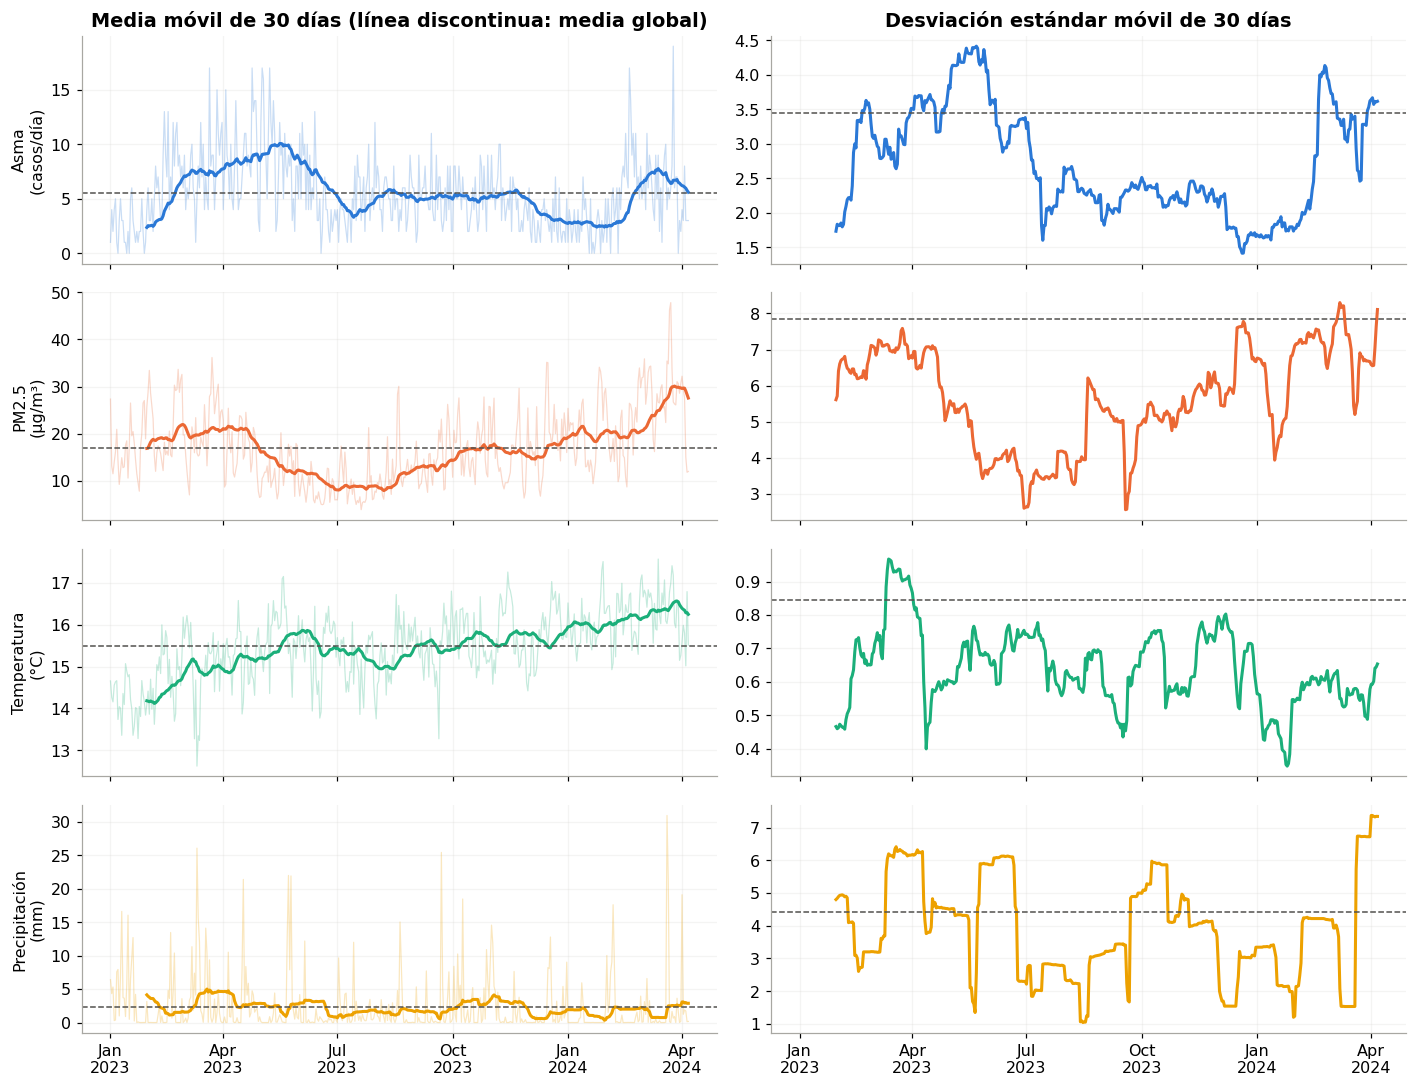

,Media 1.ª mitad,Media 2.ª mitad,DE 1.ª mitad,DE 2.ª mitad,Pendiente lineal (por 100 días)
Variable,,,,,
Asma,6.303,4.749,3.758,2.901,-0.451
PM2.5,14.778,19.217,7.231,7.820,1.558
Temperatura,15.077,15.887,0.803,0.677,0.369
Precipitación,2.549,2.096,4.399,4.452,-0.313


In [16]:
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharex=True)
for i, col in enumerate(VARIABLES):
    s = df[col]
    axes[i, 0].plot(s.index, s, color=COLORES[col], alpha=0.25, linewidth=0.8)
    axes[i, 0].plot(s.index, s.rolling(30).mean(), color=COLORES[col], linewidth=2)
    axes[i, 0].axhline(s.mean(), color=GRIS, linestyle='--', linewidth=1)
    axes[i, 0].set_ylabel(f'{ETIQUETAS[col]}\n({UNIDADES[col]})')
    axes[i, 1].plot(s.index, s.rolling(30).std(), color=COLORES[col], linewidth=2)
    axes[i, 1].axhline(s.std(), color=GRIS, linestyle='--', linewidth=1)
axes[0, 0].set_title('Media móvil de 30 días (línea discontinua: media global)')
axes[0, 1].set_title('Desviación estándar móvil de 30 días')
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
plt.tight_layout()
plt.show()

mitad = len(df) // 2
filas = []
for col in VARIABLES:
    s = df[col]
    pendiente = np.polyfit(np.arange(len(s)), s.values, 1)[0] * 100
    filas.append({'Variable': ETIQUETAS[col],
                  'Media 1.ª mitad': s.iloc[:mitad].mean(), 'Media 2.ª mitad': s.iloc[mitad:].mean(),
                  'DE 1.ª mitad': s.iloc[:mitad].std(), 'DE 2.ª mitad': s.iloc[mitad:].std(),
                  'Pendiente lineal (por 100 días)': pendiente})
display(pd.DataFrame(filas).set_index('Variable').round(3))

### 14.3 Decisión de trabajo

La decisión **no** se toma por una sola prueba. El criterio que seguiremos es:

1. Si ADF **no** rechaza la raíz unitaria y KPSS rechaza la estacionariedad para una variable, se considera diferenciarla.
2. Si ADF rechaza la raíz unitaria (aunque KPSS también rechace), se mantiene en **niveles**: el conflicto se atribuye a ciclos lentos, estacionalidad o cambios de nivel, se documenta como limitación y se verifica después que el VAR estimado sea **estable**.
3. Se reporta además la especificación con tendencia como análisis de sensibilidad (sección 22).

El mensaje siguiente se genera a partir de los resultados de la tabla.

In [17]:
conflictos = tabla_est.index[tabla_est['_adf_rechaza'] & tabla_est['_kpss_rechaza']].tolist()
coinciden = tabla_est.index[tabla_est['_adf_rechaza'] & ~tabla_est['_kpss_rechaza']].tolist()
raiz_unit = tabla_est.index[~tabla_est['_adf_rechaza'] & tabla_est['_kpss_rechaza']].tolist()
inconclusas = tabla_est.index[~tabla_est['_adf_rechaza'] & ~tabla_est['_kpss_rechaza']].tolist()
adf_ct_no_rechaza = tabla_est.index[~tabla_est['_adf_ct_rechaza']].tolist()

MODELAR_EN_NIVELES = len(raiz_unit) == 0
RES['est_conflictos'] = conflictos
RES['est_coinciden'] = coinciden
RES['est_raiz_unitaria'] = raiz_unit
RES['est_adf_ct_no_rechaza'] = adf_ct_no_rechaza
RES['niveles'] = MODELAR_EN_NIVELES

lista = lambda xs: ', '.join(xs) if xs else 'ninguna'
informe(
    resultado=(f"Ambas pruebas coinciden en estacionariedad para: **{lista(coinciden)}**. "
               f"Presentan conflicto ADF/KPSS: **{lista(conflictos)}**. "
               f"Evidencia coincidente de raíz unitaria: **{lista(raiz_unit)}**. "
               f"Inconclusas: **{lista(inconclusas)}**. "
               f"Con constante y tendencia, ADF no rechaza la raíz unitaria para: **{lista(adf_ct_no_rechaza)}**."),
    decision=("Ninguna variable cumple el criterio para diferenciar (ADF no rechaza y KPSS rechaza). "
              "Se modelan las cuatro series **en niveles**, documentando que la evidencia de estacionariedad "
              "es **mixta** para las variables con conflicto."
              if MODELAR_EN_NIVELES else
              f"Las variables {lista(raiz_unit)} muestran evidencia coincidente de raíz unitaria: "
              "deberían diferenciarse (o evaluarse cointegración/VECM) antes de un VAR en niveles."),
    epidemiologia=("No es correcto afirmar que 'las cuatro series son estacionarias'. Lo que muestran los datos es "
                   "que, en general, no hay evidencia de raíz unitaria con la especificación principal, pero sí de "
                   "variaciones de nivel lentas (por ejemplo, temporadas secas/lluviosas, periodos de mayor "
                   "circulación de virus respiratorios) que un periodo corto no permite separar de una tendencia."),
    precaucion=("El resultado de ADF con tendencia y de KPSS indica que esta decisión es una **aproximación de trabajo**. "
                "Debe verificarse la estabilidad del VAR (sección 20) y revisarse la sensibilidad de las conclusiones "
                "a incluir una tendencia determinística (sección 22). Con más años de datos convendría modelar "
                "explícitamente la estacionalidad anual."))

#### Resultado
Ambas pruebas coinciden en estacionariedad para: **Precipitación**. Presentan conflicto ADF/KPSS: **Asma, PM2.5, Temperatura**. Evidencia coincidente de raíz unitaria: **ninguna**. Inconclusas: **ninguna**. Con constante y tendencia, ADF no rechaza la raíz unitaria para: **Asma**.

#### Decisión estadística
Ninguna variable cumple el criterio para diferenciar (ADF no rechaza y KPSS rechaza). Se modelan las cuatro series **en niveles**, documentando que la evidencia de estacionariedad es **mixta** para las variables con conflicto.

#### Interpretación epidemiológica
No es correcto afirmar que 'las cuatro series son estacionarias'. Lo que muestran los datos es que, en general, no hay evidencia de raíz unitaria con la especificación principal, pero sí de variaciones de nivel lentas (por ejemplo, temporadas secas/lluviosas, periodos de mayor circulación de virus respiratorios) que un periodo corto no permite separar de una tendencia.

#### Precaución
El resultado de ADF con tendencia y de KPSS indica que esta decisión es una **aproximación de trabajo**. Debe verificarse la estabilidad del VAR (sección 20) y revisarse la sensibilidad de las conclusiones a incluir una tendencia determinística (sección 22). Con más años de datos convendría modelar explícitamente la estacionalidad anual.

## 15. Especificación del VAR

$$
\begin{bmatrix} Asma_t\\ PM2.5_t\\ Temp_t\\ Prec_t \end{bmatrix}
=
\mathbf{c}
+ \sum_{i=1}^{p} A_i
\begin{bmatrix} Asma_{t-i}\\ PM2.5_{t-i}\\ Temp_{t-i}\\ Prec_{t-i} \end{bmatrix}
+
\begin{bmatrix} \varepsilon_{1t}\\ \varepsilon_{2t}\\ \varepsilon_{3t}\\ \varepsilon_{4t} \end{bmatrix}
$$

**Todas las variables son endógenas.** Esto significa que el modelo estima cuatro ecuaciones, incluida, por ejemplo:

$$
Prec_t = c_4 + \sum_{i=1}^{p} \left( a^{(i)}_{41} Asma_{t-i} + a^{(i)}_{42} PM2.5_{t-i} + a^{(i)}_{43} Temp_{t-i} + a^{(i)}_{44} Prec_{t-i} \right) + \varepsilon_{4t}
$$

### 🧠 Pregunta pedagógica
> ¿Tiene sentido epidemiológico considerar los casos de asma como determinantes futuros de PM2.5?

En general **no**: los casos de asma no modifican la calidad del aire ni el clima. La **simetría** del VAR es una fortaleza en sistemas genuinamente interdependientes (por ejemplo, inflación, tasa de interés y desempleo), pero en epidemiología ambiental puede ser una **limitación conceptual**:

- se gastan parámetros en ecuaciones sin sentido sustantivo;
- una prueba de Granger "asma → PM2.5" significativa sería casi con seguridad reflejo de un factor común (estacionalidad, calendario), no de un mecanismo;
- una alternativa más coherente sería un modelo con las variables ambientales como **exógenas** (VARX o regresión de conteo con rezagos distribuidos).

Mantendremos el VAR completo porque el objetivo es aprender la herramienta, y usaremos precisamente las pruebas en "dirección inversa" como **control de plausibilidad**.

**Términos deterministas:** se incluye una constante (`trend='c'`), consistente con la decisión de modelar en niveles. La versión con tendencia se usa como sensibilidad.

In [18]:
# Separación temporal (nunca aleatoria): selección | validación | prueba
df_sel = df.iloc[:-N_TEST]            # datos disponibles para seleccionar p (excluye el test)
inicio_val = len(df_sel) - N_VAL      # índice (dentro de df_sel) donde empieza la validación

tabla_split = pd.DataFrame({
    'Conjunto': ['Selección / estimación', '  └─ de los cuales: validación (pronóstico rodante)',
                 'Prueba final (reservada)'],
    'Desde': [df_sel.index[0].date(), df_sel.index[inicio_val].date(), df.index[-N_TEST].date()],
    'Hasta': [df_sel.index[-1].date(), df_sel.index[-1].date(), df.index[-1].date()],
    'Días': [len(df_sel), N_VAL, N_TEST]})
display(tabla_split)

,Conjunto,Desde,Hasta,Días
0,Selección / estimación,2023-01-01,2024-03-07,432
1,└─ de los cuales: validación (pronóstico rod...,2024-02-07,2024-03-07,30
2,Prueba final (reservada),2024-03-08,2024-04-06,30


**¿Por qué tres conjuntos?** Si eligiéramos $p$ mirando el error en los últimos 30 días y luego reportáramos ese mismo error como "desempeño fuera de muestra", la evaluación sería optimista. Por eso:

- $p$ se elige con criterios de información, diagnóstico y error en un **periodo de validación**;
- los **últimos 30 días** se reservan y solo se usan en la sección 26 para la evaluación final.

## 16. Selección de rezagos

`select_order` estima VAR(0), …, VAR(15) sobre una **muestra común** (descartando las primeras 15 observaciones) para que los criterios sean comparables.

> Un criterio de información **no** debe interpretarse de manera mecánica. Los criterios comparan ajuste penalizado dentro de la muestra; no garantizan residuos sin autocorrelación, ni buen pronóstico, ni coherencia con la estructura temporal de los datos (por ejemplo, el ciclo semanal).

In [19]:
MAX_LAGS = 15
modelo_sel = VAR(df_sel)
seleccion = modelo_sel.select_order(maxlags=MAX_LAGS)
print(seleccion.summary())

criterios = {'AIC': seleccion.aic, 'BIC': seleccion.bic, 'HQIC': seleccion.hqic, 'FPE': seleccion.fpe}
display(pd.DataFrame({'Criterio': list(criterios), 'p sugerido': list(criterios.values())}))

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0        8.783       8.822       6526.       8.799
1        6.854      7.048*       947.9       6.931
2        6.763       7.111       865.3      6.901*
3        6.767       7.270       868.7       6.966
4        6.734       7.391       840.4       6.994
5        6.757       7.570       860.6       7.079
6        6.761       7.728       863.6       7.143
7       6.696*       7.818      809.7*       7.139
8        6.730       8.006       837.8       7.234
9        6.768       8.199       871.0       7.334
10       6.792       8.378       893.3       7.419
11       6.826       8.567       924.9       7.515
12       6.884       8.779       980.6       7.633
13       6.896       8.947       994.1       7.707
14       6.899       9.104       998.4       7.771
15       6.913       9.273       1013.       7.846
-------------------------------

,Criterio,p sugerido
0,AIC,7
1,BIC,1
2,HQIC,2
3,FPE,7


In [20]:
CANDIDATOS = sorted({1, 2, 7, seleccion.aic, seleccion.bic, seleccion.hqic} - {0})
mostrar_md(
    f"Los criterios no coinciden: AIC sugiere p = {seleccion.aic}, BIC sugiere p = {seleccion.bic} y "
    f"HQIC sugiere p = {seleccion.hqic}. Se comparan formalmente los candidatos **{CANDIDATOS}** "
    "(siempre se incluyen 1, 2 y 7; el rezago 7 por tratarse de datos diarios con posible dinámica semanal).")

Los criterios no coinciden: AIC sugiere p = 7, BIC sugiere p = 1 y HQIC sugiere p = 2. Se comparan formalmente los candidatos **[1, 2, 7]** (siempre se incluyen 1, 2 y 7; el rezago 7 por tratarse de datos diarios con posible dinámica semanal).

## 17. Comparación VAR(1), VAR(2) y VAR(7)

Para cada candidato se calcula:

| Criterio | Qué mide | Cómo se calcula aquí |
|---|---|---|
| AIC, BIC, HQIC | Ajuste penalizado | Todos los modelos sobre la **misma muestra efectiva** |
| Estabilidad | Que los shocks se disipen | Raíces del polinomio característico |
| Portmanteau (rezago 20) | Autocorrelación residual multivariada | `test_whiteness`; $H_0$: sin autocorrelación |
| Ljung–Box asma (rezagos 7 y 14) | Autocorrelación en la ecuación de interés | Aproximado (sin corregir grados de libertad) |
| Parámetros | Complejidad | $k(1+kp)$ |
| RMSE / MAE de validación | Desempeño predictivo fuera de muestra | Pronóstico rodante con ventana expansiva, re-estimando el VAR cada día |

**Pronóstico rodante (origen móvil).** Para cada día $t$ de la validación se estima el VAR con todos los datos hasta $t-h$ y se pronostica $h$ días adelante. Así se imita el uso real en vigilancia: cada mañana se actualiza el modelo con la información disponible. Se evalúan $h = 1$ (mañana) y $h = 7$ (una semana adelante).

In [21]:
def pronostico_rodante_var(data, p, inicio, fin, h=1, variable='asma', trend='c'):
    # Pronóstico h pasos adelante con origen móvil y ventana expansiva.
    # Para cada posición t en [inicio, fin) se estima el VAR con data.iloc[:t-h+1]
    # (información disponible hasta t-h) y se guarda el pronóstico para t.
    j = data.columns.get_loc(variable)
    preds = []
    for t in range(inicio, fin):
        historia = data.iloc[:t - h + 1]
        res = VAR(historia).fit(p, trend=trend)
        preds.append(res.forecast(historia.values[-p:], steps=h)[-1, j])
    return pd.Series(preds, index=data.index[inicio:fin], name=f'VAR({p})')


def pronosticos_referencia(y, inicio, fin, h=1):
    # Modelos de referencia con la misma información disponible (hasta t-h).
    idx = y.index[inicio:fin]
    v = y.values
    paso_sem = 7 * int(np.ceil(h / 7))
    ref = {'Naïve (ŷ = último valor)': [v[t - h] for t in range(inicio, fin)]}
    if paso_sem != h:   # con h = 7 el naïve semanal coincide con el naïve: no se duplica
        ref['Naïve semanal (ŷ = mismo día semana anterior)'] = [v[t - paso_sem] for t in range(inicio, fin)]
    ref['Media móvil 7 días'] = [v[t - h - 6:t - h + 1].mean() for t in range(inicio, fin)]
    ref['Media histórica'] = [v[:t - h + 1].mean() for t in range(inicio, fin)]
    return pd.DataFrame(ref, index=idx)


def metricas(y_obs, y_pred):
    # MAE, RMSE y WAPE (no se usa MAPE como principal por la presencia de ceros).
    e = np.asarray(y_obs) - np.asarray(y_pred)
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'WAPE': np.sum(np.abs(e)) / np.sum(np.abs(y_obs))}


def n_parametros(p, k=len(VARIABLES)):
    return k * (1 + k * p)

In [22]:
def comparar_candidatos(data, candidatos, inicio_val, nlags_port=20):
    # Tabla comparativa: criterios, estabilidad, diagnóstico residual y validación.
    p_max = max(candidatos)
    y_val = data['asma'].iloc[inicio_val:]
    filas = []
    for p in candidatos:
        # Misma muestra efectiva para todos los candidatos (comparabilidad de los criterios)
        res = VAR(data.iloc[p_max - p:]).fit(p)
        port = res.test_whiteness(nlags=nlags_port)
        lb = acorr_ljungbox(res.resid['asma'], lags=[7, 14])
        val1 = pronostico_rodante_var(data, p, inicio_val, len(data), h=1)
        val7 = pronostico_rodante_var(data, p, inicio_val, len(data), h=7)
        m1, m7 = metricas(y_val, val1), metricas(y_val, val7)
        filas.append({
            'Modelo': f'VAR({p})', 'p': p, 'Parámetros': n_parametros(p),
            'Obs. por parámetro (ecuación)': round(res.nobs / (1 + len(VARIABLES) * p), 1),
            'AIC': res.aic, 'BIC': res.bic, 'HQIC': res.hqic,
            'Estable': res.is_stable(),
            'Máx. |autovalor| compañera': np.max(1 / np.abs(res.roots)),
            'Portmanteau p': port.pvalue,
            'LB asma p (7)': lb['lb_pvalue'].iloc[0], 'LB asma p (14)': lb['lb_pvalue'].iloc[1],
            'RMSE val h=1': m1['RMSE'], 'MAE val h=1': m1['MAE'], 'RMSE val h=7': m7['RMSE'],
        })
    return pd.DataFrame(filas).set_index('Modelo')


tabla_cand = comparar_candidatos(df_sel, CANDIDATOS, inicio_val)

# Referencias en el mismo periodo de validación
y_val = df_sel['asma'].iloc[inicio_val:]
ref_val1 = pronosticos_referencia(df_sel['asma'], inicio_val, len(df_sel), h=1)
rmse_naive_val = metricas(y_val, ref_val1['Naïve (ŷ = último valor)'])['RMSE']
tabla_cand['RMSE val h=1 / naïve'] = tabla_cand['RMSE val h=1'] / rmse_naive_val

fmt = {'Obs. por parámetro (ecuación)': '{:.1f}'}
fmt.update({c: '{:.3f}' for c in ['AIC', 'BIC', 'HQIC', 'Máx. |autovalor| compañera',
                             'RMSE val h=1', 'MAE val h=1', 'RMSE val h=7', 'RMSE val h=1 / naïve']})
fmt.update({c: fmt_p for c in ['Portmanteau p', 'LB asma p (7)', 'LB asma p (14)']})
display(tabla_cand.style.format(fmt).highlight_min(
    subset=['AIC', 'BIC', 'HQIC', 'RMSE val h=1', 'RMSE val h=7'], color='#d9e7f8'))
print(f'RMSE de validación (h=1) del naïve: {rmse_naive_val:.3f}')

,p,Parámetros,Obs. por parámetro (ecuación),AIC,BIC,HQIC,Estable,Máx. |autovalor| compañera,Portmanteau p,LB asma p (7),LB asma p (14),RMSE val h=1,MAE val h=1,RMSE val h=7,RMSE val h=1 / naïve
Modelo,,,,,,,,,,,,,,,
VAR(1),1,20,85.0,6.871,7.061,6.946,True,0.766,< 0.001,< 0.001,< 0.001,3.429,2.583,3.857,0.868
VAR(2),2,36,47.2,6.781,7.124,6.917,True,0.848,< 0.001,< 0.001,< 0.001,3.289,2.469,3.939,0.833
VAR(7),7,116,14.7,6.710,7.816,7.147,True,0.959,0.015,0.567,0.117,3.404,2.575,4.119,0.862


RMSE de validación (h=1) del naïve: 3.950


### 17.1 Regla de decisión

Se combina **parsimonia + adecuación residual + lógica temporal + desempeño predictivo** con la siguiente regla, fijada **antes** de mirar el periodo de prueba:

1. Descartar modelos **inestables**.
2. Entre los estables, exigir **adecuación residual**: Portmanteau con $p > 0.05$. Un modelo con autocorrelación residual deja dinámica sin modelar; además, las pruebas de Granger, los errores estándar y las bandas de las IRF suponen residuos no autocorrelacionados.
3. Entre los adecuados, elegir el de menor RMSE de validación ($h=1$). Si varios están a menos de un 5 % del mejor, preferir el **más parsimonioso**.
4. Si ningún candidato es adecuado, elegir el de mayor *p* de Portmanteau y advertirlo explícitamente.

La "lógica temporal" entra en la lista de candidatos (el rezago 7 conecta cada día con el mismo día de la semana anterior) y en la lectura de la prueba de Ljung–Box en el rezago 7 y 14 para la ecuación de asma.

In [23]:
def seleccionar_orden(tabla, alpha=ALPHA, tolerancia=0.05):
    # Aplica la regla de decisión y devuelve (p elegido, explicación).
    estables = tabla[tabla['Estable']]
    adecuados = estables[estables['Portmanteau p'] > alpha]
    if adecuados.empty:
        elegido = estables['Portmanteau p'].idxmax()
        motivo = ('Ningún candidato estable supera la prueba de Portmanteau en la muestra de selección; '
                  'se aplica el paso 4 y se elige el de **menor autocorrelación residual** (mayor p). '
                  '**Las inferencias posteriores deben leerse con cautela** y el diagnóstico se repite '
                  'con la muestra completa en la sección 21.')
    else:
        mejor = adecuados['RMSE val h=1'].min()
        cercanos = adecuados[adecuados['RMSE val h=1'] <= mejor * (1 + tolerancia)]
        elegido = cercanos['Parámetros'].idxmin()
        motivo = (f'Candidatos estables y sin autocorrelación residual detectada: '
                  f'{", ".join(adecuados.index)}. Entre ellos, {elegido} es el más parsimonioso '
                  f'con RMSE de validación a menos del {tolerancia:.0%} del mejor adecuado.')
    return int(tabla.loc[elegido, 'p']), motivo


P_SEL, motivo_sel = seleccionar_orden(tabla_cand)
RES['p'] = P_SEL
RES['port_p_seleccion'] = tabla_cand.loc[f'VAR({P_SEL})', 'Portmanteau p']
RES['seleccion_respaldo'] = not (tabla_cand['Estable'] & (tabla_cand['Portmanteau p'] > ALPHA)).any()
mejor_rmse = tabla_cand['RMSE val h=1'].idxmin()
inadecuados = tabla_cand.index[tabla_cand['Portmanteau p'] <= ALPHA].tolist()
fila = tabla_cand.loc[f'VAR({P_SEL})']
dif_vs_mejor = fila['RMSE val h=1'] / tabla_cand['RMSE val h=1'].min() - 1

informe(
    resultado=(f"BIC favorece p = {seleccion.bic}, HQIC p = {seleccion.hqic} y AIC p = {seleccion.aic}. "
               f"Modelos con autocorrelación residual (Portmanteau p ≤ {ALPHA}): "
               f"**{', '.join(inadecuados) if inadecuados else 'ninguno'}**. "
               f"El menor RMSE de validación lo obtiene **{mejor_rmse}**."),
    decision=(f"**Se selecciona VAR({P_SEL})**. {motivo_sel} "
              f"Su RMSE de validación es {dif_vs_mejor:.1%} mayor que el mejor RMSE observado entre todos los "
              f"candidatos y equivale a {fila['RMSE val h=1 / naïve']:.2f} veces el RMSE del naïve."),
    epidemiologia=("Un modelo con pocos rezagos puede predecir de forma parecida a corto plazo, pero si deja "
                   "autocorrelación (por ejemplo, el patrón semanal de atención) su inferencia no es confiable. "
                   + (f"Ningún candidato elimina por completo la autocorrelación en la muestra de selección; "
                      f"VAR({P_SEL}) es el que más la reduce (Portmanteau p = {fmt_p(RES['port_p_seleccion'])}). "
                      if RES['seleccion_respaldo'] else "")
                   + (f"VAR({P_SEL}) incluye el rezago semanal, coherente con el patrón por día de la semana."
                      if P_SEL >= 7 else
                      f"VAR({P_SEL}) no incluye explícitamente el rezago semanal; revise el Ljung–Box en el rezago 7.")),
    precaucion=(f"VAR({P_SEL}) estima {n_parametros(P_SEL)} parámetros. Con muchos parámetros, los coeficientes "
                "individuales son imprecisos y las pruebas tienen menor potencia. Las diferencias de RMSE "
                "en 30 días de validación son pequeñas y tienen incertidumbre considerable."))

#### Resultado
BIC favorece p = 1, HQIC p = 2 y AIC p = 7. Modelos con autocorrelación residual (Portmanteau p ≤ 0.05): **VAR(1), VAR(2), VAR(7)**. El menor RMSE de validación lo obtiene **VAR(2)**.

#### Decisión estadística
**Se selecciona VAR(7)**. Ningún candidato estable supera la prueba de Portmanteau en la muestra de selección; se aplica el paso 4 y se elige el de **menor autocorrelación residual** (mayor p). **Las inferencias posteriores deben leerse con cautela** y el diagnóstico se repite con la muestra completa en la sección 21. Su RMSE de validación es 3.5% mayor que el mejor RMSE observado entre todos los candidatos y equivale a 0.86 veces el RMSE del naïve.

#### Interpretación epidemiológica
Un modelo con pocos rezagos puede predecir de forma parecida a corto plazo, pero si deja autocorrelación (por ejemplo, el patrón semanal de atención) su inferencia no es confiable. Ningún candidato elimina por completo la autocorrelación en la muestra de selección; VAR(7) es el que más la reduce (Portmanteau p = 0.015). VAR(7) incluye el rezago semanal, coherente con el patrón por día de la semana.

#### Precaución
VAR(7) estima 116 parámetros. Con muchos parámetros, los coeficientes individuales son imprecisos y las pruebas tienen menor potencia. Las diferencias de RMSE en 30 días de validación son pequeñas y tienen incertidumbre considerable.

## 18. Estimación

Una vez elegido $p$ con datos que excluyen el periodo de prueba, se estima el modelo con **toda la muestra** para la inferencia (Granger, IRF, FEVD), que se beneficia del mayor tamaño muestral. La evaluación predictiva honesta se hace en la sección 26 re-estimando sin los últimos 30 días.

El valor de `p` utilizado es la variable `P_SEL` calculada por la regla anterior; no se escribe a mano.

In [24]:
modelo = VAR(df)
var_result = modelo.fit(P_SEL)
print(f'Modelo estimado: VAR({var_result.k_ar}) | observaciones efectivas: {var_result.nobs} | '
      f'parámetros: {var_result.params.size}')
print(var_result.summary())

Modelo estimado: VAR(7) | observaciones efectivas: 455 | parámetros: 116
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 17, Oct, 2026
Time:                     07:25:35
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                    8.03778
Nobs:                     455.000    HQIC:                   7.40116
Log likelihood:          -4056.09    FPE:                    1083.57
AIC:                      6.98733    Det(Omega_mle):         846.298
--------------------------------------------------------------------
Results for equation asma
                      coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------------
const                    1.397592         3.167396            0.441           0.659
L1.asma                  0.241371         0.046663          

## 19. Interpretación de coeficientes

Un coeficiente como `L3.pm25` en la ecuación de asma se lee como: *"cambio esperado en los casos de asma de hoy asociado a 1 µg/m³ más de PM2.5 hace tres días, manteniendo constantes todos los demás rezagos del sistema"*.

Sin embargo, los coeficientes individuales de un VAR **rara vez se interpretan uno a uno**:

- los rezagos de una misma variable están correlacionados entre sí (multicolinealidad), por lo que los errores estándar individuales son grandes;
- los efectos se transmiten por varias ecuaciones a la vez (efectos indirectos);
- con muchos coeficientes, algunos serán "significativos" por azar.

Por eso se usan **pruebas conjuntas** (Granger), **IRF** y **FEVD**.

### 🧠 Interprete
> ¿Qué significa que ningún rezago de PM2.5 sea significativo individualmente, pero que el conjunto pudiera serlo en la prueba de Granger? (Y al revés: ¿qué significa un rezago aislado significativo cuando la prueba conjunta no lo es?)

In [25]:
def tabla_ecuacion(resultado, ecuacion='asma'):
    # Coeficientes de una ecuación con error estándar, t y p.
    return pd.DataFrame({'Coeficiente': resultado.params[ecuacion],
                         'Error est.': resultado.stderr[ecuacion],
                         't': resultado.tvalues[ecuacion],
                         'p': resultado.pvalues[ecuacion]})


coef_asma = tabla_ecuacion(var_result)
display(coef_asma.style.format({'Coeficiente': '{:.4f}', 'Error est.': '{:.4f}', 't': '{:.2f}', 'p': fmt_p})
        .apply(lambda s: ['font-weight: bold' if v < ALPHA else '' for v in s], subset=['p']))

coef_sin_const = coef_asma.drop(index='const')
coef_sin_const = coef_sin_const.assign(variable=coef_sin_const.index.str.split('.').str[1])
resumen_coef = (coef_sin_const.groupby('variable')
                .agg(n_rezagos=('p', 'size'), n_signif=('p', lambda s: int((s < ALPHA).sum())),
                     suma_coef=('Coeficiente', 'sum'))
                .reindex(VARIABLES).rename(index=ETIQUETAS))
display(resumen_coef.round(3))

n_coef = len(coef_sin_const)
mostrar_md(
    f"En la ecuación de asma hay {n_coef} coeficientes de rezagos. Aun si ninguno tuviera relación real, "
    f"se esperarían en promedio **{0.05 * n_coef:.1f} coeficientes significativos al 5 % por azar**. "
    f"Se observaron {int((coef_sin_const['p'] < ALPHA).sum())}. La columna `suma_coef` aproxima el "
    "efecto acumulado de largo plazo de cada variable en esa ecuación, sin considerar la retroalimentación del sistema.")

,Coeficiente,Error est.,t,p
const,1.3976,3.1674,0.44,0.659
L1.asma,0.2414,0.0467,5.17,< 0.001
L1.pm25,0.0288,0.0288,1.00,0.317
L1.temperatura,0.1902,0.2348,0.81,0.418
L1.precipitacion,-0.0554,0.0329,-1.69,0.092
L2.asma,0.1227,0.0475,2.58,0.010
L2.pm25,-0.0560,0.0375,-1.50,0.135
L2.temperatura,-0.1114,0.2652,-0.42,0.675
L2.precipitacion,0.0632,0.0345,1.83,0.067
L3.asma,0.0213,0.0477,0.45,0.656


,n_rezagos,n_signif,suma_coef
variable,,,
Asma,7,4,0.833
PM2.5,7,0,0.000
Temperatura,7,0,-0.039
Precipitación,7,1,0.060


En la ecuación de asma hay 28 coeficientes de rezagos. Aun si ninguno tuviera relación real, se esperarían en promedio **1.4 coeficientes significativos al 5 % por azar**. Se observaron 5. La columna `suma_coef` aproxima el efecto acumulado de largo plazo de cada variable en esa ecuación, sin considerar la retroalimentación del sistema.

## 20. Estabilidad

Un VAR($p$) es **estable** si

$$
\det\left(I_k - A_1 z - A_2 z^2 - \cdots - A_p z^p\right) \neq 0 \quad \text{para } |z| \le 1,
$$

es decir, si **todas las raíces** del polinomio característico están **fuera del círculo unitario** ($|z| > 1$).

**Convención de `statsmodels`:**

- `var_result.roots` devuelve las raíces $z$ de ese polinomio → condición de estabilidad: $|z| > 1$.
- `var_result.is_stable(verbose=True)` imprime los **autovalores de la matriz compañera** (la representación VAR(1) del VAR($p$)), que son los inversos de esas raíces → condición: $|\lambda| < 1$.

Ambas formas son equivalentes. Hay $k \cdot p$ raíces.

> **Relación con las IRF.** Si el modelo no es estable, los shocks pueden no disiparse (o crecer) y la interpretación estándar de las funciones impulso-respuesta y de la FEVD resulta problemática. Por eso **las IRF y la FEVD solo se calculan si el modelo es estable**.

In [26]:
estable = var_result.is_stable(verbose=True)

Eigenvalues of VAR(1) rep
0.958993862563819
0.9363422356096134
0.8755246829328693
0.8871132446299054
0.8871132446299054
0.6319094507198887
0.6319094507198887
0.680431841869386
0.680431841869386
0.6778992123994528
0.6778992123994528
0.8100332521741863
0.8100332521741863
0.734671757482639
0.734671757482639
0.5135390091975873
0.5135390091975873
0.6516287169611148
0.6516287169611148
0.7278193406220104
0.7278193406220104
0.7829003117177192
0.7829003117177192
0.6892533580623795
0.4435499689957916
0.4435499689957916
0.3661166295044432
0.3661166295044432


,Raíz z,Módulo |z|,|λ| = 1/|z| (compañera),Condición de estabilidad
1,1.043-0.000j,1.0428,0.9590,|z| > 1 ✓
2,1.068-0.000j,1.0680,0.9363,|z| > 1 ✓
3,0.704-0.880j,1.1273,0.8871,|z| > 1 ✓
4,0.704+0.880j,1.1273,0.8871,|z| > 1 ✓
5,1.142-0.000j,1.1422,0.8755,|z| > 1 ✓
6,-0.329+1.190j,1.2345,0.8100,|z| > 1 ✓
7,-0.329-1.190j,1.2345,0.8100,|z| > 1 ✓
8,-1.210-0.408j,1.2773,0.7829,|z| > 1 ✓
9,-1.210+0.408j,1.2773,0.7829,|z| > 1 ✓
10,-0.052+1.360j,1.3612,0.7347,|z| > 1 ✓


Se muestran las 10 raíces más cercanas al círculo unitario de 28 en total.


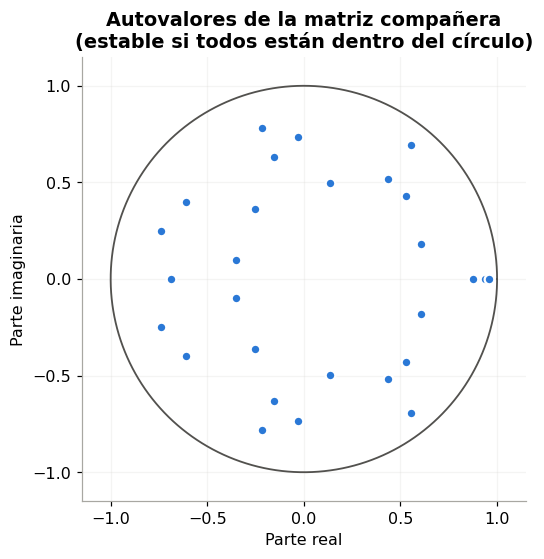

#### Resultado
Raíz más cercana al círculo unitario: |z| = 1.0428 (autovalor de la compañera |λ| = 0.9590).

#### Decisión estadística
El VAR es **estable**: todas las raíces cumplen |z| > 1.

#### Interpretación epidemiológica
Los efectos de una perturbación sobre el sistema se disipan con el tiempo, condición necesaria para interpretar respuestas transitorias.

#### Precaución
Un módulo de autovalor cercano a 1 indica alta persistencia: las respuestas tardarán en desaparecer y las bandas de confianza a horizontes largos serán amplias.

In [27]:
raices = var_result.roots
tabla_raices = (pd.DataFrame({'Raíz z': raices, 'Módulo |z|': np.abs(raices),
                              '|λ| = 1/|z| (compañera)': 1 / np.abs(raices)})
                .sort_values('Módulo |z|').reset_index(drop=True))
tabla_raices['Condición de estabilidad'] = np.where(tabla_raices['Módulo |z|'] > 1,
                                                    '|z| > 1 ✓', '|z| ≤ 1 ✗')
tabla_raices.index = tabla_raices.index + 1
display(tabla_raices.head(10).style.format({'Raíz z': '{:.3f}', 'Módulo |z|': '{:.4f}',
                                            '|λ| = 1/|z| (compañera)': '{:.4f}'}))
print(f'Se muestran las 10 raíces más cercanas al círculo unitario de {len(raices)} en total.')

fig, ax = plt.subplots(figsize=(5.2, 5.2))
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), color=GRIS, linewidth=1.2)
inv = 1 / raices
ax.scatter(inv.real, inv.imag, s=40, color=COLORES['asma'], edgecolor='white', linewidth=1.5, zorder=3)
ax.set(aspect='equal', xlim=(-1.15, 1.15), ylim=(-1.15, 1.15),
       title='Autovalores de la matriz compañera\n(estable si todos están dentro del círculo)',
       xlabel='Parte real', ylabel='Parte imaginaria')
plt.tight_layout()
plt.show()

MODELO_ESTABLE = bool(estable)
RES['estable'] = MODELO_ESTABLE
RES['modulo_max'] = float(tabla_raices['|λ| = 1/|z| (compañera)'].max())
informe(
    resultado=(f"Raíz más cercana al círculo unitario: |z| = {tabla_raices['Módulo |z|'].min():.4f} "
               f"(autovalor de la compañera |λ| = {RES['modulo_max']:.4f})."),
    decision=("El VAR es **estable**: todas las raíces cumplen |z| > 1." if MODELO_ESTABLE else
              "El VAR **no es estable**: no deben interpretarse IRF ni FEVD estándar."),
    epidemiologia=("Los efectos de una perturbación sobre el sistema se disipan con el tiempo, condición "
                   "necesaria para interpretar respuestas transitorias." if MODELO_ESTABLE else
                   "Las perturbaciones no se disipan: revise la especificación (diferenciación, tendencia)."),
    precaucion=("Un módulo de autovalor cercano a 1 indica alta persistencia: las respuestas tardarán en "
                "desaparecer y las bandas de confianza a horizontes largos serán amplias."
                if RES['modulo_max'] > 0.9 else
                "La estabilidad no garantiza que el modelo sea correcto; solo que es internamente coherente."))

## 21. Diagnóstico residual

| Prueba | $H_0$ | Si se rechaza |
|---|---|---|
| **Portmanteau** multivariada | Ausencia de autocorrelación residual hasta el rezago evaluado | Queda dinámica sin modelar; la inferencia (Granger, IRF) pierde validez |
| **Normalidad** multivariada (asimetría y curtosis, tipo Jarque–Bera) | Residuos gaussianos | Los intervalos de predicción gaussianos pueden ser inadecuados |
| **Ljung–Box** por ecuación | Sin autocorrelación en esa ecuación | Localiza dónde queda dependencia |
| **ARCH-LM** por ecuación | Varianza condicional constante | Heterocedasticidad condicional |

**Lectura correcta del valor *p* de Portmanteau:** si $p > 0.05$, **no existe evidencia suficiente** para rechazar $H_0$; esto **no demuestra** que no haya autocorrelación (la prueba tiene potencia limitada).

**Sobre la no normalidad:** rechazar la normalidad **no significa que el modelo "no sirva"**. Los estimadores MCO siguen siendo consistentes y la inferencia asintótica sobre los coeficientes es aproximadamente válida con muestras grandes. Lo que sí se ve afectado:

- los **intervalos de predicción** gaussianos pueden tener cobertura incorrecta (demasiado estrechos en las colas o simétricos cuando los datos no lo son);
- los intervalos de las IRF asintóticos pueden ser imprecisos (el *bootstrap* es una alternativa).

En este problema la no normalidad es **esperable**: el asma es un conteo con asimetría positiva y la precipitación tiene muchos días cercanos a cero y pocos días muy lluviosos.

In [28]:
NLAGS_PORT = 20
port = var_result.test_whiteness(nlags=NLAGS_PORT)
norm = var_result.test_normality()
print(port.summary())
print()
print(norm.summary())

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 20 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         239.3          242.6   0.067 208
-----------------------------------------

normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
         3043.          15.51   0.000  8
----------------------------------------


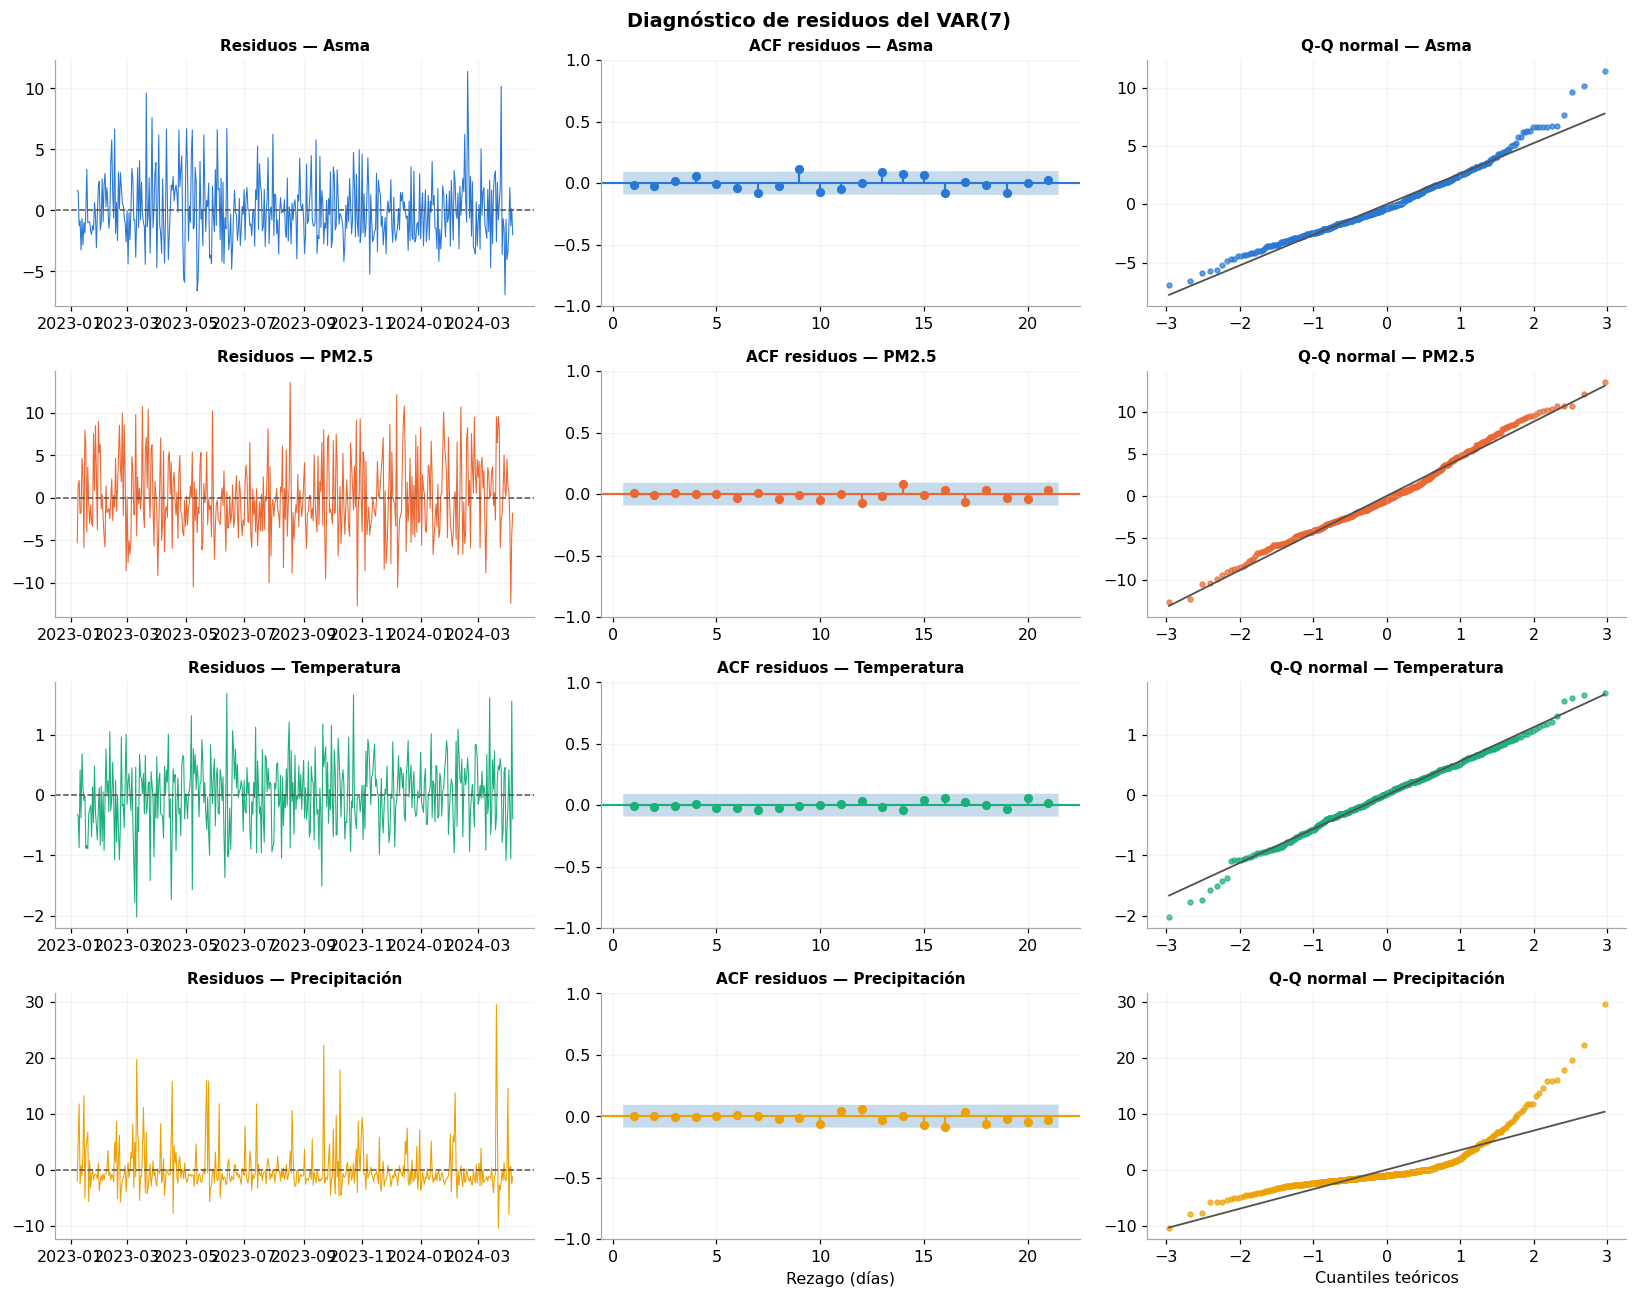

In [29]:
resid = var_result.resid
ajustados = var_result.fittedvalues

fig, axes = plt.subplots(4, 3, figsize=(15, 12))
for i, col in enumerate(VARIABLES):
    r = resid[col]
    axes[i, 0].plot(r.index, r, color=COLORES[col], linewidth=0.7)
    axes[i, 0].axhline(0, color=GRIS, linestyle='--', linewidth=1)
    axes[i, 0].set_title(f'Residuos — {ETIQUETAS[col]}', fontsize=10)
    plot_acf(r, lags=21, ax=axes[i, 1], zero=False, color=COLORES[col],
             vlines_kwargs={'colors': COLORES[col]})
    axes[i, 1].set_title(f'ACF residuos — {ETIQUETAS[col]}', fontsize=10)
    (osm, osr), (pend, inter, _) = stats.probplot(r, dist='norm')
    axes[i, 2].scatter(osm, osr, s=10, color=COLORES[col], alpha=0.7)
    axes[i, 2].plot(osm, pend * osm + inter, color=GRIS, linewidth=1.2)
    axes[i, 2].set_title(f'Q-Q normal — {ETIQUETAS[col]}', fontsize=10)
axes[-1, 1].set_xlabel('Rezago (días)')
axes[-1, 2].set_xlabel('Cuantiles teóricos')
plt.suptitle(f'Diagnóstico de residuos del VAR({P_SEL})', fontweight='bold')
plt.tight_layout()
plt.show()

### 21.1 Inspección de heterocedasticidad en la ecuación de asma

En un conteo, la varianza tiende a crecer con la media. Si eso ocurre, los residuos del VAR deberían ser más dispersos cuando el valor ajustado es mayor (forma de "embudo").

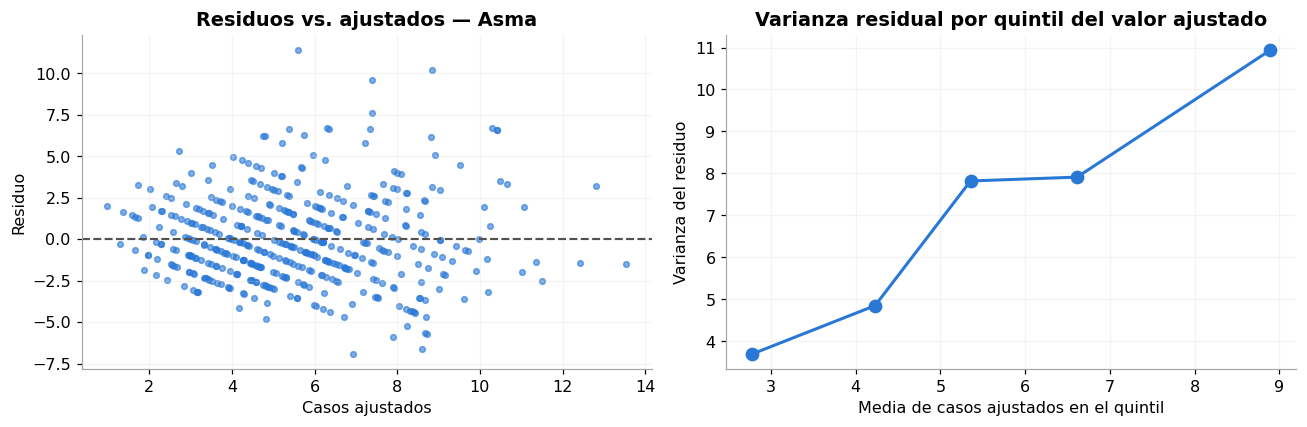

Correlación de Spearman entre ajustados y residuos²: 0.186 (p = < 0.001)


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(ajustados['asma'], resid['asma'], s=14, color=COLORES['asma'], alpha=0.6)
axes[0].axhline(0, color=GRIS, linestyle='--')
axes[0].set(title='Residuos vs. ajustados — Asma', xlabel='Casos ajustados', ylabel='Residuo')

grupos_aj = pd.qcut(ajustados['asma'], 5)
var_por_grupo = resid['asma'].groupby(grupos_aj, observed=True).var()
media_por_grupo = ajustados['asma'].groupby(grupos_aj, observed=True).mean()
axes[1].plot(media_por_grupo, var_por_grupo, marker='o', markersize=8,
             color=COLORES['asma'], linewidth=2)
axes[1].set(title='Varianza residual por quintil del valor ajustado',
            xlabel='Media de casos ajustados en el quintil', ylabel='Varianza del residuo')
plt.tight_layout()
plt.show()

rho_het, p_het = stats.spearmanr(ajustados['asma'], resid['asma'] ** 2)
print(f'Correlación de Spearman entre ajustados y residuos²: {rho_het:.3f} (p = {fmt_p(p_het)})')

In [31]:
def decision(p, alpha=ALPHA):
    return 'Rechaza H₀' if p < alpha else 'No rechaza H₀'


filas = [{
    'Prueba': f'Portmanteau multivariada (rezago {NLAGS_PORT})',
    'H₀': 'Sin autocorrelación residual', 'Estadístico': port.test_statistic, 'p': port.pvalue,
    'Decisión': decision(port.pvalue),
    'Implicación': ('Queda dinámica sin modelar; inferencia comprometida' if port.pvalue < ALPHA
                    else 'No hay evidencia de autocorrelación residual conjunta'),
}, {
    'Prueba': 'Normalidad multivariada', 'H₀': 'Residuos gaussianos',
    'Estadístico': norm.test_statistic, 'p': norm.pvalue, 'Decisión': decision(norm.pvalue),
    'Implicación': ('Intervalos gaussianos aproximados; esperable con conteos y lluvia asimétrica'
                    if norm.pvalue < ALPHA else 'Compatible con normalidad'),
}]
for col in VARIABLES:
    r = resid[col]
    lb = acorr_ljungbox(r, lags=[14])
    filas.append({'Prueba': f'Ljung–Box (14) — {ETIQUETAS[col]}', 'H₀': 'Sin autocorrelación',
                  'Estadístico': lb['lb_stat'].iloc[0], 'p': lb['lb_pvalue'].iloc[0],
                  'Decisión': decision(lb['lb_pvalue'].iloc[0]),
                  'Implicación': 'Dependencia remanente en esta ecuación' if lb['lb_pvalue'].iloc[0] < ALPHA
                  else 'Sin dependencia remanente detectada'})
for col in VARIABLES:
    jb = stats.jarque_bera(resid[col])
    filas.append({'Prueba': f'Jarque–Bera — {ETIQUETAS[col]}', 'H₀': 'Normalidad univariada',
                  'Estadístico': jb.statistic, 'p': jb.pvalue, 'Decisión': decision(jb.pvalue),
                  'Implicación': (f'Asimetría {stats.skew(resid[col]):.2f}, '
                                  f'curtosis exceso {stats.kurtosis(resid[col]):.2f}')})
for col in VARIABLES:
    lm, lm_p, _, _ = het_arch(resid[col], nlags=7)
    filas.append({'Prueba': f'ARCH-LM (7) — {ETIQUETAS[col]}', 'H₀': 'Varianza condicional constante',
                  'Estadístico': lm, 'p': lm_p, 'Decisión': decision(lm_p),
                  'Implicación': 'Heterocedasticidad condicional' if lm_p < ALPHA
                  else 'Sin evidencia de efectos ARCH'})

tabla_diag = pd.DataFrame(filas).set_index('Prueba')
display(tabla_diag.style.format({'Estadístico': '{:.2f}', 'p': fmt_p}))

RES['portmanteau_p'] = port.pvalue
RES['normalidad_p'] = norm.pvalue
RES['lb_asma_p'] = tabla_diag.loc['Ljung–Box (14) — Asma', 'p']
RES['het_asma_p'] = p_het

informe(
    resultado=(f"Portmanteau (rezago {NLAGS_PORT}) con la muestra completa: p = {fmt_p(port.pvalue)} "
               f"(en la muestra de selección, sin los últimos {N_TEST} días, fue p = {fmt_p(RES['port_p_seleccion'])}). "
               f"Normalidad multivariada: p = {fmt_p(norm.pvalue)}. "
               f"Ljung–Box (14) en asma: p = {fmt_p(RES['lb_asma_p'])}. "
               f"Correlación ajustados–residuos² en asma: ρ = {rho_het:.2f} (p = {fmt_p(p_het)})."),
    decision=(("No hay evidencia suficiente para rechazar la ausencia de autocorrelación residual. "
               if port.pvalue >= ALPHA else
               "Se rechaza la ausencia de autocorrelación residual: el modelo deja dinámica sin capturar. ")
              + ("Se rechaza la normalidad de los residuos." if norm.pvalue < ALPHA
                 else "No se rechaza la normalidad.")),
    epidemiologia=("La no normalidad y una varianza que crece con el nivel son las firmas esperables de un "
                   "**conteo** modelado con un modelo lineal gaussiano, y de una precipitación muy asimétrica. "
                   "No invalidan el VAR como herramienta descriptiva de la dinámica, pero señalan que un "
                   "modelo de conteo describiría mejor la incertidumbre de los casos."),
    precaucion=("Los intervalos de predicción gaussianos del VAR serán simétricos y podrán incluir valores "
                "negativos de casos. El valor p de Portmanteau depende del rezago evaluado y de la muestra"
                + ("; que cambie de decisión entre la muestra de selección y la completa indica que la adecuación "
                   "residual es **marginal**, no un resultado firme."
                   if (RES['port_p_seleccion'] < ALPHA) != (port.pvalue < ALPHA) else
                   "; un p cercano a 0.05 indicaría adecuación solo marginal.")))

,H₀,Estadístico,p,Decisión,Implicación
Prueba,,,,,
Portmanteau multivariada (rezago 20),Sin autocorrelación residual,239.30,0.067,No rechaza H₀,No hay evidencia de autocorrelación residual conjunta
Normalidad multivariada,Residuos gaussianos,3042.91,< 0.001,Rechaza H₀,Intervalos gaussianos aproximados; esperable con conteos y lluvia asimétrica
Ljung–Box (14) — Asma,Sin autocorrelación,21.41,0.092,No rechaza H₀,Sin dependencia remanente detectada
Ljung–Box (14) — PM2.5,Sin autocorrelación,8.04,0.887,No rechaza H₀,Sin dependencia remanente detectada
Ljung–Box (14) — Temperatura,Sin autocorrelación,2.86,0.999,No rechaza H₀,Sin dependencia remanente detectada
Ljung–Box (14) — Precipitación,Sin autocorrelación,5.19,0.983,No rechaza H₀,Sin dependencia remanente detectada
Jarque–Bera — Asma,Normalidad univariada,62.47,< 0.001,Rechaza H₀,"Asimetría 0.70, curtosis exceso 1.16"
Jarque–Bera — PM2.5,Normalidad univariada,6.94,0.031,Rechaza H₀,"Asimetría 0.30, curtosis exceso -0.01"
Jarque–Bera — Temperatura,Normalidad univariada,6.17,0.046,Rechaza H₀,"Asimetría -0.17, curtosis exceso 0.46"


#### Resultado
Portmanteau (rezago 20) con la muestra completa: p = 0.067 (en la muestra de selección, sin los últimos 30 días, fue p = 0.015). Normalidad multivariada: p = < 0.001. Ljung–Box (14) en asma: p = 0.092. Correlación ajustados–residuos² en asma: ρ = 0.19 (p = < 0.001).

#### Decisión estadística
No hay evidencia suficiente para rechazar la ausencia de autocorrelación residual. Se rechaza la normalidad de los residuos.

#### Interpretación epidemiológica
La no normalidad y una varianza que crece con el nivel son las firmas esperables de un **conteo** modelado con un modelo lineal gaussiano, y de una precipitación muy asimétrica. No invalidan el VAR como herramienta descriptiva de la dinámica, pero señalan que un modelo de conteo describiría mejor la incertidumbre de los casos.

#### Precaución
Los intervalos de predicción gaussianos del VAR serán simétricos y podrán incluir valores negativos de casos. El valor p de Portmanteau depende del rezago evaluado y de la muestra; que cambie de decisión entre la muestra de selección y la completa indica que la adecuación residual es **marginal**, no un resultado firme.

## 22. Causalidad de Granger

Para cada dirección $X \rightarrow Y$, la prueba F evalúa

$$
H_0:\; \text{todos los coeficientes de } X_{t-1},\dots,X_{t-p} \text{ en la ecuación de } Y \text{ son cero}.
$$

**Lenguaje correcto:**

- Si se rechaza $H_0$: *"Existe evidencia de precedencia predictiva en el sentido de Granger de X hacia Y."*
- Si no se rechaza: *"No se encontró evidencia de que los rezagos de X mejoren la predicción de Y."*

**Lenguaje incorrecto:** "X causa Y", "X no causa Y".

Se evalúan las tres direcciones ambientales → asma, la prueba **conjunta** (las tres a la vez), y las direcciones **inversas** asma → ambiente como control de plausibilidad.

### 💡 Antes de ejecutar
> Si encontráramos que "asma → precipitación" es significativa, ¿lo interpretaría como que los casos de asma producen lluvia? ¿Qué explicación alternativa propondría?

In [32]:
def tabla_granger(resultado, direcciones, alpha=ALPHA):
    # Pruebas F de Granger con lenguaje de precedencia predictiva.
    filas = []
    for causante, causada in direcciones:
        t = resultado.test_causality(caused=causada, causing=causante, kind='f')
        nombre_x = ' + '.join(ETIQUETAS[c] for c in np.atleast_1d(causante))
        filas.append({
            'Dirección': f'{nombre_x} → {ETIQUETAS[causada]}',
            'Estadístico F': t.test_statistic, 'gl': f'({t.df[0]}, {t.df[1]})', 'p': t.pvalue,
            'Decisión': ('Evidencia de precedencia predictiva (Granger)' if t.pvalue < alpha else
                         f'Sin evidencia de que los rezagos de {nombre_x} mejoren la predicción de '
                         f'{ETIQUETAS[causada]}'),
        })
    return pd.DataFrame(filas).set_index('Dirección')


DIR_HACIA_ASMA = [(x, 'asma') for x in EXPOSICIONES]
DIR_CONJUNTA = [(EXPOSICIONES, 'asma')]
DIR_INVERSAS = [('asma', x) for x in EXPOSICIONES]

tabla_g = tabla_granger(var_result, DIR_HACIA_ASMA + DIR_CONJUNTA + DIR_INVERSAS)
with pd.option_context('display.max_colwidth', None):
    display(tabla_g.style.format({'Estadístico F': '{:.3f}', 'p': fmt_p}))

,Estadístico F,gl,p,Decisión
Dirección,,,,
PM2.5 → Asma,0.794,"(7, 1704)",0.592,Sin evidencia de que los rezagos de PM2.5 mejoren la predicción de Asma
Temperatura → Asma,0.791,"(7, 1704)",0.595,Sin evidencia de que los rezagos de Temperatura mejoren la predicción de Asma
Precipitación → Asma,1.701,"(7, 1704)",0.105,Sin evidencia de que los rezagos de Precipitación mejoren la predicción de Asma
PM2.5 + Temperatura + Precipitación → Asma,1.154,"(21, 1704)",0.284,Sin evidencia de que los rezagos de PM2.5 + Temperatura + Precipitación mejoren la predicción de Asma
Asma → PM2.5,2.609,"(7, 1704)",0.011,Evidencia de precedencia predictiva (Granger)
Asma → Temperatura,1.375,"(7, 1704)",0.212,Sin evidencia de que los rezagos de Asma mejoren la predicción de Temperatura
Asma → Precipitación,0.294,"(7, 1704)",0.956,Sin evidencia de que los rezagos de Asma mejoren la predicción de Precipitación


In [33]:
hacia = tabla_g.iloc[:3]
inversas = tabla_g.iloc[4:]
sig_hacia = hacia.index[hacia['p'] < ALPHA].tolist()
sig_inv = inversas.index[inversas['p'] < ALPHA].tolist()
p_conj = tabla_g.iloc[3]['p']
RES['granger_hacia_asma'] = hacia['p'].to_dict()
RES['granger_conjunta_p'] = p_conj
RES['granger_sig'] = sig_hacia
RES['granger_inv_sig'] = sig_inv

informe(
    resultado=("Valores p hacia asma: " + "; ".join(f"{d}: {fmt_p(p)}" for d, p in hacia['p'].items())
               + f". Prueba conjunta (tres variables ambientales): p = {fmt_p(p_conj)}. "
               "Direcciones inversas: " + "; ".join(f"{d}: {fmt_p(p)}" for d, p in inversas['p'].items()) + "."),
    decision=((f"Al 5 %, hay evidencia de precedencia predictiva en el sentido de Granger para: "
               f"**{', '.join(sig_hacia)}**." if sig_hacia else
               f"Al 5 %, **no se encontró evidencia** de que los rezagos de PM2.5, temperatura o precipitación "
               f"mejoren la predicción de los casos de asma en el VAR({P_SEL}).")
              + (" La prueba conjunta tampoco rechaza H₀." if p_conj >= ALPHA else
                 " La prueba conjunta sí rechaza H₀: las variables ambientales aportan información predictiva en bloque.")),
    epidemiologia=("Precedencia predictiva ≠ causalidad epidemiológica. "
                   + (f"Además, se detecta 'precedencia' en direcciones sin sentido mecanístico ({', '.join(sig_inv)}), "
                      "lo que ilustra que estas pruebas pueden capturar factores comunes (calendario, estacionalidad)."
                      if sig_inv else
                      "En las direcciones inversas (asma → ambiente), que no tienen sentido mecanístico, tampoco se "
                      "detecta precedencia, lo cual es tranquilizador como control de plausibilidad.")),
    precaucion=("No encontrar evidencia no prueba ausencia de efecto: con muchos rezagos la prueba pierde potencia, "
                "un efecto pequeño puede no detectarse con ~15 meses de datos y la relación podría ser no lineal o "
                "concentrarse en días de contaminación alta. Se realizaron varias pruebas; considere la multiplicidad."))

#### Resultado
Valores p hacia asma: PM2.5 → Asma: 0.592; Temperatura → Asma: 0.595; Precipitación → Asma: 0.105. Prueba conjunta (tres variables ambientales): p = 0.284. Direcciones inversas: Asma → PM2.5: 0.011; Asma → Temperatura: 0.212; Asma → Precipitación: 0.956.

#### Decisión estadística
Al 5 %, **no se encontró evidencia** de que los rezagos de PM2.5, temperatura o precipitación mejoren la predicción de los casos de asma en el VAR(7). La prueba conjunta tampoco rechaza H₀.

#### Interpretación epidemiológica
Precedencia predictiva ≠ causalidad epidemiológica. Además, se detecta 'precedencia' en direcciones sin sentido mecanístico (Asma → PM2.5), lo que ilustra que estas pruebas pueden capturar factores comunes (calendario, estacionalidad).

#### Precaución
No encontrar evidencia no prueba ausencia de efecto: con muchos rezagos la prueba pierde potencia, un efecto pequeño puede no detectarse con ~15 meses de datos y la relación podría ser no lineal o concentrarse en días de contaminación alta. Se realizaron varias pruebas; considere la multiplicidad.

### 22.1 Sensibilidad de Granger al orden del VAR y a la tendencia

Una conclusión robusta no debería depender críticamente de un único $p$ ni de incluir o no una tendencia determinística (recuerde la evidencia mixta de estacionariedad).

In [34]:
filas = []
for p in CANDIDATOS:
    for trend in ('c', 'ct'):
        res = VAR(df).fit(p, trend=trend)
        fila = {'Modelo': f'VAR({p})', 'Términos deterministas': 'constante' if trend == 'c'
                else 'constante + tendencia'}
        for x in EXPOSICIONES:
            fila[f'{ETIQUETAS[x]} → Asma'] = res.test_causality('asma', x, kind='f').pvalue
        filas.append(fila)
tabla_g_sens = pd.DataFrame(filas).set_index(['Modelo', 'Términos deterministas'])
display(tabla_g_sens.style.format(fmt_p).apply(
    lambda s: ['font-weight: bold' if v < ALPHA else '' for v in s]))

n_sig = int((tabla_g_sens < ALPHA).sum().sum())
sig_celdas = [f'{col} en {m} ({t})' for (m, t), fila in tabla_g_sens.iterrows()
              for col, p in fila.items() if p < ALPHA]
mostrar_md(
    f"De {tabla_g_sens.size} pruebas en esta tabla, **{n_sig}** con p < {ALPHA} (en negrita)"
    + (f": {'; '.join(sig_celdas)}." if sig_celdas else ".")
    + f" Por azar se esperarían alrededor de {0.05 * tabla_g_sens.size:.1f}. "
    "Un rechazo aislado que aparece en una sola especificación indica evidencia **frágil**; "
    "una conclusión robusta debería mantenerse en la mayoría de especificaciones razonables.")

De 18 pruebas en esta tabla, **1** con p < 0.05 (en negrita): Temperatura → Asma en VAR(1) (constante + tendencia). Por azar se esperarían alrededor de 0.9. Un rechazo aislado que aparece en una sola especificación indica evidencia **frágil**; una conclusión robusta debería mantenerse en la mayoría de especificaciones razonables.

### 22.2 Correlación contemporánea de las innovaciones

`statsmodels` llama a esta prueba *"instantaneous causality"* (`test_inst_causality`). Lo que realmente evalúa es si las innovaciones de una variable están **correlacionadas el mismo día** con las de las demás ($H_0$: las covarianzas correspondientes en $\Sigma_\varepsilon$ son cero).

- La correlación es **simétrica**: no indica dirección.
- Puede reflejar un factor común no observado.
- **No** es evidencia suficiente de causalidad estructural.

Esta información es, sin embargo, muy importante para la sección 24: **cuanto mayor sea la correlación contemporánea entre innovaciones, más dependerán las IRF ortogonalizadas del orden de Cholesky.**

In [35]:
corr_resid = var_result.resid_corr
corr_resid = pd.DataFrame(corr_resid, index=[ETIQUETAS[c] for c in VARIABLES],
                          columns=[ETIQUETAS[c] for c in VARIABLES])
display(corr_resid.round(3))

filas = []
for col in VARIABLES:
    t = var_result.test_inst_causality(causing=col)
    filas.append({'Variable': ETIQUETAS[col], 'Estadístico': t.test_statistic, 'p': t.pvalue,
                  'Decisión': ('Innovaciones correlacionadas contemporáneamente con el resto'
                               if t.pvalue < ALPHA else 'Sin evidencia de correlación contemporánea')})
display(pd.DataFrame(filas).set_index('Variable').style.format({'Estadístico': '{:.2f}', 'p': fmt_p}))
RES['corr_resid_pm25_asma'] = corr_resid.loc['PM2.5', 'Asma']

,Asma,PM2.5,Temperatura,Precipitación
Asma,1.000,0.058,-0.004,0.041
PM2.5,0.058,1.000,-0.093,0.112
Temperatura,-0.004,-0.093,1.000,-0.264
Precipitación,0.041,0.112,-0.264,1.000


,Estadístico,p,Decisión
Variable,,,
Asma,2.12,0.548,Sin evidencia de correlación contemporánea
PM2.5,8.84,0.031,Innovaciones correlacionadas contemporáneamente con el resto
Temperatura,31.33,< 0.001,Innovaciones correlacionadas contemporáneamente con el resto
Precipitación,33.18,< 0.001,Innovaciones correlacionadas contemporáneamente con el resto


## 23. Funciones impulso-respuesta (IRF)

### Pregunta
> ¿Cómo evoluciona el número esperado de casos de asma después de una innovación (sorpresa) en PM2.5?

### Conceptos

| Concepto | Significado |
|---|---|
| **Shock (innovación)** | Una perturbación inesperada en una variable, de tamaño 1 desviación estándar del shock ortogonalizado, en el día 0 |
| **Horizonte** | Días transcurridos desde el shock (0 = mismo día) |
| **Respuesta** | Cambio en el valor esperado de la variable de respuesta respecto a un escenario sin shock |
| **Signo** | Positivo: más casos esperados; negativo: menos |
| **Magnitud** | En unidades de la variable de respuesta (casos/día) |
| **Persistencia** | Cuántos días tarda la respuesta en volver a cero |
| **Retorno a cero** | En un VAR estable, todas las respuestas tienden a cero |
| **Intervalo de confianza** | Banda asintótica al 95 %; si incluye el cero, la respuesta no es distinguible de cero |

**IRF ortogonalizadas (Cholesky).** Como las innovaciones están correlacionadas, un "shock puro" en PM2.5 no está definido sin supuestos adicionales. La descomposición de Cholesky $\Sigma_\varepsilon = PP'$ construye shocks no correlacionados imponiendo un **orden recursivo**. El orden por defecto aquí es el de las columnas: `['asma', 'pm25', 'temperatura', 'precipitacion']`. En la sección 24 discutimos si este orden es razonable.

### ⚠️ Evite esta conclusión
> *"PM2.5 causa asma porque existe una IRF positiva."*

Es excesiva porque: (1) la IRF depende del orden de identificación; (2) describe correlaciones dinámicas en un modelo observacional de forma reducida; (3) no controla confusores omitidos (estacionalidad, virus, festivos); (4) si la banda incluye el cero, ni siquiera hay evidencia estadística de respuesta distinta de cero.

,"Tamaño del shock (1 DE, impacto propio)",Unidad
Variable que recibe el shock,,
Asma,2.734,casos/día
PM2.5,4.580,µg/m³
Temperatura,0.578,°C
Precipitación,4.022,mm


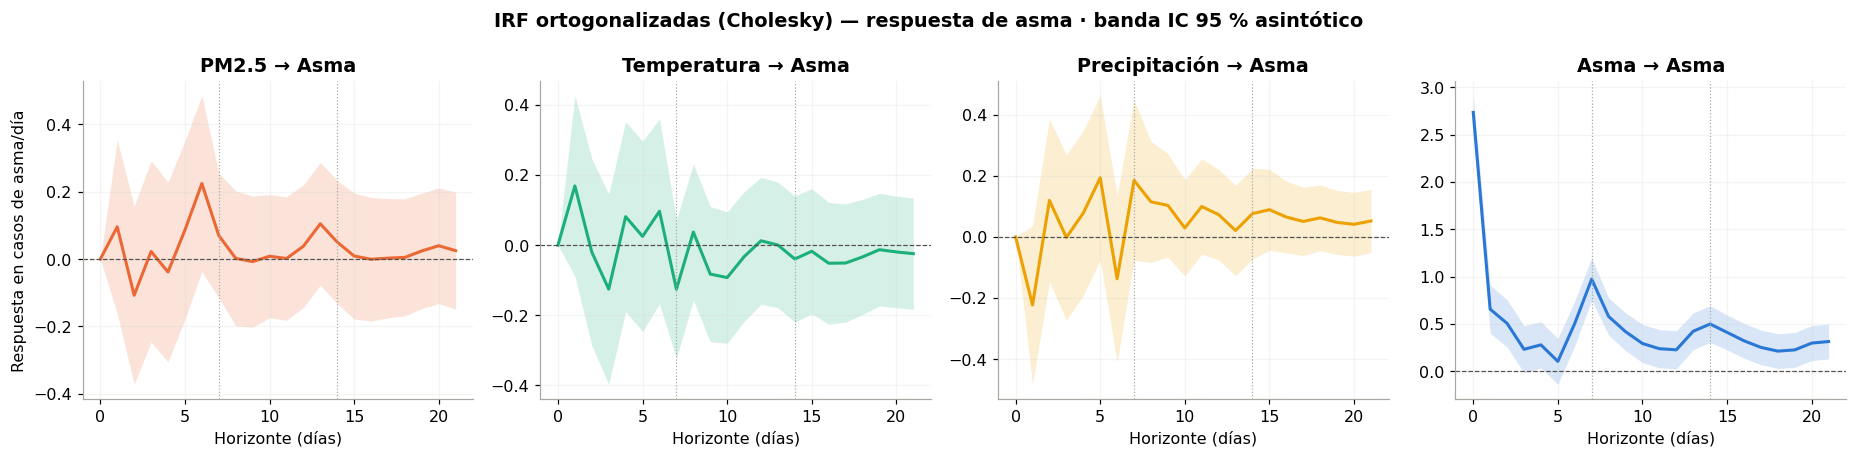

In [36]:
if not MODELO_ESTABLE:
    raise RuntimeError('El VAR no es estable: no se calculan IRF ni FEVD. Revise la especificación.')

H_IRF = max(HORIZONTES_IRF)
irf = var_result.irf(periods=H_IRF)
nombres = list(var_result.names)
i_asma = nombres.index('asma')
orth = irf.orth_irfs
orth_se = irf.stderr(orth=True)

# Tamaño de cada shock ortogonal en unidades de la propia variable (diagonal de Cholesky)
P_chol = np.linalg.cholesky(np.asarray(var_result.sigma_u))
display(pd.DataFrame({'Variable que recibe el shock': [ETIQUETAS[n] for n in nombres],
                      'Tamaño del shock (1 DE, impacto propio)': np.diag(P_chol).round(3),
                      'Unidad': [UNIDADES[n] for n in nombres]}).set_index('Variable que recibe el shock'))

IMPULSOS = ['pm25', 'temperatura', 'precipitacion', 'asma']
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
h = np.arange(H_IRF + 1)
for ax, imp in zip(axes, IMPULSOS):
    j = nombres.index(imp)
    y, se = orth[:, i_asma, j], orth_se[:, i_asma, j]
    ax.fill_between(h, y - 1.96 * se, y + 1.96 * se, color=COLORES[imp], alpha=0.18, linewidth=0)
    ax.plot(h, y, color=COLORES[imp], linewidth=2)
    ax.axhline(0, color=GRIS, linewidth=0.8, linestyle='--')
    for k in (7, 14):
        ax.axvline(k, color=GRIS_CLARO, linestyle=':', linewidth=0.8)
    ax.set(title=f'{ETIQUETAS[imp]} → Asma', xlabel='Horizonte (días)')
axes[0].set_ylabel('Respuesta en casos de asma/día')
fig.suptitle('IRF ortogonalizadas (Cholesky) — respuesta de asma · banda IC 95 % asintótico',
             fontweight='bold')
plt.tight_layout()
plt.show()

In [37]:
def tabla_irf(irf_obj, nombres, impulso, respuesta='asma', horizontes=HORIZONTES_IRF):
    # Respuesta ortogonalizada, IC 95 % y respuesta acumulada en horizontes seleccionados.
    i, j = nombres.index(respuesta), nombres.index(impulso)
    y = irf_obj.orth_irfs[:, i, j]
    se = irf_obj.stderr(orth=True)[:, i, j]
    cum = irf_obj.orth_cum_effects[:, i, j]
    filas = []
    for hh in horizontes:
        li, ls = y[hh] - 1.96 * se[hh], y[hh] + 1.96 * se[hh]
        filas.append({'Impulso → Respuesta': f'{ETIQUETAS[impulso]} → {ETIQUETAS[respuesta]}',
                      'Horizonte (días)': hh, 'Respuesta': y[hh], 'IC 95 % inf': li,
                      'IC 95 % sup': ls, '¿IC incluye 0?': 'Sí' if li <= 0 <= ls else 'No',
                      'Respuesta acumulada 0..h': cum[hh]})
    return pd.DataFrame(filas)


tabla_irfs = pd.concat([tabla_irf(irf, nombres, imp) for imp in IMPULSOS], ignore_index=True)
display(tabla_irfs.set_index(['Impulso → Respuesta', 'Horizonte (días)'])
        .style.format({c: '{:.3f}' for c in ['Respuesta', 'IC 95 % inf', 'IC 95 % sup',
                                             'Respuesta acumulada 0..h']}))

In [38]:
def resumen_irf(irf_obj, nombres, impulso, respuesta='asma', h_max=H_IRF):
    i, j = nombres.index(respuesta), nombres.index(impulso)
    y = irf_obj.orth_irfs[1:h_max + 1, i, j]
    se = irf_obj.stderr(orth=True)[1:h_max + 1, i, j]
    fuera = np.where((y - 1.96 * se > 0) | (y + 1.96 * se < 0))[0] + 1
    h_pico = int(np.argmax(np.abs(y))) + 1
    return {'h_pico': h_pico, 'valor_pico': y[h_pico - 1], 'horizontes_signif': fuera.tolist()}


RES['irf'] = {imp: resumen_irf(irf, nombres, imp) for imp in IMPULSOS}
r_pm = RES['irf']['pm25']
informe(
    resultado=("PM2.5 → Asma: respuesta de mayor magnitud en el día "
               f"{r_pm['h_pico']} ({r_pm['valor_pico']:+.3f} casos/día). "
               + ("La banda al 95 % excluye el cero en los horizontes "
                  f"{r_pm['horizontes_signif']}." if r_pm['horizontes_signif'] else
                  "La banda al 95 % **incluye el cero en todos los horizontes 1–21**.")
               + " Otros impulsos con horizontes en que la banda excluye el cero: "
               + "; ".join(f"{ETIQUETAS[k]}: {v['horizontes_signif'] or 'ninguno'}"
                           for k, v in RES['irf'].items() if k != 'pm25') + "."),
    decision=("Hay horizontes en que la respuesta de asma a PM2.5 es estadísticamente distinta de cero "
              "bajo esta identificación." if r_pm['horizontes_signif'] else
              "No hay evidencia de que la respuesta esperada de asma a una innovación en PM2.5 sea distinta "
              "de cero bajo esta identificación."),
    epidemiologia=("La IRF Asma → Asma describe la persistencia propia de la serie (cómo se disipa un día "
                   "con casos inesperadamente altos). Las respuestas a variables ambientales describen "
                   "asociaciones dinámicas promedio, no efectos de intervención."),
    precaucion=("Estas IRF dependen del orden de Cholesky (sección 24) y su banda es asintótica y supone "
                "residuos aproximadamente normales, lo cual no se cumple (sección 21). Una banda que excluye el "
                "cero en un horizonte aislado, entre 21 evaluados, puede ser un falso positivo."))

#### Resultado
PM2.5 → Asma: respuesta de mayor magnitud en el día 6 (+0.225 casos/día). La banda al 95 % **incluye el cero en todos los horizontes 1–21**. Otros impulsos con horizontes en que la banda excluye el cero: Temperatura: ninguno; Precipitación: ninguno; Asma: [1, 2, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21].

#### Decisión estadística
No hay evidencia de que la respuesta esperada de asma a una innovación en PM2.5 sea distinta de cero bajo esta identificación.

#### Interpretación epidemiológica
La IRF Asma → Asma describe la persistencia propia de la serie (cómo se disipa un día con casos inesperadamente altos). Las respuestas a variables ambientales describen asociaciones dinámicas promedio, no efectos de intervención.

#### Precaución
Estas IRF dependen del orden de Cholesky (sección 24) y su banda es asintótica y supone residuos aproximadamente normales, lo cual no se cumple (sección 21). Una banda que excluye el cero en un horizonte aislado, entre 21 evaluados, puede ser un falso positivo.

## 24. Sensibilidad al orden de Cholesky: ¿por qué importa el orden de las variables?

Con Cholesky, la variable **primera** en el orden puede afectar contemporáneamente (el mismo día) a todas las demás, pero no recibe efectos contemporáneos de ninguna; la **última** recibe efectos contemporáneos de todas y no afecta a ninguna el mismo día.

| Orden | Supuesto contemporáneo implícito |
|---|---|
| **A (original):** asma, PM2.5, temperatura, precipitación | Los casos de asma de hoy pueden afectar el PM2.5, la temperatura y la lluvia **de hoy**, pero no al revés. Toda la correlación contemporánea asma–ambiente se atribuye al shock de asma |
| **B (ambiente primero):** precipitación, temperatura, PM2.5, asma | La meteorología afecta el mismo día al PM2.5 y al asma; el PM2.5 afecta al asma el mismo día; el asma no afecta a nada el mismo día |

El orden B es **epidemiológicamente más defendible** (el asma no modifica el clima), aunque también es un supuesto (por ejemplo, que la lluvia de hoy no responde al PM2.5 de hoy).

**Alternativa menos dependiente del orden: IRF generalizadas** (Pesaran y Shin, 1998). Para un shock en la variable $j$:

$$
\text{GIRF}_j(h) = \frac{\Psi_h\, \Sigma_\varepsilon\, e_j}{\sqrt{\sigma_{jj}}}
$$

donde $\Psi_h$ son los coeficientes de la representación de medias móviles. La GIRF **no depende del orden**: integra la correlación histórica de las innovaciones en lugar de imponer una estructura recursiva. Coincide con la IRF de Cholesky cuando la variable del shock se ubica **primera**. Sus shocks **no son ortogonales**, por lo que no se usan para FEVD estándar y tampoco tienen interpretación estructural.

> Ninguna de estas IRF es un **efecto causal estructural** sin una identificación justificada con conocimiento externo.

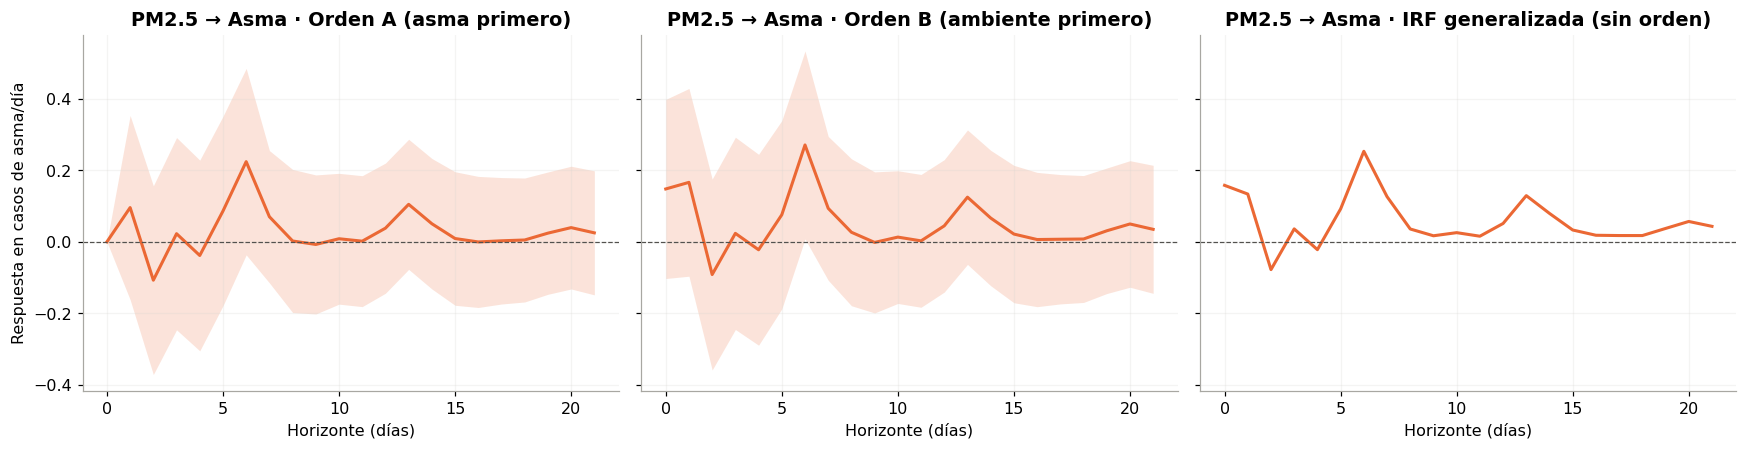

In [39]:
ORDEN_A = ['asma', 'pm25', 'temperatura', 'precipitacion']
ORDEN_B = ['precipitacion', 'temperatura', 'pm25', 'asma']


def irf_orden(data, orden, p, periodos=H_IRF):
    # Re-estima el VAR con otro orden de columnas (mismos coeficientes) y devuelve su IRF.
    res = VAR(data[orden]).fit(p)
    return res, res.irf(periods=periodos)


def girf(resultado, impulso, periodos=H_IRF):
    # IRF generalizada (Pesaran–Shin): Psi_h Σ e_j / sqrt(σ_jj). Devuelve (periodos+1, k).
    psi = resultado.ma_rep(maxn=periodos)
    sigma = np.asarray(resultado.sigma_u)
    j = list(resultado.names).index(impulso)
    return psi @ sigma[:, j] / np.sqrt(sigma[j, j])


res_A, irf_A = irf_orden(df, ORDEN_A, P_SEL)
res_B, irf_B = irf_orden(df, ORDEN_B, P_SEL)
g_pm = girf(var_result, 'pm25')[:, nombres.index('asma')]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (titulo, res_o, irf_o) in zip(axes[:2], [('Orden A (asma primero)', res_A, irf_A),
                                                ('Orden B (ambiente primero)', res_B, irf_B)]):
    n_o = list(res_o.names)
    i, j = n_o.index('asma'), n_o.index('pm25')
    y, se = irf_o.orth_irfs[:, i, j], irf_o.stderr(orth=True)[:, i, j]
    ax.fill_between(h, y - 1.96 * se, y + 1.96 * se, color=COLORES['pm25'], alpha=0.18, linewidth=0)
    ax.plot(h, y, color=COLORES['pm25'], linewidth=2)
    ax.axhline(0, color=GRIS, linestyle='--', linewidth=0.8)
    ax.set(title=f'PM2.5 → Asma · {titulo}', xlabel='Horizonte (días)')
axes[2].plot(h, g_pm, color=COLORES['pm25'], linewidth=2)
axes[2].axhline(0, color=GRIS, linestyle='--', linewidth=0.8)
axes[2].set(title='PM2.5 → Asma · IRF generalizada (sin orden)', xlabel='Horizonte (días)')
axes[0].set_ylabel('Respuesta en casos de asma/día')
plt.tight_layout()
plt.show()

In [40]:
tA = tabla_irf(irf_A, list(res_A.names), 'pm25').set_index('Horizonte (días)')
tB = tabla_irf(irf_B, list(res_B.names), 'pm25').set_index('Horizonte (días)')
tabla_orden = pd.DataFrame({
    'Orden A: respuesta': tA['Respuesta'], 'Orden A: ¿IC incluye 0?': tA['¿IC incluye 0?'],
    'Orden B: respuesta': tB['Respuesta'], 'Orden B: ¿IC incluye 0?': tB['¿IC incluye 0?'],
    'GIRF: respuesta': [g_pm[hh] for hh in HORIZONTES_IRF]}, index=tA.index)
display(tabla_orden.style.format({c: '{:.3f}' for c in tabla_orden if 'respuesta' in c}))

# Impacto en h = 0 (es donde el orden pesa más)
i_A, j_A = list(res_A.names).index('asma'), list(res_A.names).index('pm25')
i_B, j_B = list(res_B.names).index('asma'), list(res_B.names).index('pm25')
imp0_A, imp0_B = irf_A.orth_irfs[0, i_A, j_A], irf_B.orth_irfs[0, i_B, j_B]

rA = resumen_irf(irf_A, list(res_A.names), 'pm25')
rB = resumen_irf(irf_B, list(res_B.names), 'pm25')
cambia_signif = bool(rA['horizontes_signif']) != bool(rB['horizontes_signif'])
cambia_signo = np.sign(rA['valor_pico']) != np.sign(rB['valor_pico'])
RES['cholesky_cambia'] = cambia_signif or cambia_signo
RES['cholesky_detalle'] = (rA, rB)
# ¿La significancia (si existe) se limita a uno o dos horizontes aislados de 21?
n_sig_max = max(len(rA['horizontes_signif']), len(rB['horizontes_signif']))
aislado = 0 < n_sig_max <= 2
RES['cholesky_aislado'] = aislado

if not RES['cholesky_cambia']:
    decision_txt = "La conclusión cualitativa sobre PM2.5 → Asma **no cambia** entre los dos órdenes."
elif aislado:
    decision_txt = ("**La conclusión cambia con el orden, pero de forma marginal**: en uno de los órdenes la banda "
                    "excluye el cero solo en uno o dos horizontes aislados de 21, lo que es compatible con un falso "
                    "positivo por comparaciones múltiples. El patrón general (respuestas pequeñas y cercanas a cero) "
                    "es similar en ambos órdenes y en la GIRF.")
else:
    decision_txt = "**La conclusión sobre PM2.5 → Asma cambia con el orden** (signo o significancia en varios horizontes)."

informe(
    resultado=(f"Impacto contemporáneo (h = 0) de PM2.5 sobre asma: orden A = {imp0_A:.3f}, orden B = {imp0_B:.3f} "
               "(en el orden A es cero por construcción, porque asma va antes que PM2.5). "
               f"Correlación contemporánea de innovaciones PM2.5–asma: {RES['corr_resid_pm25_asma']:.3f}. "
               f"Horizontes con banda que excluye el cero: orden A {rA['horizontes_signif'] or 'ninguno'}, "
               f"orden B {rB['horizontes_signif'] or 'ninguno'}."),
    decision=decision_txt,
    epidemiologia=(f"La correlación contemporánea PM2.5–asma es {'baja' if abs(RES['corr_resid_pm25_asma']) < 0.2 else 'apreciable'}: "
                   "el orden de Cholesky pesa sobre todo en h = 0 (el orden B permite que el PM2.5 afecte al asma el "
                   "mismo día) y ese impacto inicial se propaga a los horizontes siguientes. Cuanto mayor sea esa "
                   "correlación, más puede cambiar la historia según el orden."),
    precaucion=("Incluso un resultado robusto al orden no sería un efecto causal: ambos órdenes y la GIRF son formas "
                "de describir la misma forma reducida del VAR, con los mismos confusores omitidos. Las bandas "
                "asintóticas no corrigen por los 21 horizontes evaluados."))

,Orden A: respuesta,Orden A: ¿IC incluye 0?,Orden B: respuesta,Orden B: ¿IC incluye 0?,GIRF: respuesta
Horizonte (días),,,,,
1,0.096,Sí,0.167,Sí,0.134
3,0.023,Sí,0.024,Sí,0.036
7,0.070,Sí,0.094,Sí,0.127
14,0.051,Sí,0.067,Sí,0.080
21,0.025,Sí,0.035,Sí,0.043


#### Resultado
Impacto contemporáneo (h = 0) de PM2.5 sobre asma: orden A = 0.000, orden B = 0.148 (en el orden A es cero por construcción, porque asma va antes que PM2.5). Correlación contemporánea de innovaciones PM2.5–asma: 0.058. Horizontes con banda que excluye el cero: orden A ninguno, orden B [6].

#### Decisión estadística
**La conclusión cambia con el orden, pero de forma marginal**: en uno de los órdenes la banda excluye el cero solo en uno o dos horizontes aislados de 21, lo que es compatible con un falso positivo por comparaciones múltiples. El patrón general (respuestas pequeñas y cercanas a cero) es similar en ambos órdenes y en la GIRF.

#### Interpretación epidemiológica
La correlación contemporánea PM2.5–asma es baja: el orden de Cholesky pesa sobre todo en h = 0 (el orden B permite que el PM2.5 afecte al asma el mismo día) y ese impacto inicial se propaga a los horizontes siguientes. Cuanto mayor sea esa correlación, más puede cambiar la historia según el orden.

#### Precaución
Incluso un resultado robusto al orden no sería un efecto causal: ambos órdenes y la GIRF son formas de describir la misma forma reducida del VAR, con los mismos confusores omitidos. Las bandas asintóticas no corrigen por los 21 horizontes evaluados.

## 25. Descomposición de la varianza del error de pronóstico (FEVD)

> La FEVD indica qué proporción de la incertidumbre del pronóstico de asma a $h$ días está asociada a innovaciones (ortogonalizadas) en cada variable del sistema.

Cada fila de la tabla suma 100 %. **No** se interpreta como "porcentaje de los casos causado por" cada variable. Como se basa en shocks de Cholesky, la FEVD **depende de la identificación** (orden de las variables), por lo que se reporta para ambos órdenes.

### 🧠 Interprete
> ¿Qué significaría que PM2.5 explicara un 10 % de la varianza del error de pronóstico de asma a siete días?

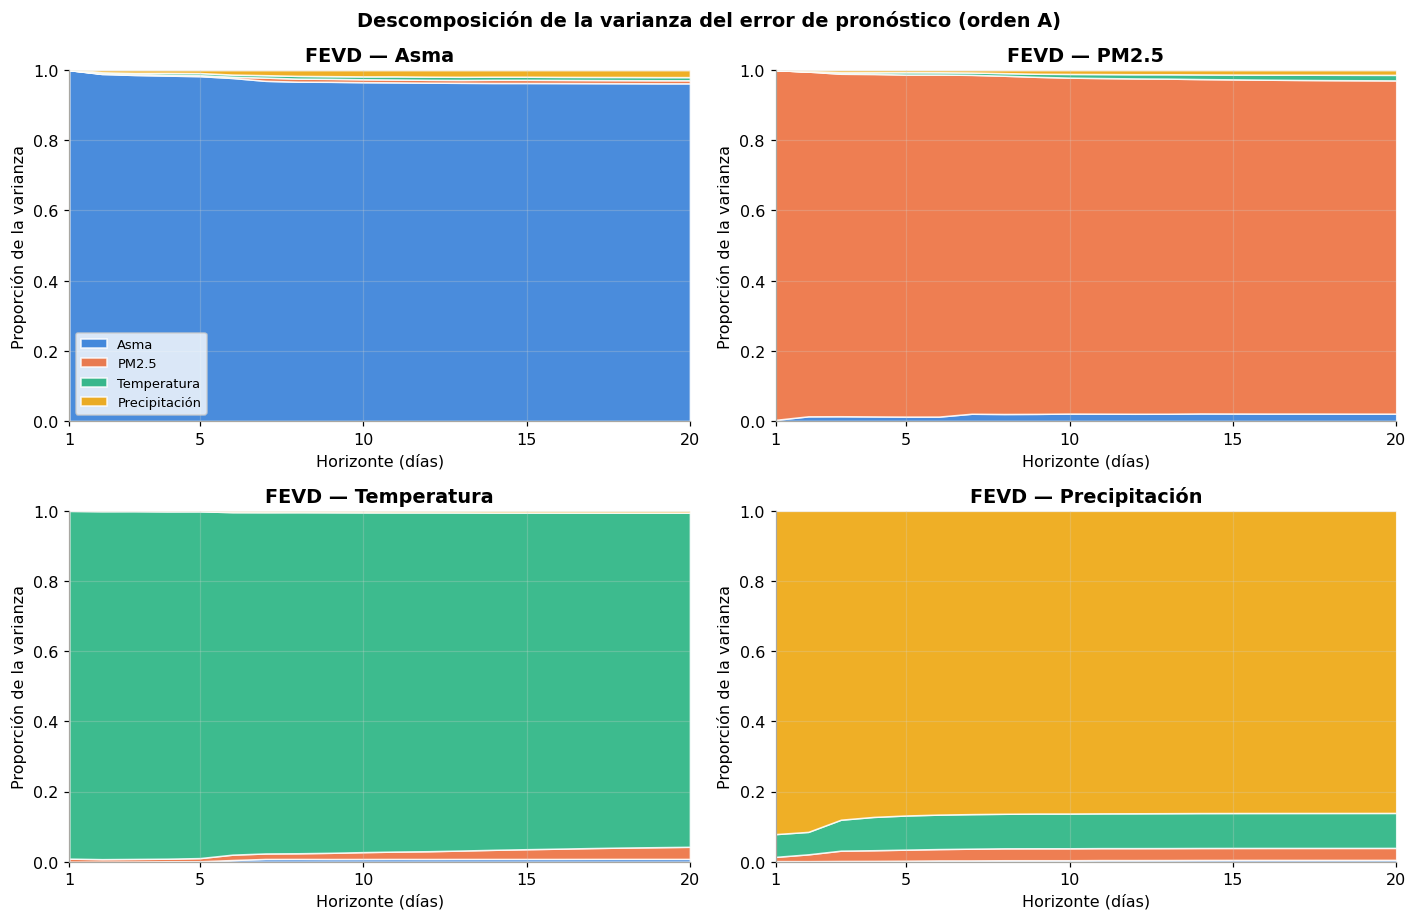

FEVD de asma (%) — Orden A (asma, PM2.5, temperatura, precipitación)


,Asma,PM2.5,Temperatura,Precipitación,Suma
Horizonte (días),,,,,
1,100.00,0.00,0.00,0.00,100.0
3,98.63,0.25,0.35,0.77,100.0
7,96.96,0.91,0.69,1.43,100.0
14,96.34,0.91,0.88,1.87,100.0
20,96.24,0.88,0.90,1.98,100.0


FEVD de asma (%) — Orden B (precipitación, temperatura, PM2.5, asma)


,Asma,PM2.5,Temperatura,Precipitación,Suma
Horizonte (días),,,,,
1,99.53,0.29,0.00,0.17,100.0
3,98.23,0.70,0.14,0.94,100.0
7,96.43,1.57,0.49,1.50,100.0
14,95.47,1.54,0.59,2.41,100.0
20,95.27,1.49,0.57,2.66,100.0


In [41]:
H_FEVD = max(HORIZONTES_FEVD)
fevd = var_result.fevd(periods=H_FEVD)
colores_fevd = [COLORES[c] for c in nombres]

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax_i, resp in enumerate(nombres):
    ax = axes[ax_i // 2][ax_i % 2]
    datos_fevd = pd.DataFrame(fevd.decomp[ax_i], columns=[ETIQUETAS[c] for c in nombres],
                              index=np.arange(1, H_FEVD + 1))
    ax.stackplot(datos_fevd.index, datos_fevd.T.values, colors=colores_fevd, alpha=0.85,
                 labels=datos_fevd.columns, edgecolor='white', linewidth=1)
    ax.set(title=f'FEVD — {ETIQUETAS[resp]}', xlabel='Horizonte (días)',
           ylabel='Proporción de la varianza', ylim=(0, 1), xlim=(1, H_FEVD),
           xticks=[1] + list(range(5, H_FEVD + 1, 5)))
axes[0, 0].legend(loc='lower left', fontsize=8.5, frameon=True)
fig.suptitle('Descomposición de la varianza del error de pronóstico (orden A)', fontweight='bold')
plt.tight_layout()
plt.show()


def tabla_fevd(resultado, respuesta='asma', horizontes=HORIZONTES_FEVD):
    # FEVD (%) para una variable de respuesta en horizontes seleccionados; columnas en orden fijo.
    n = list(resultado.names)
    dec = resultado.fevd(periods=max(horizontes)).decomp[n.index(respuesta)]
    t = pd.DataFrame(dec * 100, columns=[ETIQUETAS[c] for c in n], index=np.arange(1, max(horizontes) + 1))
    t = t.loc[horizontes, [ETIQUETAS[c] for c in VARIABLES]]
    t.index.name = 'Horizonte (días)'
    t['Suma'] = t.sum(axis=1)
    return t


fevd_A = tabla_fevd(res_A)
fevd_B = tabla_fevd(res_B)
print('FEVD de asma (%) — Orden A (asma, PM2.5, temperatura, precipitación)')
display(fevd_A.round(2))
print('FEVD de asma (%) — Orden B (precipitación, temperatura, PM2.5, asma)')
display(fevd_B.round(2))

In [42]:
RES['fevd_A'] = fevd_A
RES['fevd_B'] = fevd_B
h7 = 7 if 7 in fevd_A.index else fevd_A.index[len(fevd_A) // 2]
amb_A = fevd_A.loc[h7, ['PM2.5', 'Temperatura', 'Precipitación']].sum()
amb_B = fevd_B.loc[h7, ['PM2.5', 'Temperatura', 'Precipitación']].sum()
informe(
    resultado=(f"A {h7} días, la proporción de la varianza del error de pronóstico de asma asociada a sus propias "
               f"innovaciones es {fevd_A.loc[h7, 'Asma']:.1f} % (orden A) y {fevd_B.loc[h7, 'Asma']:.1f} % (orden B). "
               f"PM2.5 representa {fevd_A.loc[h7, 'PM2.5']:.1f} % (A) y {fevd_B.loc[h7, 'PM2.5']:.1f} % (B); "
               f"las tres variables ambientales en conjunto, {amb_A:.1f} % (A) y {amb_B:.1f} % (B). "
               f"A {max(HORIZONTES_FEVD)} días, PM2.5 representa {fevd_A.iloc[-1]['PM2.5']:.1f} % (A)."),
    decision=("La incertidumbre del pronóstico de asma está dominada por sus propias innovaciones."
              if fevd_A.loc[h7, 'Asma'] > 80 else
              "Una parte relevante de la incertidumbre del pronóstico de asma se asocia a innovaciones de otras variables."),
    epidemiologia=("Para la vigilancia, esto indica cuánta información adicional (en términos de reducción "
                   "potencial de la incertidumbre de pronóstico) aportan las series ambientales dentro de este "
                   "modelo lineal. No indica qué fracción de los casos 'se debe' a la contaminación."),
    precaucion="La FEVD ortogonalizada depende del orden de Cholesky; compare siempre ambas tablas.")

#### Resultado
A 7 días, la proporción de la varianza del error de pronóstico de asma asociada a sus propias innovaciones es 97.0 % (orden A) y 96.4 % (orden B). PM2.5 representa 0.9 % (A) y 1.6 % (B); las tres variables ambientales en conjunto, 3.0 % (A) y 3.6 % (B). A 20 días, PM2.5 representa 0.9 % (A).

#### Decisión estadística
La incertidumbre del pronóstico de asma está dominada por sus propias innovaciones.

#### Interpretación epidemiológica
Para la vigilancia, esto indica cuánta información adicional (en términos de reducción potencial de la incertidumbre de pronóstico) aportan las series ambientales dentro de este modelo lineal. No indica qué fracción de los casos 'se debe' a la contaminación.

#### Precaución
La FEVD ortogonalizada depende del orden de Cholesky; compare siempre ambas tablas.

## 26. Validación temporal

Ahora sí se usa el periodo de **prueba reservado** (últimos 30 días), que no intervino en la elección de $p$.

Se evalúan dos esquemas complementarios:

1. **Pronóstico dinámico desde un único origen** (como en el notebook original): con datos hasta el día anterior al test se pronostican los 30 días de una vez. Responde: *¿qué tan bien anticipa el modelo el próximo mes?*
2. **Pronóstico rodante** a $h = 1$ y $h = 7$ días con re-estimación diaria. Responde: *si actualizo el modelo cada día, ¿qué tan bien pronostico mañana / dentro de una semana?*

### Sobre las métricas

- **MAE** (error absoluto medio): en casos/día; fácil de comunicar.
- **RMSE** (raíz del error cuadrático medio): penaliza más los errores grandes (brotes no anticipados).
- **WAPE** $= \sum|e_t| / \sum|y_t|$: error relativo al total de casos del periodo; está bien definido aunque haya días con cero casos.
- **MAPE**: **no** se usa como métrica principal. Con días de cero casos se divide por cero (el notebook original los excluía silenciosamente) y con conteos bajos un error de 2 casos sobre un día con 1 caso pesa 200 %. Se reporta solo como ilustración de este problema.

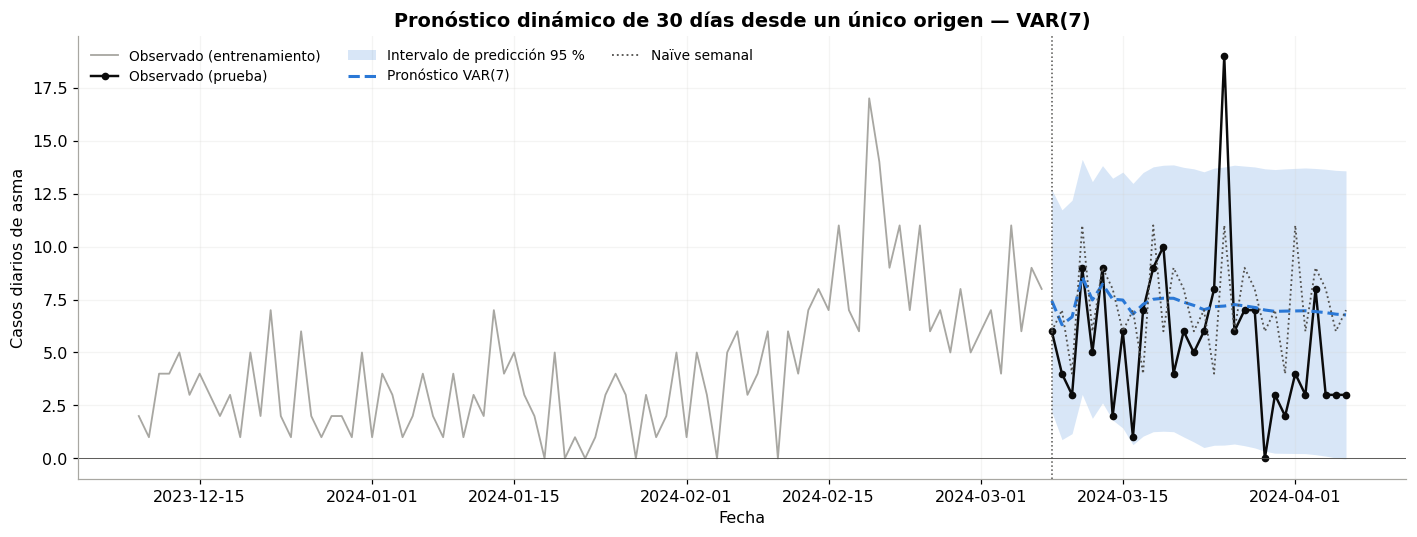

Cobertura empírica del intervalo del 95 % en el periodo de prueba: 93%
Días del pronóstico con límite inferior negativo: 1 de 30


In [43]:
train = df.iloc[:-N_TEST]
test = df.iloc[-N_TEST:]
inicio_test = len(df) - N_TEST

res_train = VAR(train).fit(P_SEL)
punto, inf95, sup95 = res_train.forecast_interval(train.values[-P_SEL:], steps=N_TEST, alpha=0.05)
fc = pd.DataFrame(punto, index=test.index, columns=train.columns)
fc_inf = pd.DataFrame(inf95, index=test.index, columns=train.columns)
fc_sup = pd.DataFrame(sup95, index=test.index, columns=train.columns)

# Referencias desde el mismo origen (pronóstico de 30 días con información hasta el final de train)
y_tr = train['asma']
ref_origen = pd.DataFrame({
    'Naïve (ŷ = último valor)': np.repeat(y_tr.iloc[-1], N_TEST),
    'Naïve semanal (ŷ = mismo día semana anterior)': [y_tr.iloc[-7 + (k % 7)] for k in range(N_TEST)],
    'Media móvil 7 días': np.repeat(y_tr.iloc[-7:].mean(), N_TEST),
    'Media histórica': np.repeat(y_tr.mean(), N_TEST)}, index=test.index)

fig, ax = plt.subplots(figsize=(13, 5))
ventana = 90
ax.plot(train.index[-ventana:], train['asma'].iloc[-ventana:], color=GRIS_CLARO, linewidth=1.2,
        label='Observado (entrenamiento)')
ax.plot(test.index, test['asma'], color='#0b0b0b', linewidth=1.6, marker='o', markersize=4,
        label='Observado (prueba)')
ax.fill_between(test.index, fc_inf['asma'], fc_sup['asma'], color=COLORES['asma'], alpha=0.18,
                linewidth=0, label='Intervalo de predicción 95 %')
ax.plot(test.index, fc['asma'], color=COLORES['asma'], linewidth=2, linestyle='--',
        label=f'Pronóstico VAR({P_SEL})')
ax.plot(test.index, ref_origen['Naïve semanal (ŷ = mismo día semana anterior)'], color=GRIS,
        linewidth=1.2, linestyle=':', label='Naïve semanal')
ax.axvline(test.index[0], color=GRIS, linestyle=':', linewidth=1)
ax.axhline(0, color=GRIS, linewidth=0.6)
ax.set(title=f'Pronóstico dinámico de 30 días desde un único origen — VAR({P_SEL})',
       xlabel='Fecha', ylabel='Casos diarios de asma')
ax.legend(frameon=False, fontsize=9, ncol=3, loc='upper left')
plt.tight_layout()
plt.show()

cobertura = ((test['asma'] >= fc_inf['asma']) & (test['asma'] <= fc_sup['asma'])).mean()
print(f'Cobertura empírica del intervalo del 95 % en el periodo de prueba: {cobertura:.0%}')
print(f'Días del pronóstico con límite inferior negativo: {int((fc_inf["asma"] < 0).sum())} de {N_TEST}')

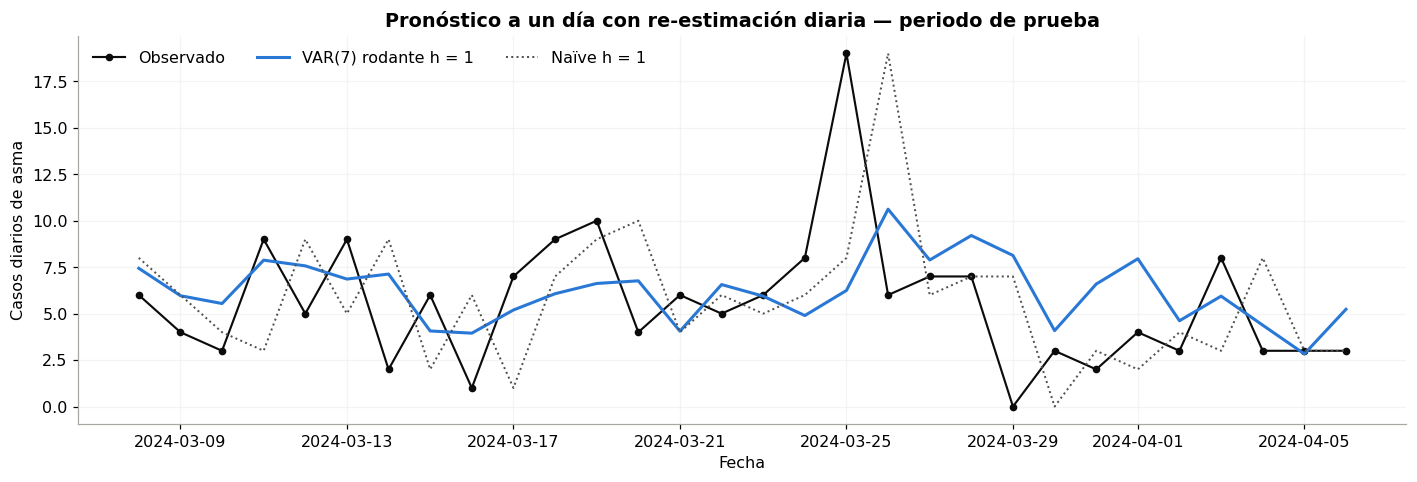

In [44]:
# Pronóstico rodante en el periodo de prueba, para todos los candidatos y referencias
y_test = df['asma'].iloc[inicio_test:]
rodantes = {}
for hh in (1, 7):
    pr = {f'VAR({p})': pronostico_rodante_var(df, p, inicio_test, len(df), h=hh) for p in CANDIDATOS}
    pr.update(pronosticos_referencia(df['asma'], inicio_test, len(df), h=hh).to_dict('series'))
    rodantes[hh] = pd.DataFrame(pr)

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(y_test.index, y_test, color='#0b0b0b', marker='o', markersize=4, linewidth=1.4, label='Observado')
ax.plot(y_test.index, rodantes[1][f'VAR({P_SEL})'], color=COLORES['asma'], linewidth=2,
        label=f'VAR({P_SEL}) rodante h = 1')
ax.plot(y_test.index, rodantes[1]['Naïve (ŷ = último valor)'], color=GRIS, linestyle=':',
        linewidth=1.3, label='Naïve h = 1')
ax.set(title='Pronóstico a un día con re-estimación diaria — periodo de prueba',
       xlabel='Fecha', ylabel='Casos diarios de asma')
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 27. Comparación contra modelos naïve

Un modelo naïve es el **piso** que cualquier modelo debe superar para justificar su complejidad. Si un VAR con decenas de parámetros no supera a "mañana será igual que hoy", no aporta valor predictivo en la práctica.

Referencias:

- **Naïve:** $\hat y_{t+h} = y_t$.
- **Naïve semanal:** $\hat y_t = y_{t-7}$ (para $h \le 7$).
- **Media móvil de 7 días** y **media histórica**: referencias aún más exigentes con series ruidosas, porque promedian el ruido.

### 🔎 Observe
> ¿El VAR seleccionado mejora frente al naïve? ¿Y frente a la media móvil de 7 días? ¿Qué le dice eso sobre la capacidad predictiva que aportan las variables ambientales?

In [45]:
def tabla_metricas(obs, predicciones, referencia='Naïve (ŷ = último valor)'):
    # Tabla MAE / RMSE / WAPE y comparación con el naïve.
    filas = []
    rmse_ref = metricas(obs, predicciones[referencia])['RMSE']
    for nombre, pred in predicciones.items():
        m = metricas(obs, pred)
        filas.append({'Modelo': nombre, 'MAE': m['MAE'], 'RMSE': m['RMSE'], 'WAPE': m['WAPE'],
                      'RMSE relativo al naïve': m['RMSE'] / rmse_ref,
                      '¿Mejora frente al naïve?': ('—' if nombre == referencia
                                                   else ('Sí' if m['RMSE'] < rmse_ref else 'No'))})
    return pd.DataFrame(filas).set_index('Modelo').sort_values('RMSE')


fmt_m = {'MAE': '{:.3f}', 'RMSE': '{:.3f}', 'WAPE': '{:.1%}', 'RMSE relativo al naïve': '{:.2f}'}
marcar = lambda t: t.style.format(fmt_m).apply(
    lambda r: ['background-color: #d9e7f8' if r.name == f'VAR({P_SEL})' else '' for _ in r], axis=1)

pred_origen = {f'VAR({P_SEL})': fc['asma'], **ref_origen.to_dict('series')}
t_origen = tabla_metricas(test['asma'], pred_origen)
t_h1 = tabla_metricas(y_test, rodantes[1].to_dict('series'))
t_h7 = tabla_metricas(y_test, rodantes[7].to_dict('series'))

print('(a) Pronóstico dinámico de 30 días desde un único origen')
display(marcar(t_origen))
print('(b) Pronóstico rodante a 1 día (re-estimación diaria)')
display(marcar(t_h1))
print('(c) Pronóstico rodante a 7 días (re-estimación diaria)')
display(marcar(t_h7))

# MAPE solo como ilustración de su problema con ceros
n_ceros_test = int((test['asma'] == 0).sum())
mask = test['asma'] > 0
mape = np.mean(np.abs((test['asma'][mask] - fc['asma'][mask]) / test['asma'][mask])) * 100
print(f'Días con cero casos en el test: {n_ceros_test}. MAPE (excluyendo esos días): {mape:.1f} % '
      '— no comparable ni interpretable como métrica principal.')

(a) Pronóstico dinámico de 30 días desde un único origen


,MAE,RMSE,WAPE,RMSE relativo al naïve,¿Mejora frente al naïve?
Modelo,,,,,
Media histórica,2.600,3.556,46.4%,0.83,Sí
Naïve semanal (ŷ = mismo día semana anterior),2.900,3.638,51.8%,0.85,Sí
VAR(7),2.864,3.757,51.1%,0.88,Sí
Media móvil 7 días,3.086,3.935,55.1%,0.92,Sí
Naïve (ŷ = último valor),3.467,4.290,61.9%,1.00,—


(b) Pronóstico rodante a 1 día (re-estimación diaria)


,MAE,RMSE,WAPE,RMSE relativo al naïve,¿Mejora frente al naïve?
Modelo,,,,,
Media histórica,2.603,3.560,46.5%,0.76,Sí
VAR(2),2.751,3.701,49.1%,0.79,Sí
VAR(7),2.834,3.731,50.6%,0.80,Sí
Media móvil 7 días,2.767,3.745,49.4%,0.80,Sí
VAR(1),2.910,3.796,52.0%,0.81,Sí
Naïve semanal (ŷ = mismo día semana anterior),3.300,4.564,58.9%,0.97,Sí
Naïve (ŷ = último valor),3.500,4.687,62.5%,1.00,—


(c) Pronóstico rodante a 7 días (re-estimación diaria)


,MAE,RMSE,WAPE,RMSE relativo al naïve,¿Mejora frente al naïve?
Modelo,,,,,
VAR(2),2.593,3.530,46.3%,0.77,Sí
VAR(1),2.609,3.557,46.6%,0.78,Sí
Media histórica,2.606,3.560,46.5%,0.78,Sí
VAR(7),2.911,3.896,52.0%,0.85,Sí
Media móvil 7 días,3.062,4.036,54.7%,0.88,Sí
Naïve (ŷ = último valor),3.300,4.564,58.9%,1.00,—


Días con cero casos en el test: 1. MAPE (excluyendo esos días): 84.4 % — no comparable ni interpretable como métrica principal.


In [46]:
def veredicto(tabla, nombre_modelo):
    fila = tabla.loc[nombre_modelo]
    refs = tabla.drop(index=[i for i in tabla.index if i.startswith('VAR(')])
    mejor_ref = refs['RMSE'].idxmin()
    return {'rmse': fila['RMSE'], 'rel_naive': fila['RMSE relativo al naïve'],
            'mejora_naive': fila['¿Mejora frente al naïve?'] == 'Sí',
            'mejor_ref': mejor_ref, 'rmse_mejor_ref': refs.loc[mejor_ref, 'RMSE'],
            'mejora_mejor_ref': fila['RMSE'] < refs.loc[mejor_ref, 'RMSE']}


modelo_sel_nombre = f'VAR({P_SEL})'
V = {'origen': veredicto(t_origen, modelo_sel_nombre), 'h1': veredicto(t_h1, modelo_sel_nombre),
     'h7': veredicto(t_h7, modelo_sel_nombre)}
RES['validacion'] = V
RES['cobertura'] = cobertura

def frase(v, etiqueta):
    return (f"{etiqueta}: RMSE = {v['rmse']:.3f} ({v['rel_naive']:.2f} × naïve); "
            f"{'mejora' if v['mejora_naive'] else 'no mejora'} frente al naïve y "
            f"{'mejora' if v['mejora_mejor_ref'] else 'no mejora'} frente a la mejor referencia "
            f"({v['mejor_ref']}, RMSE = {v['rmse_mejor_ref']:.3f}).")

informe(
    resultado=" ".join([frase(V['origen'], '**30 días desde un origen**'),
                        frase(V['h1'], '**Rodante h = 1**'), frase(V['h7'], '**Rodante h = 7**')])
              + f" Cobertura empírica del intervalo del 95 %: {cobertura:.0%}.",
    decision=("El VAR supera al naïve en todos los esquemas evaluados."
              if all(v['mejora_naive'] for v in V.values()) else
              "El VAR no supera al naïve en todos los esquemas evaluados.")
             + (" Sin embargo, **no supera a todas las referencias** (en particular, a referencias basadas en promedios): "
                "la mejora frente al naïve puede deberse en buena medida a que el VAR promedia el ruido diario, "
                "y no necesariamente a la información ambiental (que, según Granger, no aporta de forma detectable)."
                if not RES['granger_sig'] else
                " Sin embargo, **no supera a todas las referencias** (en particular, a referencias basadas en promedios): "
                "la mejora frente al naïve puede deberse en buena medida a que el VAR promedia el ruido diario."
                if not all(v['mejora_mejor_ref'] for v in V.values()) else
                " Además supera a la mejor referencia en todos los esquemas."),
    epidemiologia=("Para un sistema de vigilancia, la pregunta práctica es si el VAR justifica su complejidad. "
                   "Si su ventaja sobre una media móvil es pequeña o nula, una regla simple puede ser preferible "
                   "para la operación diaria, y el VAR se justificaría más por su valor descriptivo de la dinámica."),
    precaucion=(f"La evaluación usa solo {N_TEST} días: las diferencias entre modelos tienen mucha incertidumbre y "
                "podrían cambiar en otro periodo (por ejemplo, en temporada de virus respiratorios). Una evaluación "
                "más sólida usaría varios periodos de prueba (backtesting) y una prueba de Diebold–Mariano."))

#### Resultado
**30 días desde un origen**: RMSE = 3.757 (0.88 × naïve); mejora frente al naïve y no mejora frente a la mejor referencia (Media histórica, RMSE = 3.556). **Rodante h = 1**: RMSE = 3.731 (0.80 × naïve); mejora frente al naïve y no mejora frente a la mejor referencia (Media histórica, RMSE = 3.560). **Rodante h = 7**: RMSE = 3.896 (0.85 × naïve); mejora frente al naïve y no mejora frente a la mejor referencia (Media histórica, RMSE = 3.560). Cobertura empírica del intervalo del 95 %: 93%.

#### Decisión estadística
El VAR supera al naïve en todos los esquemas evaluados. Sin embargo, **no supera a todas las referencias** (en particular, a referencias basadas en promedios): la mejora frente al naïve puede deberse en buena medida a que el VAR promedia el ruido diario, y no necesariamente a la información ambiental (que, según Granger, no aporta de forma detectable).

#### Interpretación epidemiológica
Para un sistema de vigilancia, la pregunta práctica es si el VAR justifica su complejidad. Si su ventaja sobre una media móvil es pequeña o nula, una regla simple puede ser preferible para la operación diaria, y el VAR se justificaría más por su valor descriptivo de la dinámica.

#### Precaución
La evaluación usa solo 30 días: las diferencias entre modelos tienen mucha incertidumbre y podrían cambiar en otro periodo (por ejemplo, en temporada de virus respiratorios). Una evaluación más sólida usaría varios periodos de prueba (backtesting) y una prueba de Diebold–Mariano.

## 28. Pronóstico

Solo después de seleccionar y validar el modelo se re-estima con **todos los datos** (`var_result`, sección 18) y se pronostica un horizonte epidemiológicamente razonable: **14 días** (dos semanas, suficiente para planificar recursos y mayor que el horizonte en el que la información disponible deja de aportar).

> ⚠️ **Advertencia.** En un VAR, pronosticar el asma a varios días implica pronosticar **también** PM2.5, temperatura y precipitación con el propio VAR, y propagar esos pronósticos (y su incertidumbre). En la práctica, para las variables meteorológicas existen pronósticos externos mucho mejores; un VARX o un modelo de regresión con pronósticos meteorológicos externos podría ser más adecuado.

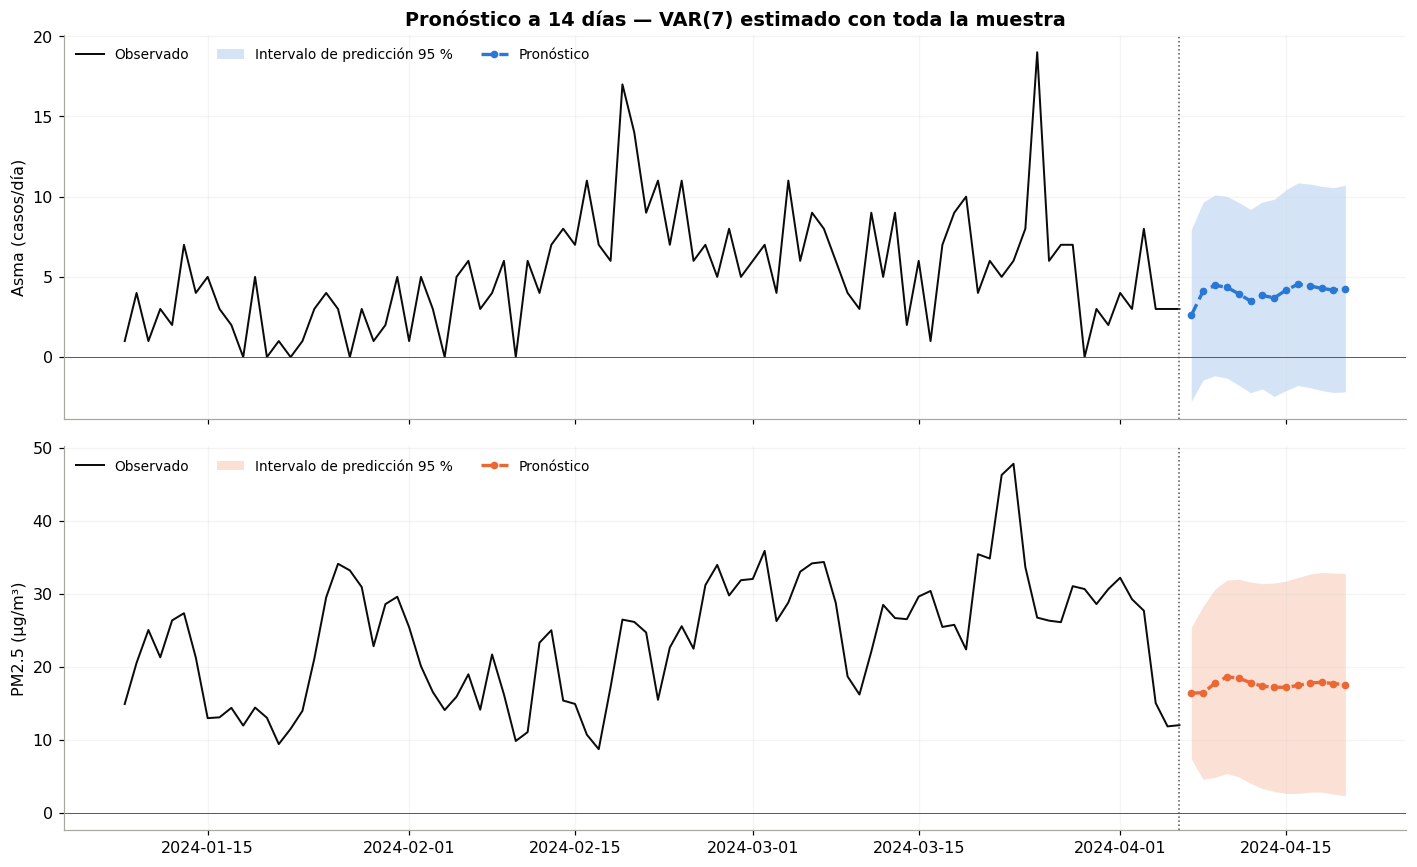

,Asma (pronóstico),IC 95 % inf,IC 95 % sup,PM2.5 (pronóstico)
Fecha,,,,
2024-04-07,2.60,-2.76,7.96,16.40
2024-04-08,4.11,-1.43,9.65,16.44
2024-04-09,4.47,-1.17,10.11,17.75
2024-04-10,4.36,-1.30,10.02,18.62
2024-04-11,3.95,-1.75,9.64,18.46
2024-04-12,3.50,-2.22,9.21,17.83
2024-04-13,3.84,-1.98,9.67,17.35
2024-04-14,3.69,-2.45,9.84,17.20
2024-04-15,4.17,-2.08,10.43,17.20


El pronóstico de asma converge hacia la media del proceso (5.53 casos/día) a medida que aumenta el horizonte, como corresponde a un VAR estable. **14 de 14** límites inferiores del intervalo son negativos: un número negativo de casos es imposible, lo que ilustra la limitación de un modelo gaussiano lineal para conteos bajos. En un reporte operativo, el límite inferior debería truncarse en cero, y lo correcto sería usar un modelo de conteo para la incertidumbre.

In [47]:
H_FUTURO = 14
punto_f, inf_f, sup_f = var_result.forecast_interval(df.values[-P_SEL:], steps=H_FUTURO, alpha=0.05)
idx_f = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=H_FUTURO, freq='D')
fut = pd.DataFrame(punto_f, index=idx_f, columns=df.columns)
fut_inf = pd.DataFrame(inf_f, index=idx_f, columns=df.columns)
fut_sup = pd.DataFrame(sup_f, index=idx_f, columns=df.columns)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, col in zip(axes, ['asma', 'pm25']):
    ax.plot(df.index[-90:], df[col].iloc[-90:], color='#0b0b0b', linewidth=1.3, label='Observado')
    ax.fill_between(idx_f, fut_inf[col], fut_sup[col], color=COLORES[col], alpha=0.2, linewidth=0,
                    label='Intervalo de predicción 95 %')
    ax.plot(idx_f, fut[col], color=COLORES[col], linewidth=2.2, linestyle='--', marker='o',
            markersize=4, label='Pronóstico')
    ax.axvline(df.index[-1], color=GRIS, linestyle=':', linewidth=1)
    ax.axhline(0, color=GRIS, linewidth=0.6)
    ax.set(ylabel=f'{ETIQUETAS[col]} ({UNIDADES[col]})')
    ax.legend(frameon=False, ncol=3, loc='upper left', fontsize=9)
axes[0].set_title(f'Pronóstico a {H_FUTURO} días — VAR({P_SEL}) estimado con toda la muestra')
plt.tight_layout()
plt.show()

tabla_fut = pd.DataFrame({'Asma (pronóstico)': fut['asma'], 'IC 95 % inf': fut_inf['asma'],
                          'IC 95 % sup': fut_sup['asma'], 'PM2.5 (pronóstico)': fut['pm25']})
tabla_fut.index = tabla_fut.index.date
tabla_fut.index.name = 'Fecha'
display(tabla_fut.round(2))
n_neg = int((fut_inf['asma'] < 0).sum())
mostrar_md(
    f"El pronóstico de asma converge hacia la media del proceso ({df['asma'].mean():.2f} casos/día) a medida "
    f"que aumenta el horizonte, como corresponde a un VAR estable. **{n_neg} de {H_FUTURO}** límites inferiores "
    "del intervalo son negativos: un número negativo de casos es imposible, lo que ilustra la limitación de un "
    "modelo gaussiano lineal para conteos bajos. En un reporte operativo, el límite inferior debería truncarse "
    "en cero, y lo correcto sería usar un modelo de conteo para la incertidumbre.")

## 29. ¿Es VAR realmente adecuado aquí?

La siguiente tabla reúne, de forma automática, la evidencia generada a lo largo del notebook.

In [48]:
v = RES['validacion']
evaluacion = pd.DataFrame([
    ('Estacionariedad', 'Evidencia mixta ADF/KPSS en: ' + (', '.join(RES['est_conflictos']) or 'ninguna'),
     'Aceptable con reservas' if RES['niveles'] else 'Problemático'),
    ('Estabilidad', f"Máx. |autovalor| = {RES['modulo_max']:.3f}",
     'Adecuado' if RES['estable'] else 'Problemático'),
    ('Autocorrelación residual', f"Portmanteau p = {fmt_p(RES['portmanteau_p'])}",
     'Adecuado' if RES['portmanteau_p'] >= ALPHA else 'Problemático'),
    ('Normalidad', f"p = {fmt_p(RES['normalidad_p'])}",
     'Adecuado' if RES['normalidad_p'] >= ALPHA else 'No se cumple (esperable en conteos)'),
    ('Heterocedasticidad en asma', f"Spearman ajustados–residuos² p = {fmt_p(RES['het_asma_p'])}",
     'Indicios de varianza dependiente del nivel' if RES['het_asma_p'] < ALPHA else 'Sin evidencia clara'),
    ('Naturaleza de conteo', f"Índice de dispersión = {indice_dispersion:.2f}; intervalos con negativos",
     'Aproximación'),
    ('Simetría endógena', 'Ecuaciones asma → ambiente sin sentido mecanístico',
     'Limitación conceptual'),
    ('Capacidad predictiva', f"RMSE rodante h=1 = {v['h1']['rel_naive']:.2f} × naïve; "
     f"{'supera' if v['h1']['mejora_mejor_ref'] else 'no supera'} a la mejor referencia ({v['h1']['mejor_ref']})",
     ('Supera al naïve y a la mejor referencia' if v['h1']['mejora_naive'] and v['h1']['mejora_mejor_ref'] else
      'Supera al naïve, pero no a la mejor referencia' if v['h1']['mejora_naive'] else
      'No supera al naïve')),
    ('Granger ambiente → asma', f"Prueba conjunta p = {fmt_p(RES['granger_conjunta_p'])}",
     'Precedencia predictiva detectada' if RES['granger_sig'] or RES['granger_conjunta_p'] < ALPHA
     else 'Sin precedencia predictiva detectable'),
], columns=['Criterio', 'Evidencia', 'Valoración']).set_index('Criterio')
with pd.option_context('display.max_colwidth', None):
    display(evaluacion)

,Evidencia,Valoración
Criterio,,
Estacionariedad,"Evidencia mixta ADF/KPSS en: Asma, PM2.5, Temperatura",Aceptable con reservas
Estabilidad,Máx. |autovalor| = 0.959,Adecuado
Autocorrelación residual,Portmanteau p = 0.067,Adecuado
Normalidad,p = < 0.001,No se cumple (esperable en conteos)
Heterocedasticidad en asma,Spearman ajustados–residuos² p = < 0.001,Indicios de varianza dependiente del nivel
Naturaleza de conteo,Índice de dispersión = 2.14; intervalos con negativos,Aproximación
Simetría endógena,Ecuaciones asma → ambiente sin sentido mecanístico,Limitación conceptual
Capacidad predictiva,RMSE rodante h=1 = 0.80 × naïve; no supera a la mejor referencia (Media histórica),"Supera al naïve, pero no a la mejor referencia"
Granger ambiente → asma,Prueba conjunta p = 0.284,Sin precedencia predictiva detectable


### ¿Cuándo NO utilizaría VAR para este problema?

- Cuando el objetivo principal es **estimar el efecto de PM2.5 sobre el riesgo de asma** (por ejemplo, "riesgo relativo por cada 10 µg/m³"): el estándar es una regresión de Poisson/binomial negativa con rezagos distribuidos (DLNM), control de tendencia, estacionalidad, día de la semana y festivos.
- Cuando los **conteos son muy bajos** (muchos ceros): la aproximación gaussiana empeora y los intervalos pierden sentido.
- Cuando las variables ambientales son claramente **exógenas** y se dispone de sus pronósticos externos: un VARX o un modelo de regresión es más coherente y parsimonioso.
- Cuando se sospechan **efectos no lineales o de umbral** (por ejemplo, solo los días de contaminación alta importan, o la temperatura tiene efecto en "U"): GAM o DLNM.
- Cuando se quieren incluir **muchas variables** (otras enfermedades respiratorias, PM10, ozono, varias localidades): el número de parámetros explota; se requieren VAR bayesianos, regularizados o modelos de factores.
- Cuando el interés es **causal**: se requiere un diseño (por ejemplo, *case-crossover*, series temporales interrumpidas, variables instrumentales) y una identificación explícita.

## 30. Alternativas metodológicas: VAR versus modelos alternativos

| Objetivo | Método posible |
|---|---|
| Interdependencia multivariada entre series | VAR |
| Casos diarios de conteo | Regresión Poisson / binomial negativa |
| Efectos retardados ambientales | Modelo de rezagos distribuidos (DLM / DLNM) |
| Relaciones no lineales, control de estacionalidad | GAM |
| Variables ambientales exógenas con pronóstico externo | VARX / regresión dinámica / SARIMAX |
| Dinámica de conteos | Modelos INGARCH, Poisson autorregresivo, espacio-estado |
| Series con raíz unitaria que comparten tendencia estocástica | Cointegración / VECM |
| Muchas variables o pocas observaciones | VAR bayesiano, VAR regularizado (LASSO) |
| Identificación causal estructural | Requiere diseño e identificación adicional (restricciones justificadas, instrumentos, experimentos naturales) |

> **Mensaje central:** seleccionar una técnica depende de la **pregunta** y de la **naturaleza de los datos**, no de la popularidad del método.

## 31. Conclusiones

Las respuestas siguientes se generan a partir de los resultados calculados. No se asume que el VAR "funcionó bien": cada respuesta reporta la evidencia.

In [49]:
lista = lambda xs: ', '.join(xs) if xs else 'ninguna'
v = RES['validacion']
rA, rB = RES['cholesky_detalle']
fA = RES['fevd_A']
h7 = 7 if 7 in fA.index else fA.index[0]

conclusiones = [
    ('1. ¿Las series parecen compatibles con los requisitos del modelo?',
     f"Parcialmente. ADF rechaza la raíz unitaria con constante "
     f"{'en todas las series' if not RES['est_raiz_unitaria'] else 'salvo en ' + lista(RES['est_raiz_unitaria'])}, "
     f"pero KPSS rechaza la estacionariedad en nivel para {lista(RES['est_conflictos'])} (evidencia mixta). "
     f"Con tendencia, ADF no rechaza para {lista(RES['est_adf_ct_no_rechaza'])}. "
     "Se modeló en niveles como decisión de trabajo, con verificación de estabilidad."),
    ('2. ¿Qué orden VAR fue seleccionado y por qué?',
     f"VAR({RES['p']}), por una regla explícita que combina estabilidad, adecuación residual, parsimonia, "
     f"lógica temporal y error de validación; no por un único criterio de información "
     f"(BIC = {seleccion.bic}, HQIC = {seleccion.hqic}, AIC = {seleccion.aic}). "
     + (f"Ningún candidato superó Portmanteau en la muestra de selección; VAR({RES['p']}) fue el de menor "
        f"autocorrelación residual (p = {fmt_p(RES['port_p_seleccion'])})."
        if RES['seleccion_respaldo'] else
        f"Fue el más parsimonioso entre los modelos sin autocorrelación residual detectada.")),
    ('3. ¿El modelo es estable?',
     f"{'Sí' if RES['estable'] else 'No'}: máximo |autovalor| de la matriz compañera = {RES['modulo_max']:.3f}."),
    ('4. ¿Los residuos conservan autocorrelación?',
     f"Portmanteau (rezago {NLAGS_PORT}, muestra completa) p = {fmt_p(RES['portmanteau_p'])}: "
     + ("no hay evidencia suficiente de autocorrelación residual" if RES['portmanteau_p'] >= ALPHA
        else "se rechaza la ausencia de autocorrelación; la inferencia debe tomarse con cautela")
     + f" (muestra de selección: p = {fmt_p(RES['port_p_seleccion'])}"
     + ("; la adecuación es marginal)." if (RES['port_p_seleccion'] < ALPHA) != (RES['portmanteau_p'] < ALPHA)
        else ").")),
    ('5. ¿Se cumple normalidad?',
     f"{'No' if RES['normalidad_p'] < ALPHA else 'No se rechaza'} (p = {fmt_p(RES['normalidad_p'])}). "
     "Afecta sobre todo a los intervalos de predicción; es esperable para conteos y lluvia."),
    ('6. ¿Alguna variable aporta capacidad predictiva sobre asma?',
     (f"Hay evidencia de precedencia predictiva (Granger) para {lista(RES['granger_sig'])}."
      if RES['granger_sig'] else
      "No se encontró evidencia, al 5 %, de que los rezagos de PM2.5, temperatura o precipitación "
      "mejoren la predicción de asma.")
     + f" Prueba conjunta: p = {fmt_p(RES['granger_conjunta_p'])}."),
    ('7. ¿Qué muestran las IRF?',
     f"PM2.5 → Asma: banda al 95 % excluye el cero en los horizontes {rA['horizontes_signif'] or 'ninguno'} "
     f"(orden A) y {rB['horizontes_signif'] or 'ninguno'} (orden B). "
     + ("La conclusión cambia con el orden solo de forma marginal (horizontes aislados); las respuestas son "
        "pequeñas y cercanas a cero en ambos órdenes y en la GIRF." if RES['cholesky_cambia'] and RES['cholesky_aislado']
        else "La conclusión depende del orden de Cholesky." if RES['cholesky_cambia']
        else "La conclusión cualitativa no depende del orden evaluado.")
     + f" Asma → Asma muestra persistencia propia, con picos en múltiplos de 7 días si existe patrón semanal."),
    ('8. ¿Qué muestra la FEVD?',
     f"A {h7} días, {fA.loc[h7, 'Asma']:.1f} % de la varianza del error de pronóstico de asma se asocia a sus "
     f"propias innovaciones y {fA.loc[h7, 'PM2.5']:.1f} % a PM2.5 (orden A)."),
    ('9. ¿El VAR supera un pronóstico naïve?',
     f"A 1 día (rodante): {'sí' if v['h1']['mejora_naive'] else 'no'} ({v['h1']['rel_naive']:.2f} × RMSE naïve); "
     f"a 7 días: {'sí' if v['h7']['mejora_naive'] else 'no'}; a 30 días desde un origen: "
     f"{'sí' if v['origen']['mejora_naive'] else 'no'}. Frente a la mejor referencia a 1 día "
     f"({v['h1']['mejor_ref']}): {'sí la supera' if v['h1']['mejora_mejor_ref'] else 'no la supera'}."),
    ('10. ¿Qué limitaciones impiden realizar afirmaciones causales?',
     "Datos observacionales; confusión no controlada (estacionalidad, virus respiratorios, festivos, cambios en "
     "la notificación); identificación de Cholesky arbitraria; linealidad y aproximación gaussiana para un "
     "conteo; periodo corto (~15 meses); multiplicidad de pruebas; y el hecho de que Granger mide precedencia "
     "predictiva, no efecto de intervención."),
]
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(conclusiones, columns=['Pregunta', 'Respuesta con evidencia']).set_index('Pregunta'))

,Respuesta con evidencia
Pregunta,
1. ¿Las series parecen compatibles con los requisitos del modelo?,"Parcialmente. ADF rechaza la raíz unitaria con constante en todas las series, pero KPSS rechaza la estacionariedad en nivel para Asma, PM2.5, Temperatura (evidencia mixta). Con tendencia, ADF no rechaza para Asma. Se modeló en niveles como decisión de trabajo, con verificación de estabilidad."
2. ¿Qué orden VAR fue seleccionado y por qué?,"VAR(7), por una regla explícita que combina estabilidad, adecuación residual, parsimonia, lógica temporal y error de validación; no por un único criterio de información (BIC = 1, HQIC = 2, AIC = 7). Ningún candidato superó Portmanteau en la muestra de selección; VAR(7) fue el de menor autocorrelación residual (p = 0.015)."
3. ¿El modelo es estable?,Sí: máximo |autovalor| de la matriz compañera = 0.959.
4. ¿Los residuos conservan autocorrelación?,"Portmanteau (rezago 20, muestra completa) p = 0.067: no hay evidencia suficiente de autocorrelación residual (muestra de selección: p = 0.015; la adecuación es marginal)."
5. ¿Se cumple normalidad?,No (p = < 0.001). Afecta sobre todo a los intervalos de predicción; es esperable para conteos y lluvia.
6. ¿Alguna variable aporta capacidad predictiva sobre asma?,"No se encontró evidencia, al 5 %, de que los rezagos de PM2.5, temperatura o precipitación mejoren la predicción de asma. Prueba conjunta: p = 0.284."
7. ¿Qué muestran las IRF?,"PM2.5 → Asma: banda al 95 % excluye el cero en los horizontes ninguno (orden A) y [6] (orden B). La conclusión cambia con el orden solo de forma marginal (horizontes aislados); las respuestas son pequeñas y cercanas a cero en ambos órdenes y en la GIRF. Asma → Asma muestra persistencia propia, con picos en múltiplos de 7 días si existe patrón semanal."
8. ¿Qué muestra la FEVD?,"A 7 días, 97.0 % de la varianza del error de pronóstico de asma se asocia a sus propias innovaciones y 0.9 % a PM2.5 (orden A)."
9. ¿El VAR supera un pronóstico naïve?,A 1 día (rodante): sí (0.80 × RMSE naïve); a 7 días: sí; a 30 días desde un origen: sí. Frente a la mejor referencia a 1 día (Media histórica): no la supera.


### Mensaje final

El VAR es una herramienta útil para **describir la interdependencia dinámica** de un sistema de vigilancia y para obtener un **punto de referencia** de pronóstico multivariado. En este caso, el análisis riguroso exige:

- reconocer la evidencia **mixta** de estacionariedad, en lugar de declarar estacionarias todas las series;
- elegir $p$ con argumentos (no con un criterio aislado) y **usar realmente** el $p$ elegido en todo el análisis;
- verificar estabilidad **antes** de las IRF y la FEVD;
- hablar de **precedencia predictiva**, no de causalidad;
- reconocer que IRF y FEVD dependen de la **identificación**;
- comparar contra referencias simples antes de afirmar que el modelo "pronostica bien";
- aceptar el resultado que entregan los datos, sea o no "significativo".

## 32. Actividad para estudiantes

Responda priorizando la **interpretación**. Use las tablas y gráficos del notebook como evidencia.

1. ¿Por qué ADF y KPSS pueden producir conclusiones aparentemente contradictorias? ¿Qué hizo este notebook ante el conflicto y por qué no diferenció automáticamente?
2. ¿Qué razones justificarían elegir VAR(7) sobre VAR(1), aunque el BIC prefiera VAR(1)? ¿Qué argumentos irían en contra?
3. ¿Qué significa que la prueba de Portmanteau tenga $p > 0.05$? ¿Qué **no** significa?
4. ¿Puede concluirse causalidad epidemiológica a partir de una prueba de Granger significativa? Justifique con al menos dos argumentos.
5. ¿Por qué el orden de las variables afecta una IRF ortogonalizada? ¿Qué orden propondría usted y qué supuesto contemporáneo implica?
6. ¿Qué significa que PM2.5 explique un 10 % de la varianza del error de pronóstico de asma a siete días? Redacte la frase correcta y una frase incorrecta frecuente.
7. ¿Por qué un modelo naïve debe utilizarse como referencia? Según la sección 27, ¿el VAR seleccionado justifica su complejidad?
8. Si el principal objetivo fuera estimar el efecto del PM2.5 sobre el número diario de casos, ¿qué modelo consideraría y qué variables de control incluiría?

**Ejercicio práctico opcional:** modifique `ORDEN_B` por otro orden que considere razonable, ejecute de nuevo las secciones 24–25 y discuta si cambian las conclusiones.

---

<details>
<summary><b>📘 Respuestas orientadoras para el docente (clic para desplegar)</b></summary>

**1.** ADF tiene $H_0$ de raíz unitaria y KPSS $H_0$ de estacionariedad. Ambas pueden rechazar si la serie no tiene raíz unitaria pero tampoco es estacionaria "limpia" en nivel: tendencias, ciclos lentos (estacionalidad anual con menos de dos ciclos observados), cambios de nivel o memoria larga. También influyen la potencia, el número de rezagos y la especificación determinística. Diferenciar una serie sin raíz unitaria sobrediferencia (MA no invertible) y destruye la información de nivel; por eso se complementa con gráficos, media/varianza móviles, ACF y conocimiento del proceso, y luego se verifica la estabilidad del VAR.

**2.** A favor de VAR(7): datos diarios con patrón semanal en la atención; VAR(1) y VAR(2) pueden dejar autocorrelación residual (ver Portmanteau y Ljung–Box en rezagos 7 y 14), lo que invalida la inferencia de Granger e IRF; AIC suele favorecer órdenes altos (verifique en la sección 16). Si ni siquiera VAR(7) elimina toda la autocorrelación, eso también es información: la dinámica puede requerir variables de calendario. En contra: muchos más parámetros (116 frente a 20), menor potencia en las pruebas, mayor varianza de los pronósticos; BIC lo penaliza. La decisión combina criterios y debe ser explícita.

**3.** Que no hay evidencia suficiente para rechazar la ausencia de autocorrelación residual hasta el rezago evaluado. No significa que se haya demostrado que los residuos son ruido blanco; la prueba tiene potencia limitada y su resultado depende del número de rezagos evaluados.

**4.** No. Granger mide precedencia predictiva dentro del sistema incluido: (a) un confusor omitido que afecte a ambas series con distinto retraso puede generarla; (b) no hay intervención ni control del diseño; (c) puede aparecer en direcciones sin sentido mecanístico (asma → ambiente); (d) depende del número de rezagos y de la especificación. La causalidad requiere diseño, plausibilidad biológica, consistencia con otros estudios, etc.

**5.** Cholesky impone una estructura recursiva contemporánea: la primera variable puede afectar a todas el mismo día y no recibe efectos contemporáneos. Si las innovaciones están correlacionadas, el orden decide a qué shock se atribuye esa correlación. Un orden razonable: precipitación, temperatura, PM2.5, asma (la meteorología afecta la dispersión de contaminantes; el asma no afecta al ambiente). Implica, por ejemplo, que el PM2.5 de hoy no afecta la lluvia de hoy.

**6.** Correcta: "a siete días, aproximadamente el 10 % de la varianza del error de pronóstico de los casos de asma se asocia a innovaciones (ortogonalizadas, bajo el orden elegido) en PM2.5". Incorrecta: "el 10 % de los casos de asma son causados por el PM2.5".

**7.** Porque define el piso mínimo de desempeño: si un modelo complejo no supera a "mañana igual que hoy" o a una media móvil, no aporta valor práctico. La respuesta a la segunda parte debe basarse en la tabla de la sección 27: con series de conteo ruidosas, las referencias basadas en promedios suelen ser difíciles de superar, y la ventaja del VAR frente al naïve puede deberse a que suaviza el ruido más que a la información ambiental.

**8.** Regresión de Poisson cuasi-verosímil o binomial negativa con rezagos distribuidos (DLNM) para PM2.5, con *splines* de tiempo para tendencia y estacionalidad, indicadores de día de la semana y festivos, temperatura (posiblemente no lineal y rezagada), precipitación y, si se dispone, indicadores de circulación de virus respiratorios. Los efectos se reportan como riesgo relativo por cada 10 µg/m³.

</details>